### Run this notebook online

[![Open in Colab](https://img.shields.io/badge/Open_in-Colab-F9AB00?logo=googlecolab&logoColor=F9AB00)](https://colab.research.google.com/github/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/blob/main/files/notebooks/CIFAR10%20DiT.ipynb)
[![Open in Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://www.kaggle.com/kernels/welcome?src=https%3A%2F%2Fgithub.com%2Fhosein-fanai%2FContinual-Learning-with-Diffusion-Vision-Transformers%2Fblob%2Fmain%2Ffiles%2Fnotebooks%2FCIFAR10%2520DiT.ipynb)
[![Launch Binder](https://img.shields.io/badge/launch-binder-F5793A?logo=jupyter&logoColor=white)](https://mybinder.org/v2/gh/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/main?urlpath=lab%2Ftree%2Ffiles%2Fnotebooks%2FCIFAR10%20DiT.ipynb)

- **Google Colab:** open the notebook, select a GPU for training under **Runtime > Change runtime type**, then choose **Run all**.
- **Kaggle:** sign in and import the notebook, enable **Internet**, select a **GPU** accelerator for training, then **Run all**.
- **Binder:** opens a temporary CPU JupyterLab session. Use it to inspect the notebook or run small checks; full training needs more resources.
- **[Studio Lab](https://studiolab.sagemaker.aws/import/github/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/blob/main/files/notebooks/CIFAR10%20DiT.ipynb) (existing accounts only):** start a runtime, copy the notebook to your project, select a Python **3.11–3.13** kernel, and set `RUNTIME = "studiolab"` in the first code cell before **Run all**. For CPU, also set `CUDA = False`.

The **first code cell** finds or downloads the repository and prepares TensorFlow **2.20** / Keras **3.11.2** before project imports. If setup requests a restart, restart the kernel and run all again. For another hosted Jupyter service, set `RUNTIME = "hosted"` (`CUDA = False` for CPU or compatible provider-managed CUDA). Locally, select the project TensorFlow kernel.

Launch links open the published GitHub `main` version; publish this notebook and its setup files together before using them. For a notebook that has not been published, upload its `.ipynb` file to Colab or Kaggle instead. GPU availability depends on the provider. Save checkpoints and results before a temporary session ends.

See the [hosted runtime guide](https://github.com/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/blob/main/files/notebooks/thesis/README.md#hosted-runtimes) for setup and import details.


In [1]:
"""Prepare a notebook checkout and runtime before importing scientific packages.

This canonical first-cell source is copied into maintained notebooks and generated
HPO notebooks. Edit REVISION/RUNTIME/CUDA before execution when needed. Existing
checkouts are reused without fetching; only missing setup code is downloaded.
ROOT is the selected absolute pathlib.Path; RUNTIME_PACKAGES maps package names
to installed version strings. Preparation may clone/install under the selected
policy and changes cwd/import paths through files.notebooks.init.prepare_notebook.
"""
from pathlib import Path
from urllib.request import urlopen


CHECKOUT_NAME = "Continual-Learning-with-Diffusion-Vision-Transformers"
REPOSITORY = f"https://github.com/hosein-fanai/{CHECKOUT_NAME}.git"
REVISION = "main"
RUNTIME = "local"  # Use "hosted" for another online service, or "local" to verify only.
CUDA = None  # False: CPU or managed CUDA; True: retain CUDA pip dependencies.

_locations = (Path.cwd(), *Path.cwd().parents, Path.cwd() / CHECKOUT_NAME, 
              Path("/kaggle/working") / CHECKOUT_NAME, Path("/content") / CHECKOUT_NAME)
_initializer = next((path / "files" / "notebooks" / "init.py" for path in _locations
                     if (path / "files" / "notebooks" / "init.py").is_file()), None)
_url = f"https://raw.githubusercontent.com/hosein-fanai/{CHECKOUT_NAME}/{REVISION}/files/notebooks/init.py"
_setup = {"__name__": "notebook_setup", "__file__": str(_initializer or _url)}
with (_initializer.open("rb") if _initializer else urlopen(_url, timeout=30)) as _file:
    exec(compile(_file.read(), _setup["__file__"], "exec"), _setup)
ROOT, RUNTIME_PACKAGES = _setup["prepare_notebook"](
    checkout_name=CHECKOUT_NAME, 
    repository=REPOSITORY, 
    revision=REVISION, 
    runtime=RUNTIME, 
    cuda=CUDA
)

Repository ready: /workspace/continual_learning_with_diffusion_vision_transformers (runtime: local)
Runtime packages ready: Python 3.12.3, TensorFlow 2.20.0, Keras 3.11.2


In [2]:
from common import utils


utils.init()

2026-10-15 12:55:29.663656: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## Experiment settings


In [3]:
stages_num = 10
epochs = 50
val_freq = 5

## CIFAR10 data


In [4]:
from common.dataloader import load_cifar10, get_dataset


x_train, y_train, _, _, x_test, y_test = load_cifar10(
    indices=None, 
    validation_ratio=0.0, 
    verbose=0
)

trainset = get_dataset(x_train, y_train.reshape(-1))
valset = get_dataset(x_test, y_test.reshape(-1), shuffle_buffer=0, drop_remainder=False)

2026-10-15 12:55:45.128203: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
I0000 00:00:1792068945.129384 1048744 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 79190 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:10:00.0, compute capability: 8.0


## DiT denoiser


In [5]:
from diffusion.models.transformer.diffusion_transformer import DiffusionTransformer
from diffusion.models.wrapper.diffusion_model import DiffusionModel


vit = DiffusionTransformer(
    image_size=32, 
    channels=3, 
    dim=128, 
    depth=6, 
    mha_num_heads=4, 
    patchify_with_cnn=True, 
    use_refiner_cnn=True
)
model = DiffusionModel(network=vit, p_uncond=0.2)

vit.summary()

Model: "diffusion_transformer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ depth_0_patch_embedder          │ (None, 256, 128)       │        75,648 │
│ (PatchEmbedding)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_time_embedder           │ (None, 128)            │       128,000 │
│ (ConditionEmbedding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_label_embedder          │ (None, 128)            │         1,408 │
│ (ConditionEmbedding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_time_label_merger (Add) │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_1_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_2_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_3_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_4_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_5_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_6_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ unpatchifier (Functional)       │ (None, 32, 32, 3)      │        41,615 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,027,699 (7.74 MB)

 Trainable params: 1,899,663 (7.25 MB)

 Non-trainable params: 128,036 (500.28 KB)

## Optimizer


In [6]:
from tensorflow.keras import optimizers


lr_schedule = optimizers.schedules.CosineDecay(
    initial_learning_rate=0.004845009591308682, # 5e-3
    decay_steps=(stages_num+1) * epochs * len(trainset) 
)

model.compile(
    optimizer=optimizers.Adam(
        lr_schedule, 
        global_clipnorm=1.0
    ), 
    loss="mse"
)

In [7]:
from tensorflow.keras import callbacks

from common.callbacks.lr_logger import LrLogger

from diffusion.callbacks.image_generator import ImageGenerator


callbacks_list = [
    LrLogger(), 
    callbacks.ProgbarLogger(), 
    ImageGenerator(frequency=val_freq)
]

## Training


Progressive stage 1/10: changes={'timesteps': (988, 1000)}, resolution=32, sampling t in [988, 1000) range.
Epoch 1/50


2026-10-15 12:56:06.063341: I external/local_xla/xla/service/service.cc:163] XLA service 0x7b8700016750 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-15 12:56:06.063366: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA A100-SXM4-80GB, Compute Capability 8.0
2026-10-15 12:56:06.455213: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-10-15 12:56:08.445825: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91002
2026-10-15 12:56:09.729751: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-15 12:56:09.730044: I ext

  3/390 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - noise_loss: 0.9766   

I0000 00:00:1792068989.802332 1049397 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


390/390 ━━━━━━━━━━━━━━━━━━━━ 50s 29ms/step - noise_loss: 0.0337 - learning_rate: 0.0048
Epoch 2/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 6.6308e-04 - learning_rate: 0.0048
Epoch 3/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 4.6884e-04 - learning_rate: 0.0048
Epoch 4/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.1719e-04 - learning_rate: 0.0048
Epoch 5/50
389/390 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - noise_loss: 3.4291e-04

2026-10-15 12:57:28.289364: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot', 4 bytes spill stores, 4 bytes spill loads

2026-10-15 12:57:28.414900: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_6', 276 bytes spill stores, 276 bytes spill loads

2026-10-15 12:57:35.159051: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-15 12:57:35.801095: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_172', 32 bytes spill

390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 69ms/step - noise_loss: 3.8666e-04 - val_image_loss: 1.4965 - val_loss: 0.1959 - val_noise_loss: 0.1959 - learning_rate: 0.0048
Steps: 50/50


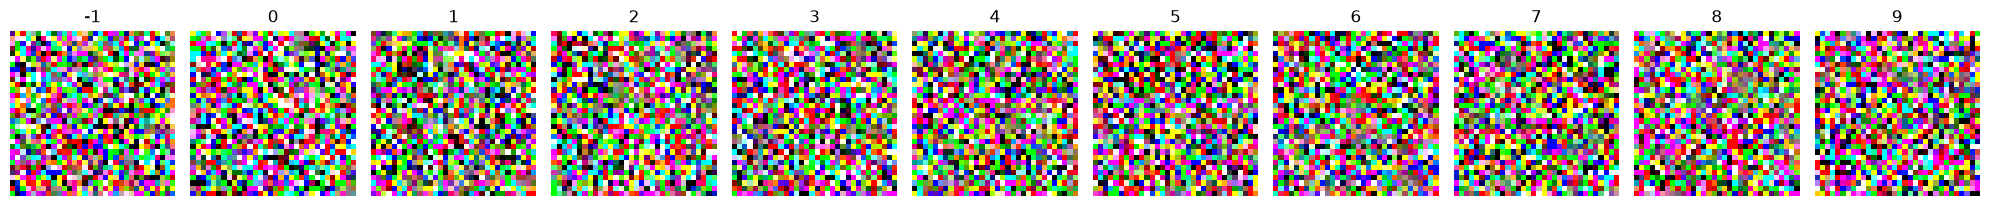

Epoch 6/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 3.3795e-04 - learning_rate: 0.0048
Epoch 7/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 3.3082e-04 - learning_rate: 0.0048
Epoch 8/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.2956 - learning_rate: 0.0048
Epoch 9/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 9.7923e-04 - learning_rate: 0.0048
Epoch 10/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 25s 65ms/step - noise_loss: 5.1995e-04 - val_image_loss: 15.9222 - val_loss: 0.6110 - val_noise_loss: 0.6110 - learning_rate: 0.0048
Steps: 50/50


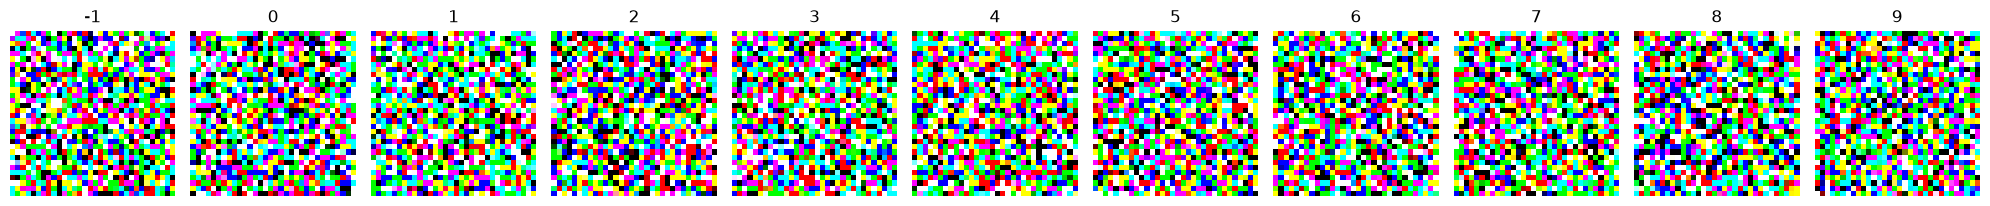

Epoch 11/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 4.1208e-04 - learning_rate: 0.0048
Epoch 12/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - noise_loss: 3.6560e-04 - learning_rate: 0.0048
Epoch 13/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 3.3911e-04 - learning_rate: 0.0048
Epoch 14/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 3.1694e-04 - learning_rate: 0.0048
Epoch 15/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 25s 63ms/step - noise_loss: 3.2974e-04 - val_image_loss: 7.8191 - val_loss: 1.1812 - val_noise_loss: 1.1812 - learning_rate: 0.0048
Steps: 50/50


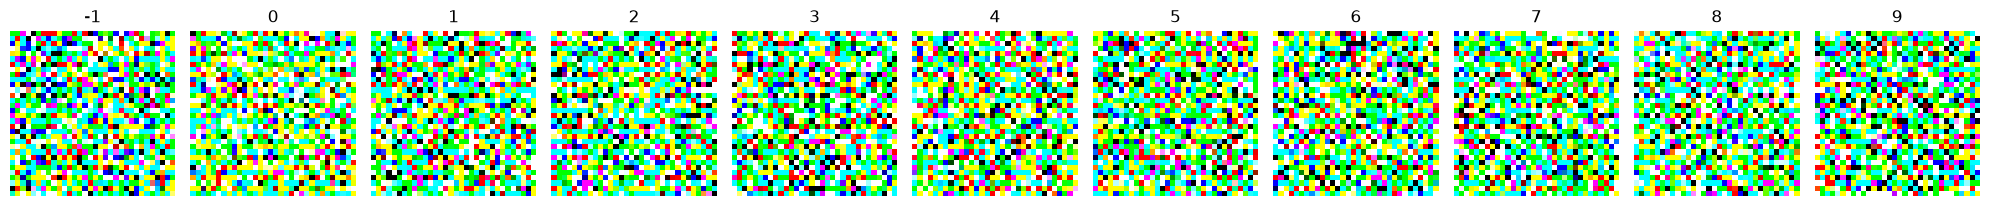

Epoch 16/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 3.0791e-04 - learning_rate: 0.0048
Epoch 17/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 3.2435e-04 - learning_rate: 0.0048
Epoch 18/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 2.8886e-04 - learning_rate: 0.0048
Epoch 19/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 2.9644e-04 - learning_rate: 0.0048
Epoch 20/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 24s 63ms/step - noise_loss: 2.9614e-04 - val_image_loss: 8.4935 - val_loss: 1.1822 - val_noise_loss: 1.1822 - learning_rate: 0.0048
Steps: 50/50


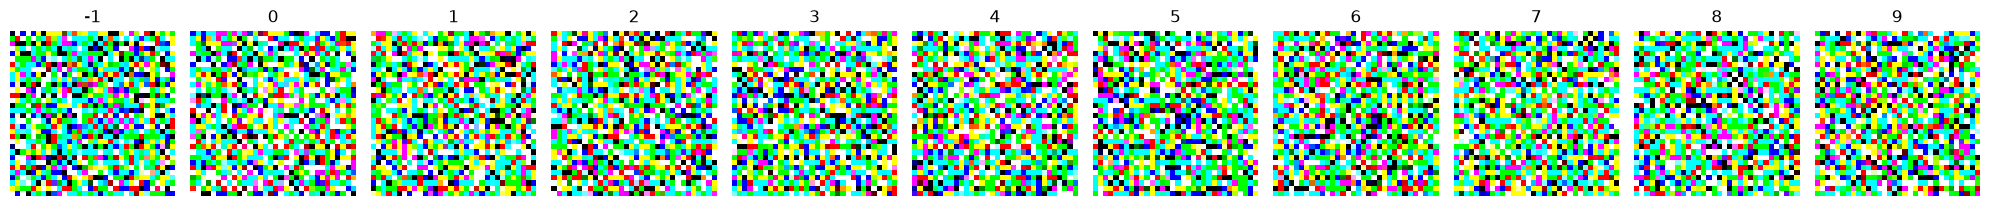

Epoch 21/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 2.9346e-04 - learning_rate: 0.0048
Epoch 22/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 2.9808e-04 - learning_rate: 0.0048
Epoch 23/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 2.6229e-04 - learning_rate: 0.0048
Epoch 24/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 2.7567e-04 - learning_rate: 0.0048
Epoch 25/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 25s 65ms/step - noise_loss: 2.6839e-04 - val_image_loss: 7.8504 - val_loss: 1.0486 - val_noise_loss: 1.0486 - learning_rate: 0.0048
Steps: 50/50


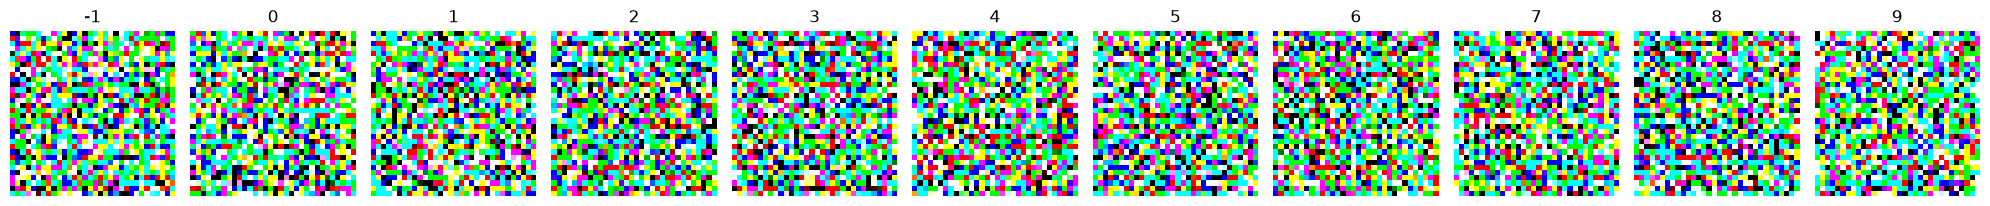

Epoch 26/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 2.6898e-04 - learning_rate: 0.0048
Epoch 27/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 2.6176e-04 - learning_rate: 0.0048
Epoch 28/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.6124e-04 - learning_rate: 0.0048
Epoch 29/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 2.1538e-04 - learning_rate: 0.0048
Epoch 30/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 25s 65ms/step - noise_loss: 2.3632e-04 - val_image_loss: 7.8692 - val_loss: 0.9296 - val_noise_loss: 0.9296 - learning_rate: 0.0048
Steps: 50/50


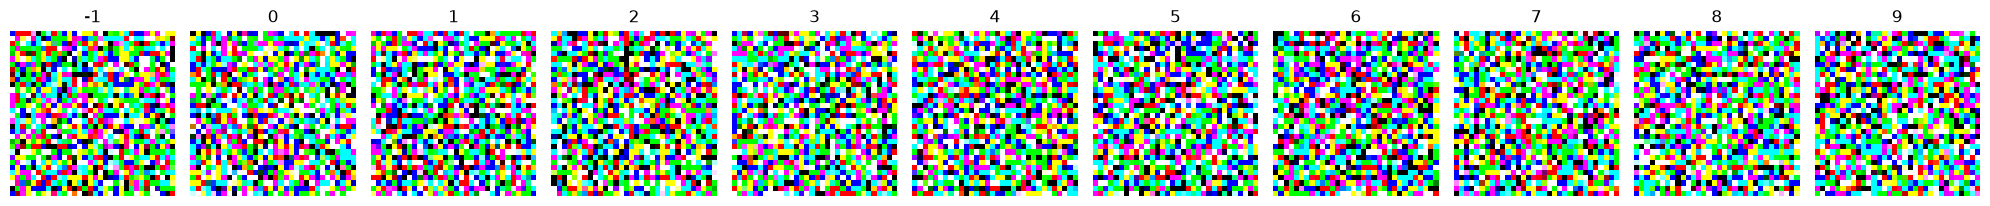

Epoch 31/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 2.5044e-04 - learning_rate: 0.0048
Epoch 32/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 2.4786e-04 - learning_rate: 0.0048
Epoch 33/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 2.5039e-04 - learning_rate: 0.0048
Epoch 34/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 2.3640e-04 - learning_rate: 0.0048
Epoch 35/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 25s 64ms/step - noise_loss: 2.4526e-04 - val_image_loss: 7.3845 - val_loss: 0.8939 - val_noise_loss: 0.8939 - learning_rate: 0.0048
Steps: 50/50


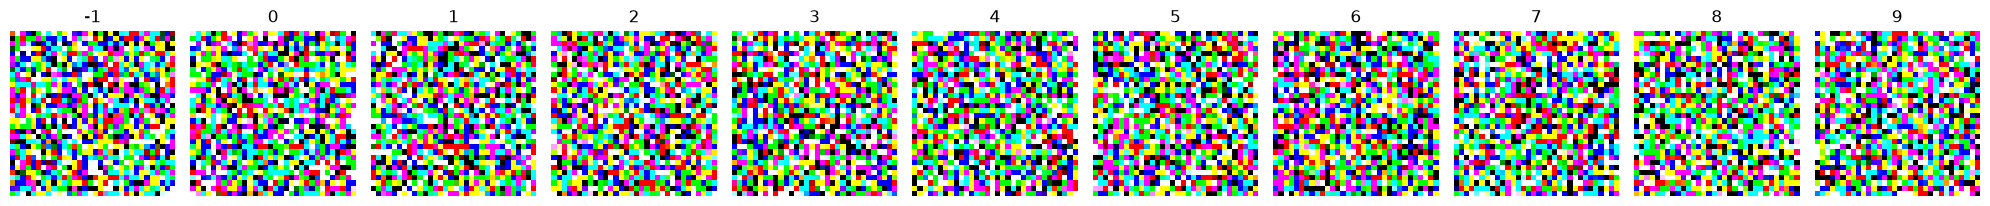

Epoch 36/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 2.3467e-04 - learning_rate: 0.0048
Epoch 37/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0847 - learning_rate: 0.0048
Epoch 38/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 5.3903e-04 - learning_rate: 0.0048
Epoch 39/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 3.0333e-04 - learning_rate: 0.0048
Epoch 40/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 25s 64ms/step - noise_loss: 2.6520e-04 - val_image_loss: 9.3040 - val_loss: 1.5478 - val_noise_loss: 1.5478 - learning_rate: 0.0048
Steps: 50/50


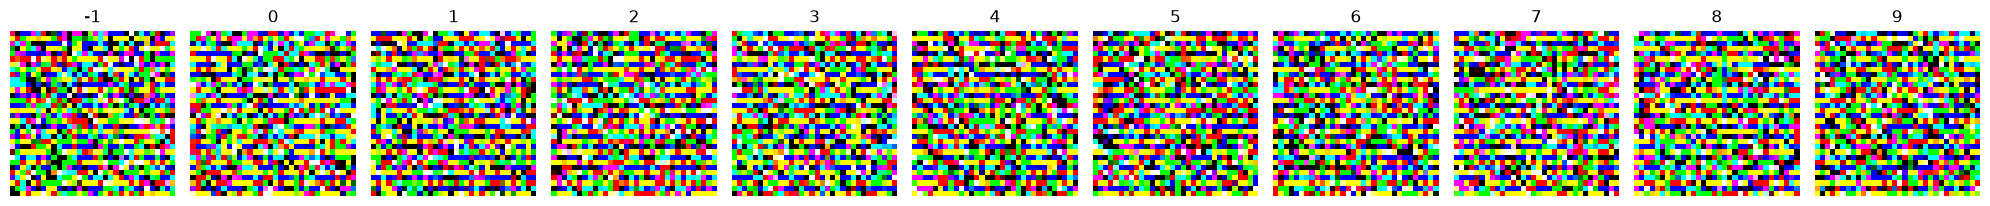

Epoch 41/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 2.5308e-04 - learning_rate: 0.0048
Epoch 42/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 2.4788e-04 - learning_rate: 0.0048
Epoch 43/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 2.4987e-04 - learning_rate: 0.0048
Epoch 44/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 2.4640e-04 - learning_rate: 0.0048
Epoch 45/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 25s 65ms/step - noise_loss: 2.4416e-04 - val_image_loss: 10.7162 - val_loss: 2.3120 - val_noise_loss: 2.3120 - learning_rate: 0.0048
Steps: 50/50


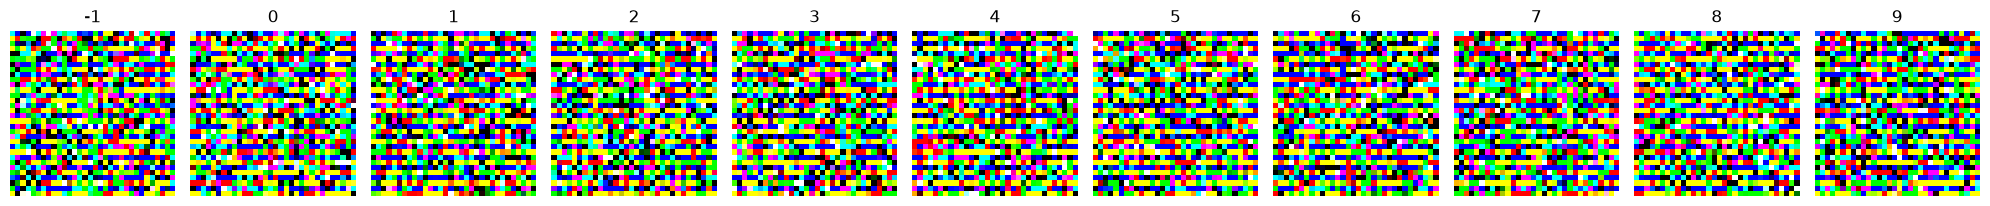

Epoch 46/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 2.5315e-04 - learning_rate: 0.0048
Epoch 47/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 2.6154e-04 - learning_rate: 0.0048
Epoch 48/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 2.6155e-04 - learning_rate: 0.0048
Epoch 49/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 2.6701e-04 - learning_rate: 0.0048
Epoch 50/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 25s 65ms/step - noise_loss: 2.4391e-04 - val_image_loss: 8.8100 - val_loss: 1.9135 - val_noise_loss: 1.9135 - learning_rate: 0.0047
Steps: 50/50


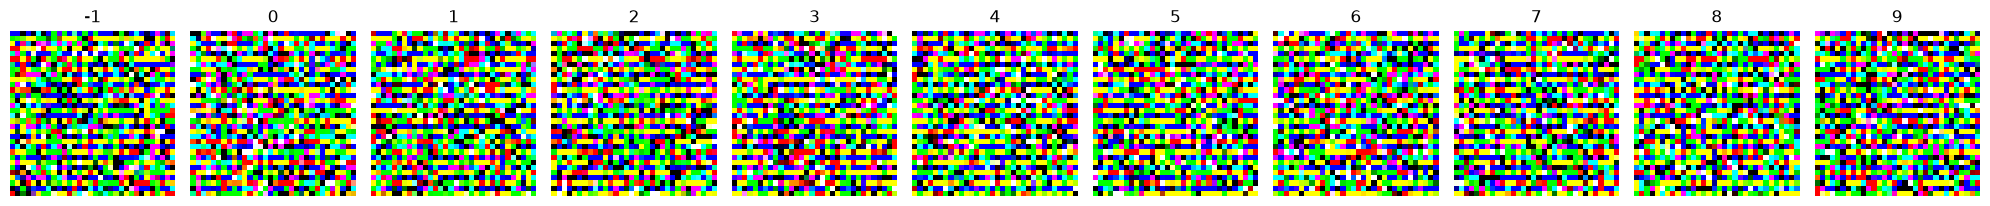

Progressive stage 2/10: changes={'timesteps': (970, 1000)}, resolution=32, sampling t in [970, 1000) range.
Epoch 51/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 33s 27ms/step - noise_loss: 0.0909 - learning_rate: 0.0047
Epoch 52/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 7.4507e-04 - learning_rate: 0.0047
Epoch 53/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 5.7272e-04 - learning_rate: 0.0047
Epoch 54/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 5.3377e-04 - learning_rate: 0.0047
Epoch 55/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 25s 65ms/step - noise_loss: 4.9921e-04 - val_image_loss: 6.9678 - val_loss: 1.4212 - val_noise_loss: 1.4212 - learning_rate: 0.0047
Steps: 50/50


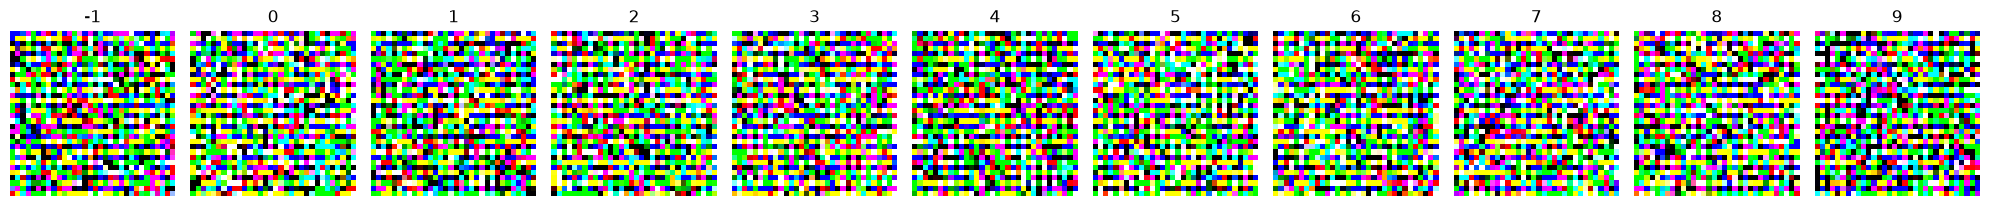

Epoch 56/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.8345e-04 - learning_rate: 0.0047
Epoch 57/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.8097e-04 - learning_rate: 0.0047
Epoch 58/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.8658e-04 - learning_rate: 0.0047
Epoch 59/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.7240e-04 - learning_rate: 0.0047
Epoch 60/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 65ms/step - noise_loss: 4.7982e-04 - val_image_loss: 5.8589 - val_loss: 1.9690 - val_noise_loss: 1.9690 - learning_rate: 0.0047
Steps: 50/50


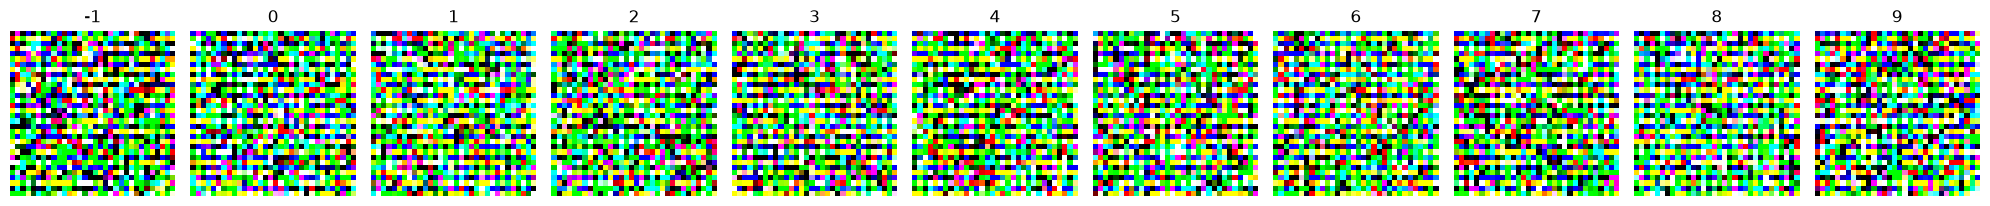

Epoch 61/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.8272e-04 - learning_rate: 0.0047
Epoch 62/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 5.0183e-04 - learning_rate: 0.0047
Epoch 63/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 4.7945e-04 - learning_rate: 0.0047
Epoch 64/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.6625e-04 - learning_rate: 0.0047
Epoch 65/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 66ms/step - noise_loss: 4.4033e-04 - val_image_loss: 4.4212 - val_loss: 1.7495 - val_noise_loss: 1.7495 - learning_rate: 0.0047
Steps: 50/50


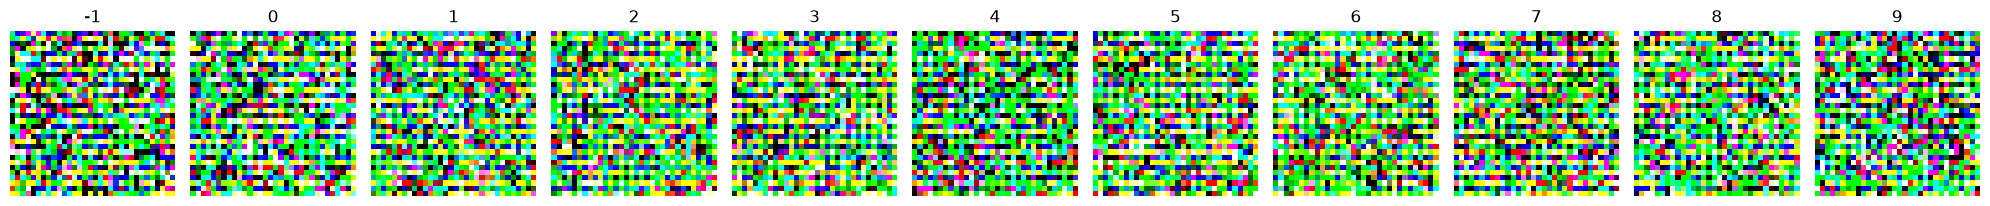

Epoch 66/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 4.7707e-04 - learning_rate: 0.0047
Epoch 67/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 4.3307e-04 - learning_rate: 0.0047
Epoch 68/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 4.5161e-04 - learning_rate: 0.0047
Epoch 69/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.3653e-04 - learning_rate: 0.0047
Epoch 70/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 25s 65ms/step - noise_loss: 4.4524e-04 - val_image_loss: 3.0725 - val_loss: 1.3611 - val_noise_loss: 1.3611 - learning_rate: 0.0047
Steps: 50/50


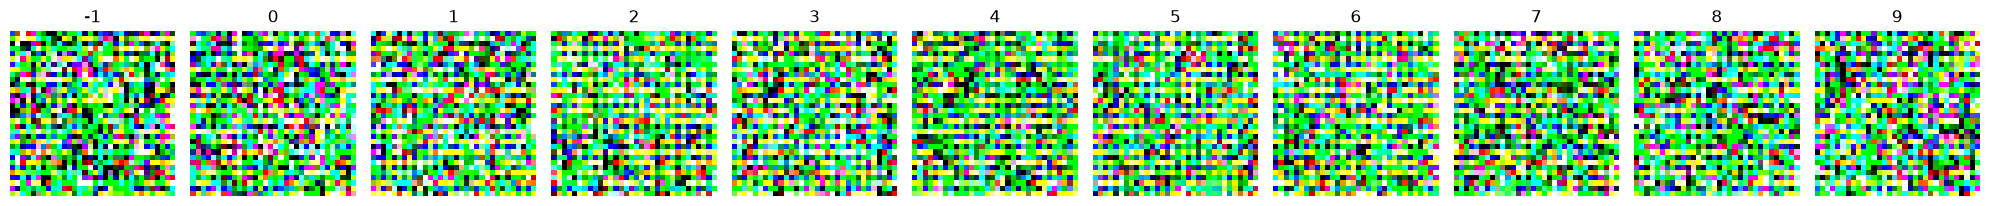

Epoch 71/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.7163e-04 - learning_rate: 0.0046
Epoch 72/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.0792e-04 - learning_rate: 0.0046
Epoch 73/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.3085e-04 - learning_rate: 0.0046
Epoch 74/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 4.3325e-04 - learning_rate: 0.0046
Epoch 75/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 24s 62ms/step - noise_loss: 4.2972e-04 - val_image_loss: 2.4516 - val_loss: 0.9556 - val_noise_loss: 0.9556 - learning_rate: 0.0046
Steps: 50/50


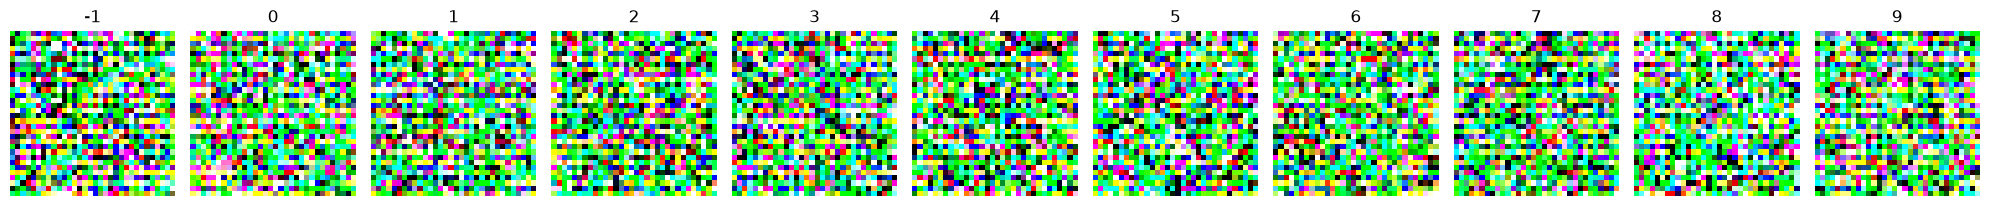

Epoch 76/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 4.1602e-04 - learning_rate: 0.0046
Epoch 77/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.2090e-04 - learning_rate: 0.0046
Epoch 78/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.3927e-04 - learning_rate: 0.0046
Epoch 79/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0097 - learning_rate: 0.0046
Epoch 80/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 24s 63ms/step - noise_loss: 4.4198e-04 - val_image_loss: 4.6291 - val_loss: 1.8320 - val_noise_loss: 1.8320 - learning_rate: 0.0046
Steps: 50/50


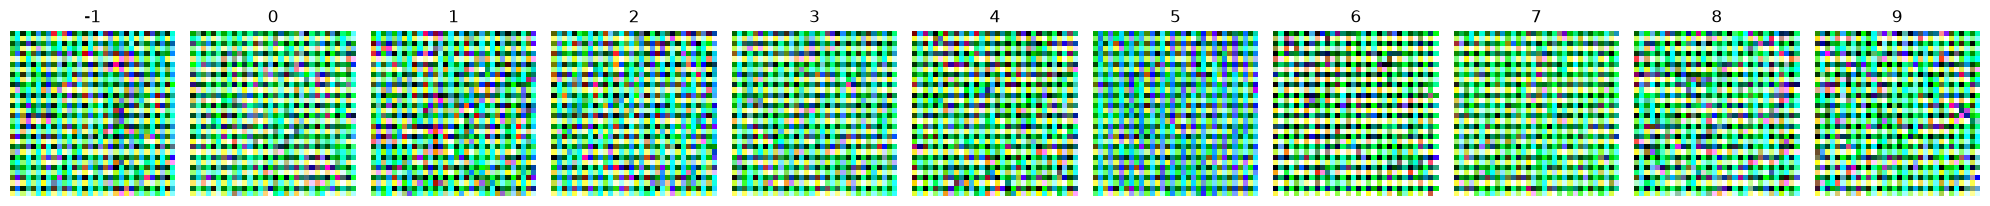

Epoch 81/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.2106e-04 - learning_rate: 0.0046
Epoch 82/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 4.1647e-04 - learning_rate: 0.0046
Epoch 83/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.0733e-04 - learning_rate: 0.0046
Epoch 84/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.2313e-04 - learning_rate: 0.0046
Epoch 85/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 24s 63ms/step - noise_loss: 4.1501e-04 - val_image_loss: 7.4130 - val_loss: 2.3873 - val_noise_loss: 2.3873 - learning_rate: 0.0046
Steps: 50/50


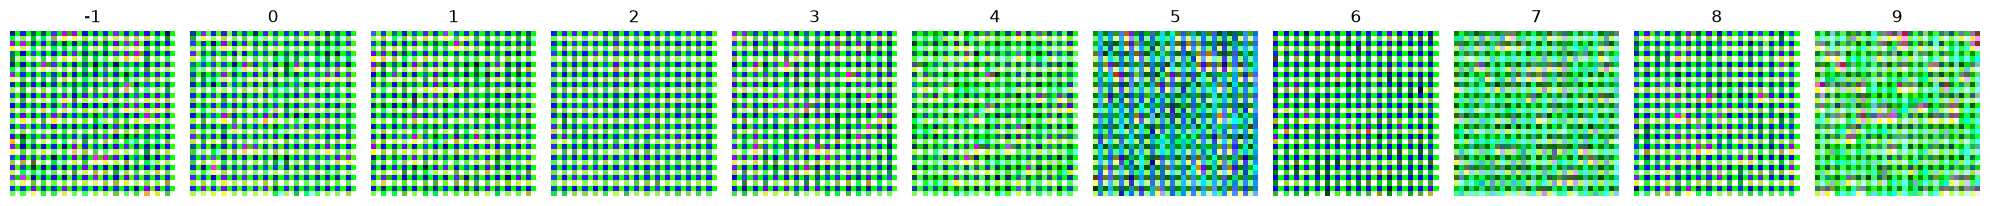

Epoch 86/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.2172e-04 - learning_rate: 0.0046
Epoch 87/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.1739e-04 - learning_rate: 0.0046
Epoch 88/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.1893e-04 - learning_rate: 0.0045
Epoch 89/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.2454e-04 - learning_rate: 0.0045
Epoch 90/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 28s 70ms/step - noise_loss: 4.3479e-04 - val_image_loss: 6.8149 - val_loss: 2.1485 - val_noise_loss: 2.1485 - learning_rate: 0.0045
Steps: 50/50


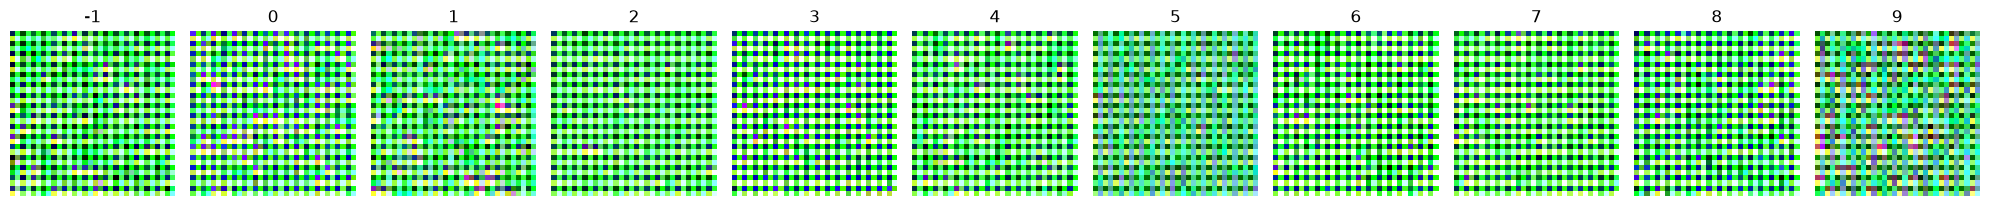

Epoch 91/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.0967e-04 - learning_rate: 0.0045
Epoch 92/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.2404e-04 - learning_rate: 0.0045
Epoch 93/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.1827e-04 - learning_rate: 0.0045
Epoch 94/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 4.2294e-04 - learning_rate: 0.0045
Epoch 95/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 68ms/step - noise_loss: 4.0930e-04 - val_image_loss: 5.4230 - val_loss: 1.7734 - val_noise_loss: 1.7734 - learning_rate: 0.0045
Steps: 50/50


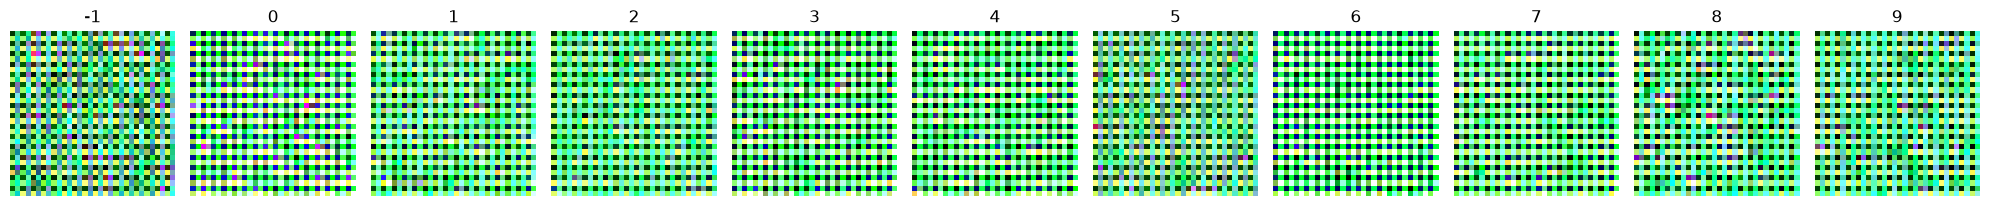

Epoch 96/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.1617e-04 - learning_rate: 0.0045
Epoch 97/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.1597e-04 - learning_rate: 0.0045
Epoch 98/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 4.0152e-04 - learning_rate: 0.0045
Epoch 99/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 4.2562e-04 - learning_rate: 0.0045
Epoch 100/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 68ms/step - noise_loss: 4.0223e-04 - val_image_loss: 4.4546 - val_loss: 1.4703 - val_noise_loss: 1.4703 - learning_rate: 0.0045
Steps: 50/50


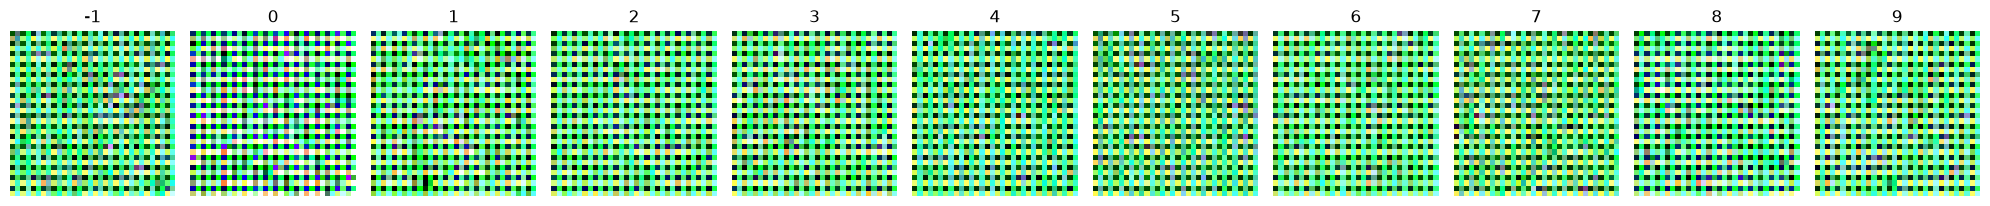

Progressive stage 3/10: changes={'timesteps': (940, 1000)}, resolution=32, sampling t in [940, 1000) range.
Epoch 101/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 33s 28ms/step - noise_loss: 0.0281 - learning_rate: 0.0045
Epoch 102/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 9.6829e-04 - learning_rate: 0.0044
Epoch 103/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 9.3785e-04 - learning_rate: 0.0044
Epoch 104/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 8.9921e-04 - learning_rate: 0.0044
Epoch 105/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 68ms/step - noise_loss: 8.7381e-04 - val_image_loss: 4.0213 - val_loss: 1.3419 - val_noise_loss: 1.3419 - learning_rate: 0.0044
Steps: 50/50


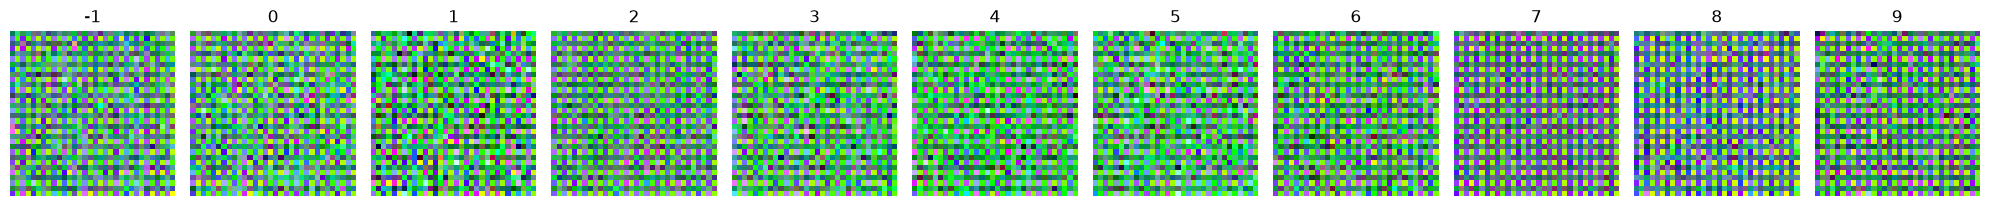

Epoch 106/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 8.5220e-04 - learning_rate: 0.0044
Epoch 107/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 8.5215e-04 - learning_rate: 0.0044
Epoch 108/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 8.4304e-04 - learning_rate: 0.0044
Epoch 109/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 8.4598e-04 - learning_rate: 0.0044
Epoch 110/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 69ms/step - noise_loss: 8.4571e-04 - val_image_loss: 4.8674 - val_loss: 2.0542 - val_noise_loss: 2.0542 - learning_rate: 0.0044
Steps: 50/50


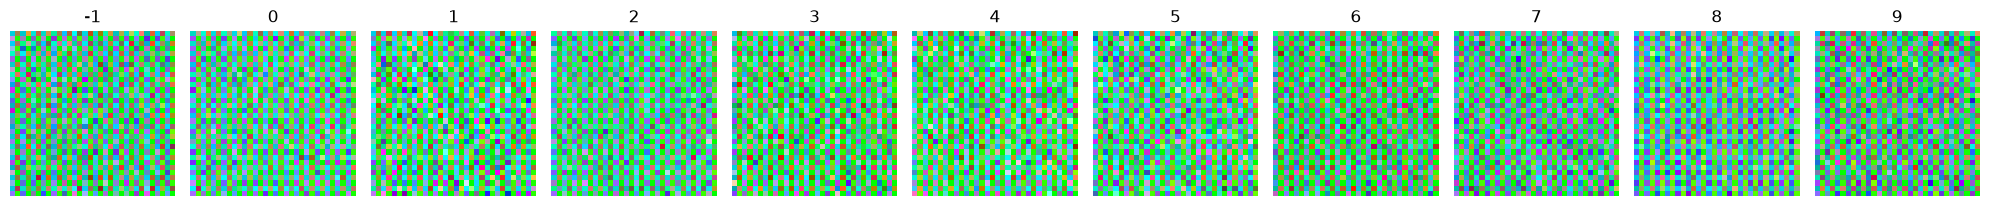

Epoch 111/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 8.5392e-04 - learning_rate: 0.0044
Epoch 112/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 8.5960e-04 - learning_rate: 0.0044
Epoch 113/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 8.5149e-04 - learning_rate: 0.0044
Epoch 114/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 8.4448e-04 - learning_rate: 0.0043
Epoch 115/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 67ms/step - noise_loss: 8.5211e-04 - val_image_loss: 5.7389 - val_loss: 2.5228 - val_noise_loss: 2.5228 - learning_rate: 0.0043
Steps: 50/50


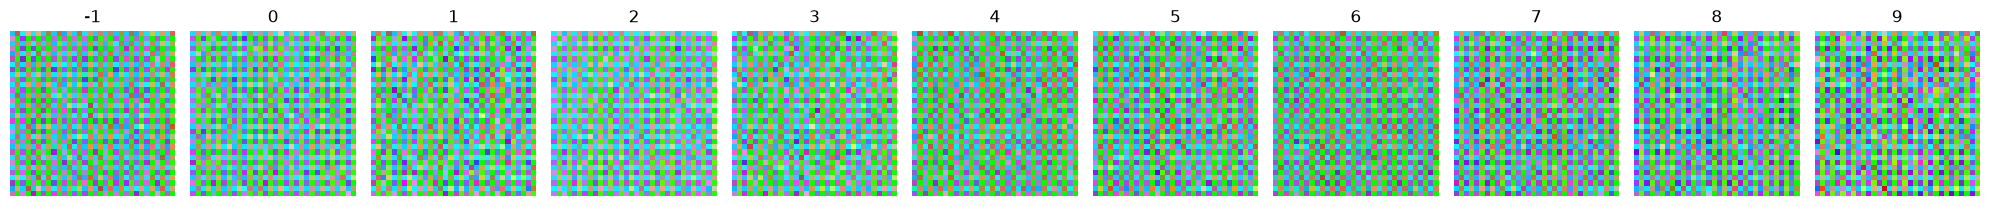

Epoch 116/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 8.5219e-04 - learning_rate: 0.0043
Epoch 117/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 8.3522e-04 - learning_rate: 0.0043
Epoch 118/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 8.4701e-04 - learning_rate: 0.0043
Epoch 119/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 8.4073e-04 - learning_rate: 0.0043
Epoch 120/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 66ms/step - noise_loss: 8.3852e-04 - val_image_loss: 5.5865 - val_loss: 2.4027 - val_noise_loss: 2.4027 - learning_rate: 0.0043
Steps: 50/50


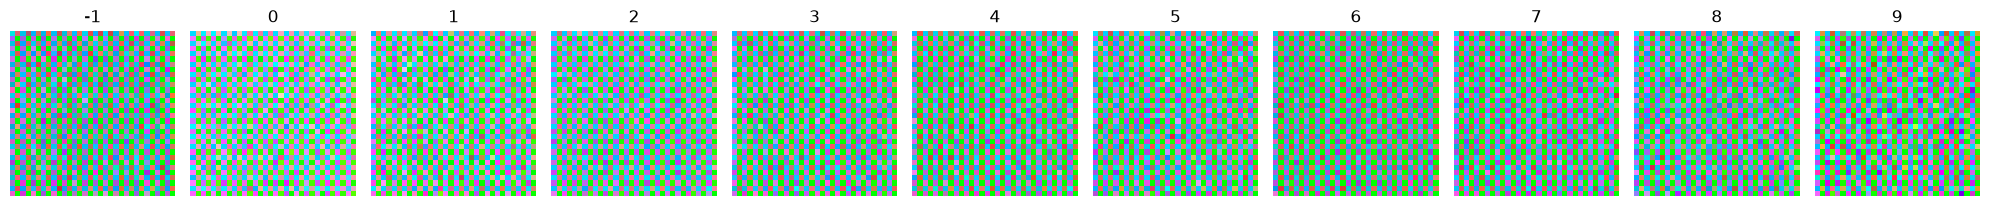

Epoch 121/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 8.4424e-04 - learning_rate: 0.0043
Epoch 122/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 8.3200e-04 - learning_rate: 0.0043
Epoch 123/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 8.3830e-04 - learning_rate: 0.0043
Epoch 124/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 8.3924e-04 - learning_rate: 0.0043
Epoch 125/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 68ms/step - noise_loss: 8.2675e-04 - val_image_loss: 5.3486 - val_loss: 2.2650 - val_noise_loss: 2.2650 - learning_rate: 0.0043
Steps: 50/50


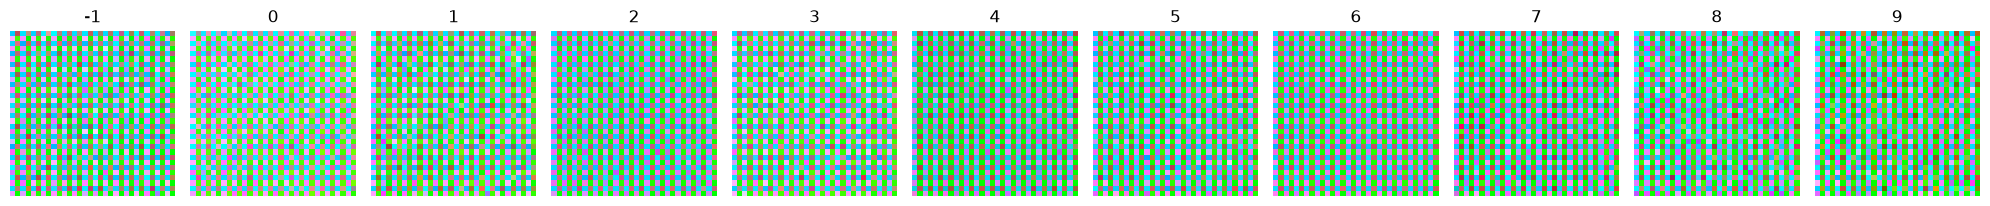

Epoch 126/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 8.3907e-04 - learning_rate: 0.0042
Epoch 127/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 8.2682e-04 - learning_rate: 0.0042
Epoch 128/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 8.3478e-04 - learning_rate: 0.0042
Epoch 129/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 8.3303e-04 - learning_rate: 0.0042
Epoch 130/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 69ms/step - noise_loss: 8.3385e-04 - val_image_loss: 5.2008 - val_loss: 2.0972 - val_noise_loss: 2.0972 - learning_rate: 0.0042
Steps: 50/50


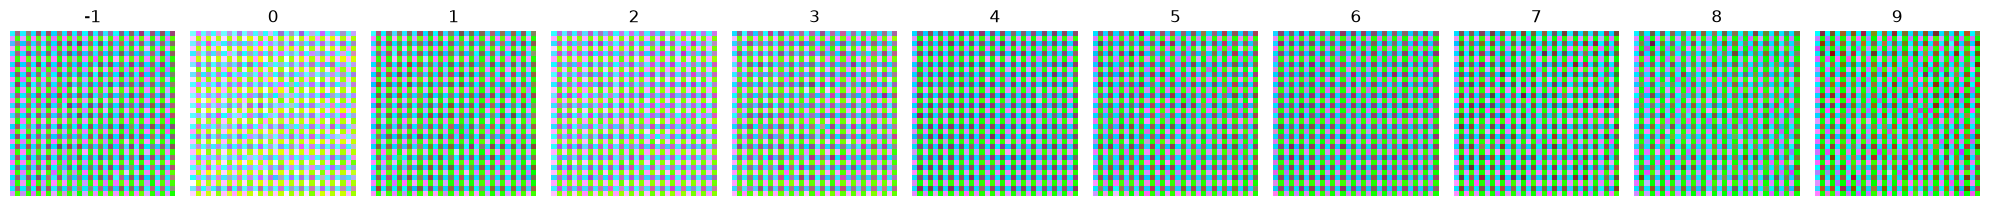

Epoch 131/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 8.2459e-04 - learning_rate: 0.0042
Epoch 132/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 8.3702e-04 - learning_rate: 0.0042
Epoch 133/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 8.2639e-04 - learning_rate: 0.0042
Epoch 134/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 8.2844e-04 - learning_rate: 0.0042
Epoch 135/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 25s 65ms/step - noise_loss: 8.2810e-04 - val_image_loss: 4.8717 - val_loss: 1.7680 - val_noise_loss: 1.7680 - learning_rate: 0.0042
Steps: 50/50


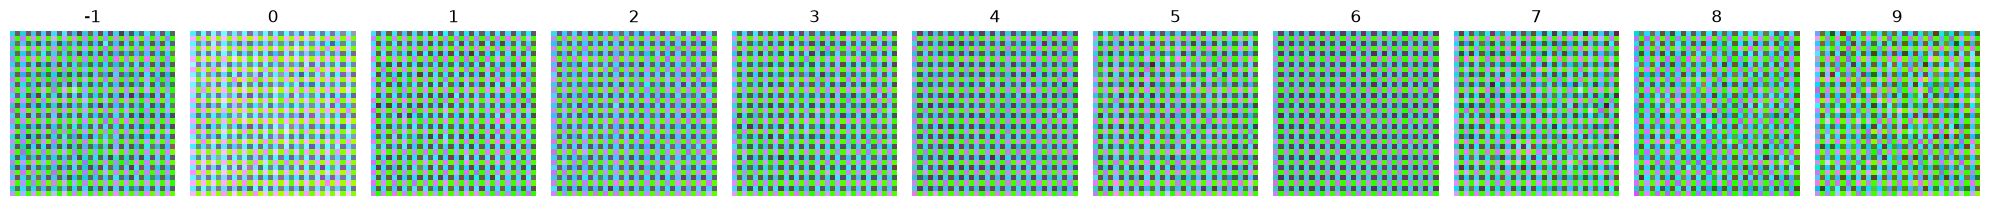

Epoch 136/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0273 - learning_rate: 0.0042
Epoch 137/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 9.4154e-04 - learning_rate: 0.0041
Epoch 138/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 8.6025e-04 - learning_rate: 0.0041
Epoch 139/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 8.2901e-04 - learning_rate: 0.0041
Epoch 140/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 65ms/step - noise_loss: 8.1754e-04 - val_image_loss: 3.9415 - val_loss: 1.5298 - val_noise_loss: 1.5298 - learning_rate: 0.0041
Steps: 50/50


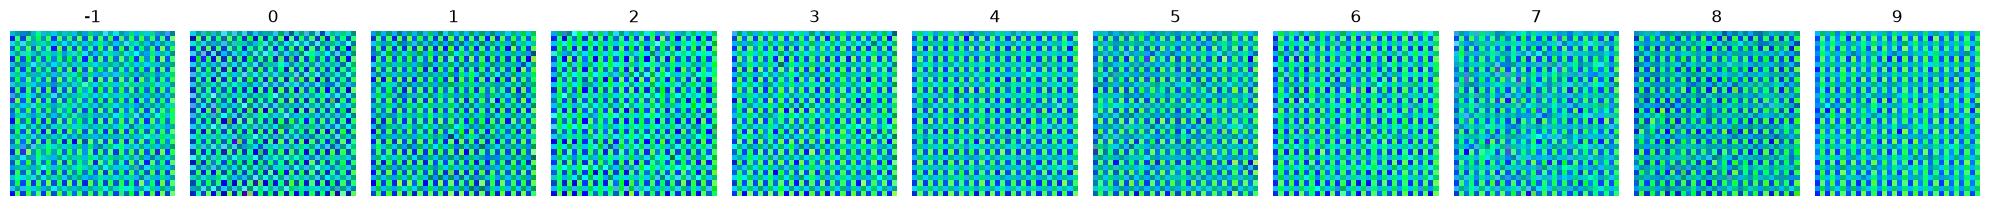

Epoch 141/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 8.2055e-04 - learning_rate: 0.0041
Epoch 142/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 8.2102e-04 - learning_rate: 0.0041
Epoch 143/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 8.2046e-04 - learning_rate: 0.0041
Epoch 144/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 8.2419e-04 - learning_rate: 0.0041
Epoch 145/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 68ms/step - noise_loss: 8.2295e-04 - val_image_loss: 4.1581 - val_loss: 1.7862 - val_noise_loss: 1.7862 - learning_rate: 0.0041
Steps: 50/50


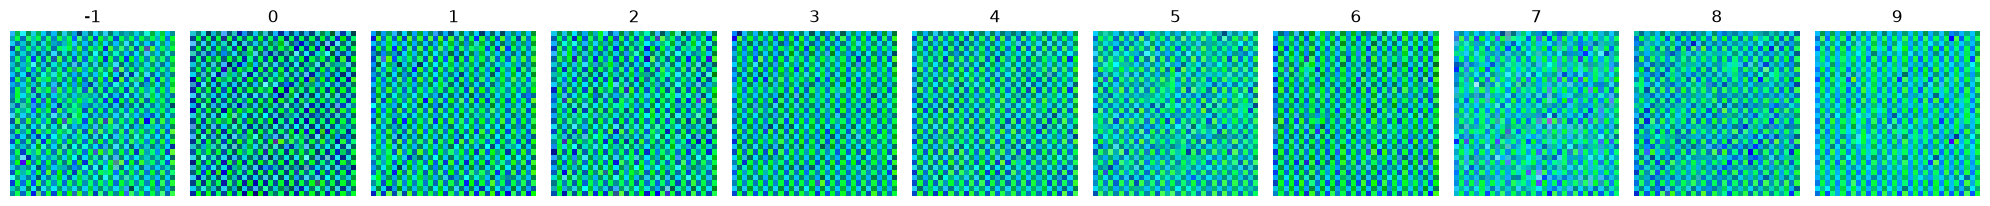

Epoch 146/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 8.3211e-04 - learning_rate: 0.0041
Epoch 147/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 8.3663e-04 - learning_rate: 0.0040
Epoch 148/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 8.2226e-04 - learning_rate: 0.0040
Epoch 149/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 8.2574e-04 - learning_rate: 0.0040
Epoch 150/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 66ms/step - noise_loss: 8.2974e-04 - val_image_loss: 4.7561 - val_loss: 1.9729 - val_noise_loss: 1.9729 - learning_rate: 0.0040
Steps: 50/50


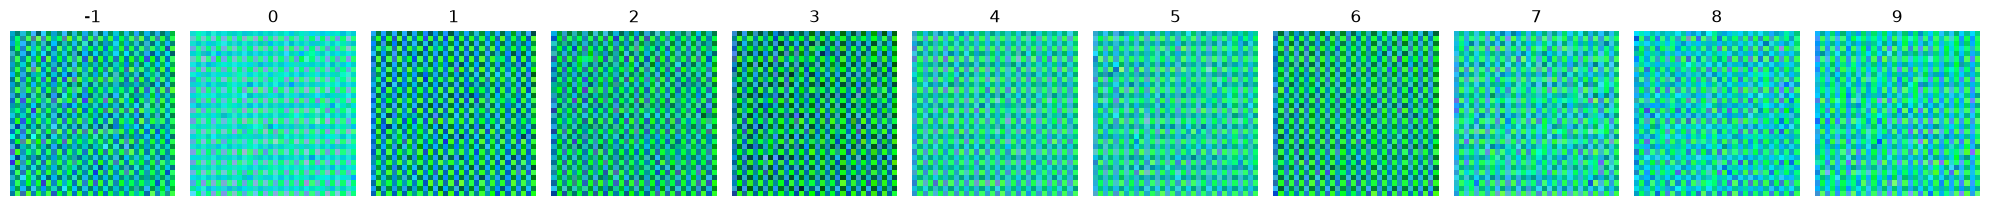

Progressive stage 4/10: changes={'timesteps': (892, 1000)}, resolution=32, sampling t in [892, 1000) range.
Epoch 151/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 33s 28ms/step - noise_loss: 0.0110 - learning_rate: 0.0040
Epoch 152/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0018 - learning_rate: 0.0040
Epoch 153/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0018 - learning_rate: 0.0040
Epoch 154/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0018 - learning_rate: 0.0040
Epoch 155/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 68ms/step - noise_loss: 0.0017 - val_image_loss: 0.7128 - val_loss: 0.4559 - val_noise_loss: 0.4559 - learning_rate: 0.0040
Steps: 50/50


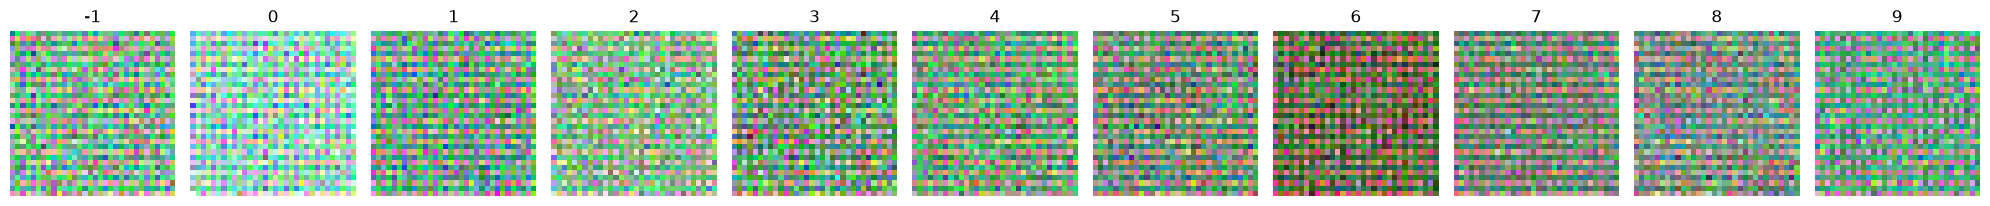

Epoch 156/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0017 - learning_rate: 0.0039
Epoch 157/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0017 - learning_rate: 0.0039
Epoch 158/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0017 - learning_rate: 0.0039
Epoch 159/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0017 - learning_rate: 0.0039
Epoch 160/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 69ms/step - noise_loss: 0.0017 - val_image_loss: 0.6963 - val_loss: 0.4704 - val_noise_loss: 0.4704 - learning_rate: 0.0039
Steps: 50/50


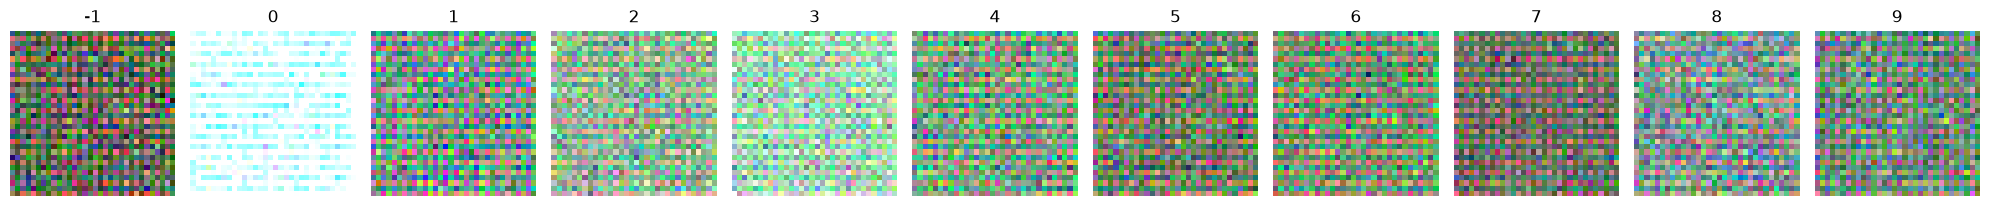

Epoch 161/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0017 - learning_rate: 0.0039
Epoch 162/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0017 - learning_rate: 0.0039
Epoch 163/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0017 - learning_rate: 0.0039
Epoch 164/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0017 - learning_rate: 0.0039
Epoch 165/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 66ms/step - noise_loss: 0.0017 - val_image_loss: 0.7040 - val_loss: 0.4538 - val_noise_loss: 0.4538 - learning_rate: 0.0038
Steps: 50/50


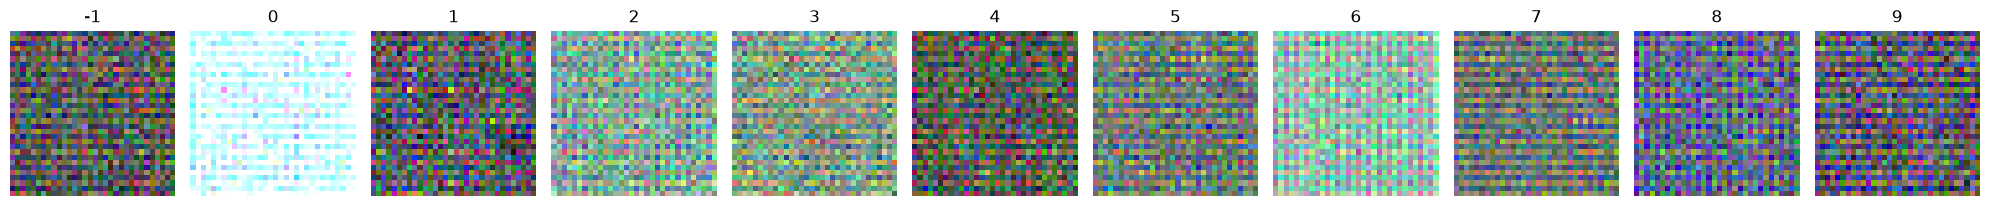

Epoch 166/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0017 - learning_rate: 0.0038
Epoch 167/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0017 - learning_rate: 0.0038
Epoch 168/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0017 - learning_rate: 0.0038
Epoch 169/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0017 - learning_rate: 0.0038
Epoch 170/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 25s 64ms/step - noise_loss: 0.0017 - val_image_loss: 0.7568 - val_loss: 0.4509 - val_noise_loss: 0.4509 - learning_rate: 0.0038
Steps: 50/50


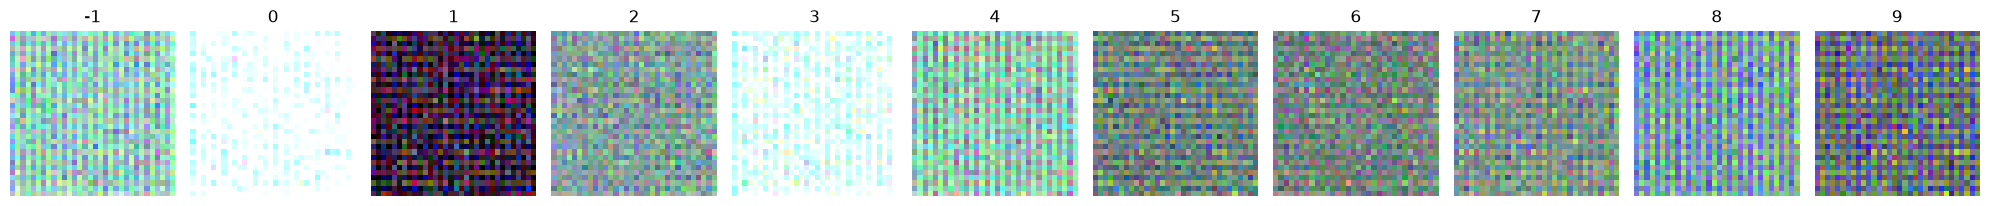

Epoch 171/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0017 - learning_rate: 0.0038
Epoch 172/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0017 - learning_rate: 0.0038
Epoch 173/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0017 - learning_rate: 0.0038
Epoch 174/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0017 - learning_rate: 0.0037
Epoch 175/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 68ms/step - noise_loss: 0.0017 - val_image_loss: 0.8478 - val_loss: 0.4858 - val_noise_loss: 0.4858 - learning_rate: 0.0037
Steps: 50/50


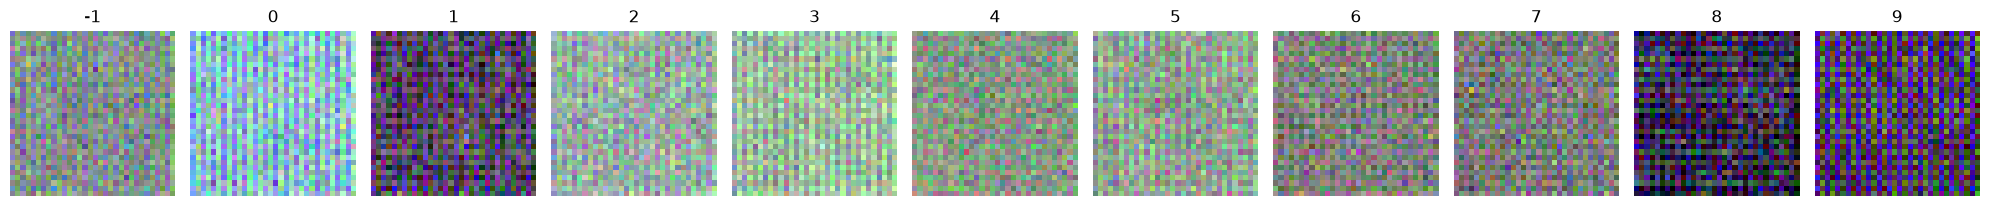

Epoch 176/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0017 - learning_rate: 0.0037
Epoch 177/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0017 - learning_rate: 0.0037
Epoch 178/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0017 - learning_rate: 0.0037
Epoch 179/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0017 - learning_rate: 0.0037
Epoch 180/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 28s 70ms/step - noise_loss: 0.0017 - val_image_loss: 0.7825 - val_loss: 0.3984 - val_noise_loss: 0.3984 - learning_rate: 0.0037
Steps: 50/50


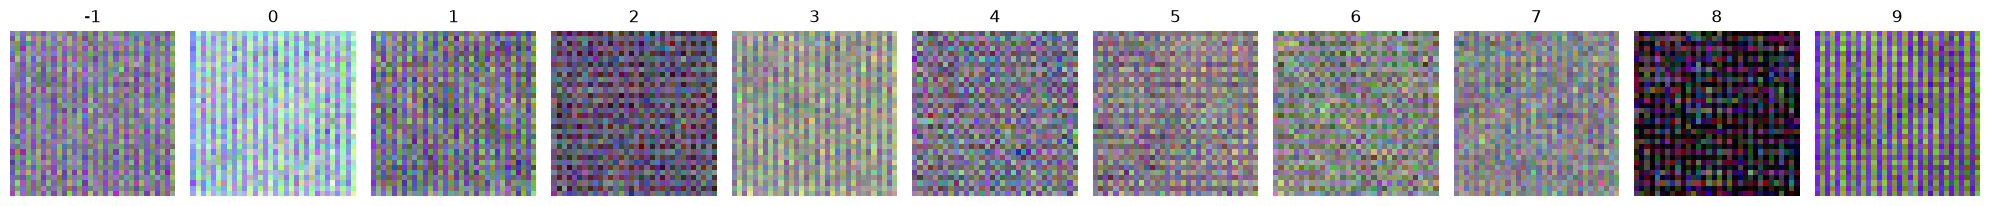

Epoch 181/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0017 - learning_rate: 0.0037
Epoch 182/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0017 - learning_rate: 0.0036
Epoch 183/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0017 - learning_rate: 0.0036
Epoch 184/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0017 - learning_rate: 0.0036
Epoch 185/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 67ms/step - noise_loss: 0.0017 - val_image_loss: 0.7501 - val_loss: 0.3818 - val_noise_loss: 0.3818 - learning_rate: 0.0036
Steps: 50/50


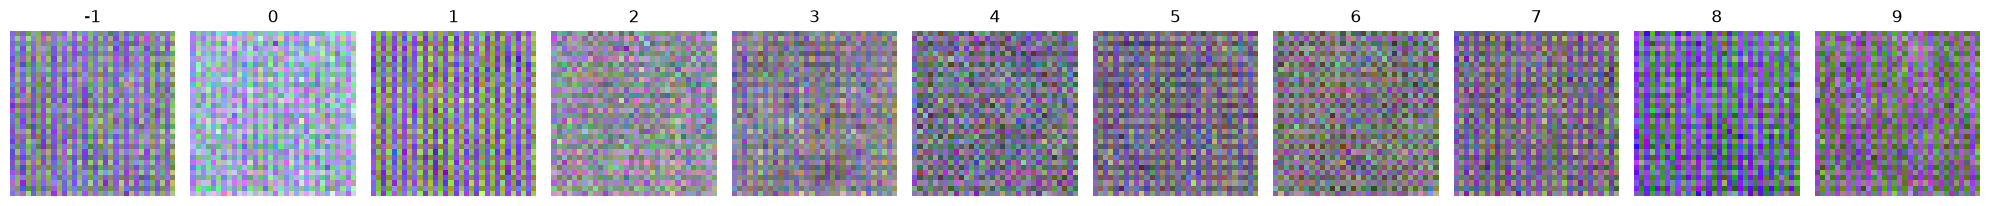

Epoch 186/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0017 - learning_rate: 0.0036
Epoch 187/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0017 - learning_rate: 0.0036
Epoch 188/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0016 - learning_rate: 0.0036
Epoch 189/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0016 - learning_rate: 0.0036
Epoch 190/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 68ms/step - noise_loss: 0.0016 - val_image_loss: 0.7449 - val_loss: 0.3657 - val_noise_loss: 0.3657 - learning_rate: 0.0036
Steps: 50/50


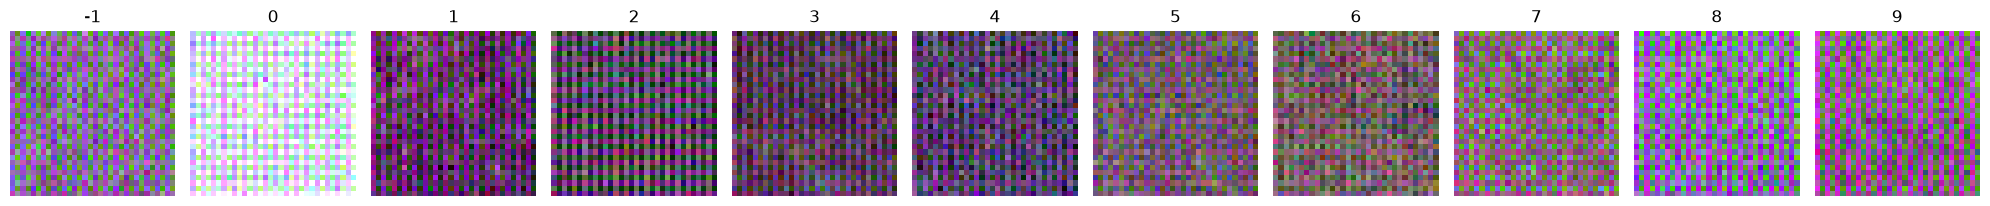

Epoch 191/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0016 - learning_rate: 0.0035
Epoch 192/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0016 - learning_rate: 0.0035
Epoch 193/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0016 - learning_rate: 0.0035
Epoch 194/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0016 - learning_rate: 0.0035
Epoch 195/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 66ms/step - noise_loss: 0.0016 - val_image_loss: 0.7331 - val_loss: 0.3397 - val_noise_loss: 0.3397 - learning_rate: 0.0035
Steps: 50/50


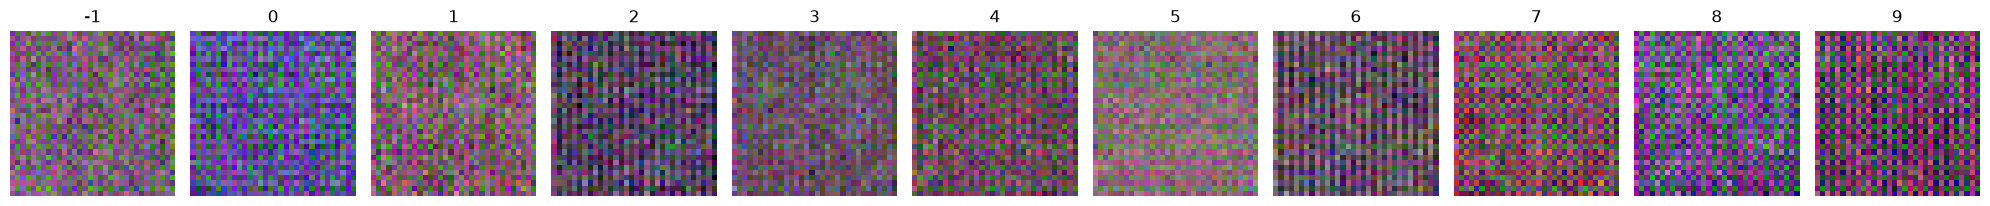

Epoch 196/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0016 - learning_rate: 0.0035
Epoch 197/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0016 - learning_rate: 0.0035
Epoch 198/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0269 - learning_rate: 0.0035
Epoch 199/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0020 - learning_rate: 0.0034
Epoch 200/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 69ms/step - noise_loss: 0.0019 - val_image_loss: 1.1702 - val_loss: 0.3748 - val_noise_loss: 0.3748 - learning_rate: 0.0034
Steps: 50/50


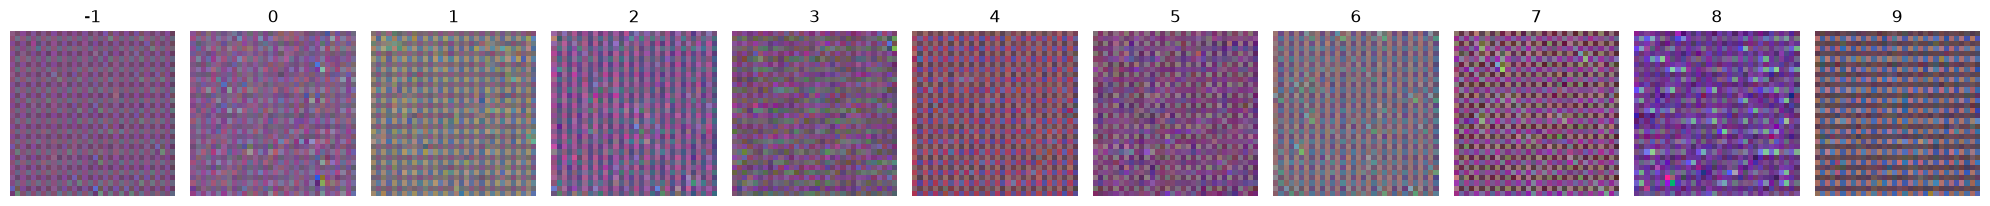

Progressive stage 5/10: changes={'timesteps': (814, 1000)}, resolution=32, sampling t in [814, 1000) range.
Epoch 201/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 33s 28ms/step - noise_loss: 0.0057 - learning_rate: 0.0034
Epoch 202/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0039 - learning_rate: 0.0034
Epoch 203/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0038 - learning_rate: 0.0034
Epoch 204/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 0.0037 - learning_rate: 0.0034
Epoch 205/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 25s 65ms/step - noise_loss: 0.0037 - val_image_loss: 0.2406 - val_loss: 0.2194 - val_noise_loss: 0.2194 - learning_rate: 0.0034
Steps: 50/50


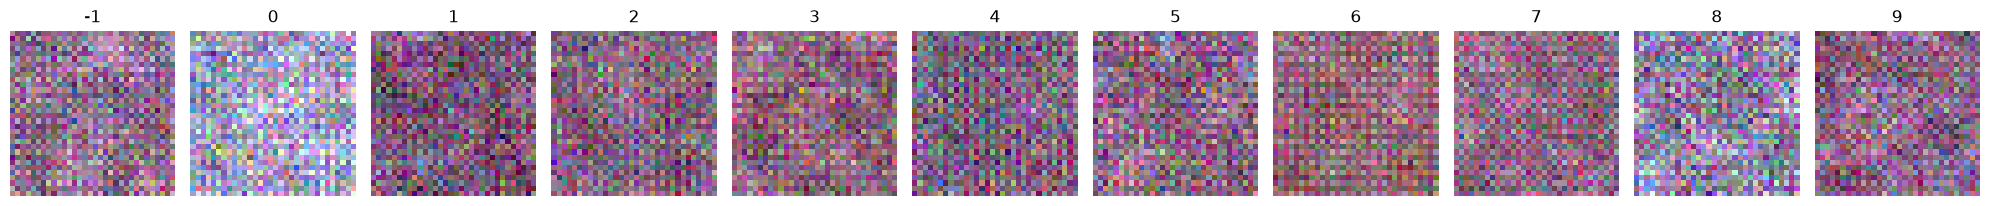

Epoch 206/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0036 - learning_rate: 0.0034
Epoch 207/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0036 - learning_rate: 0.0033
Epoch 208/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0036 - learning_rate: 0.0033
Epoch 209/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0036 - learning_rate: 0.0033
Epoch 210/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 68ms/step - noise_loss: 0.0036 - val_image_loss: 0.2171 - val_loss: 0.2117 - val_noise_loss: 0.2117 - learning_rate: 0.0033
Steps: 50/50


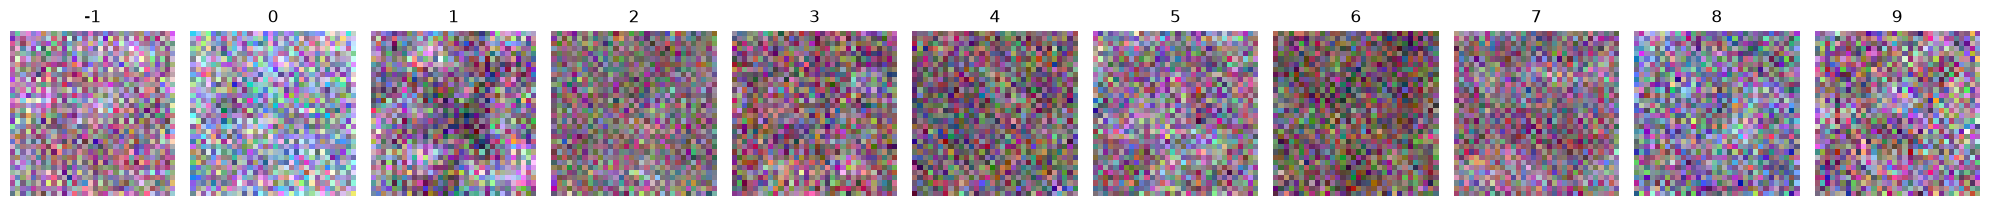

Epoch 211/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - noise_loss: 0.0036 - learning_rate: 0.0033
Epoch 212/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - noise_loss: 0.0036 - learning_rate: 0.0033
Epoch 213/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0036 - learning_rate: 0.0033
Epoch 214/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0036 - learning_rate: 0.0032
Epoch 215/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 67ms/step - noise_loss: 0.0036 - val_image_loss: 0.2125 - val_loss: 0.2110 - val_noise_loss: 0.2110 - learning_rate: 0.0032
Steps: 50/50


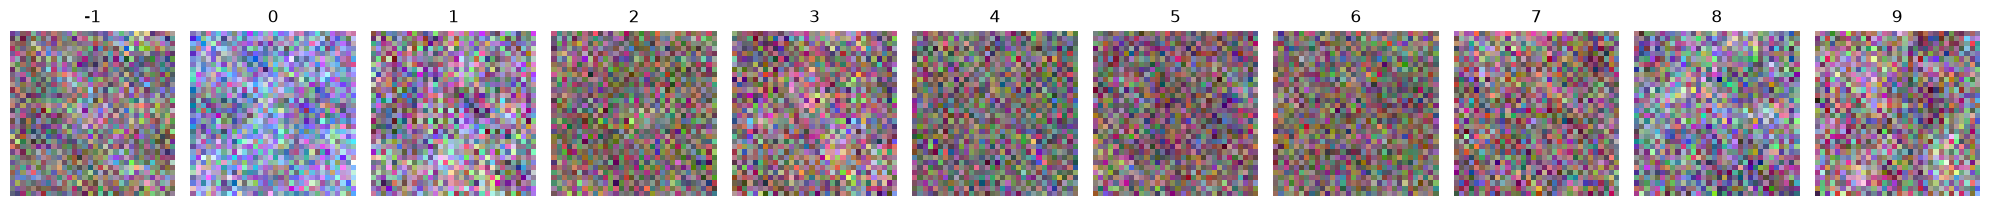

Epoch 216/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 0.0036 - learning_rate: 0.0032
Epoch 217/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0036 - learning_rate: 0.0032
Epoch 218/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0036 - learning_rate: 0.0032
Epoch 219/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0036 - learning_rate: 0.0032
Epoch 220/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 66ms/step - noise_loss: 0.0036 - val_image_loss: 0.2082 - val_loss: 0.2045 - val_noise_loss: 0.2045 - learning_rate: 0.0032
Steps: 50/50


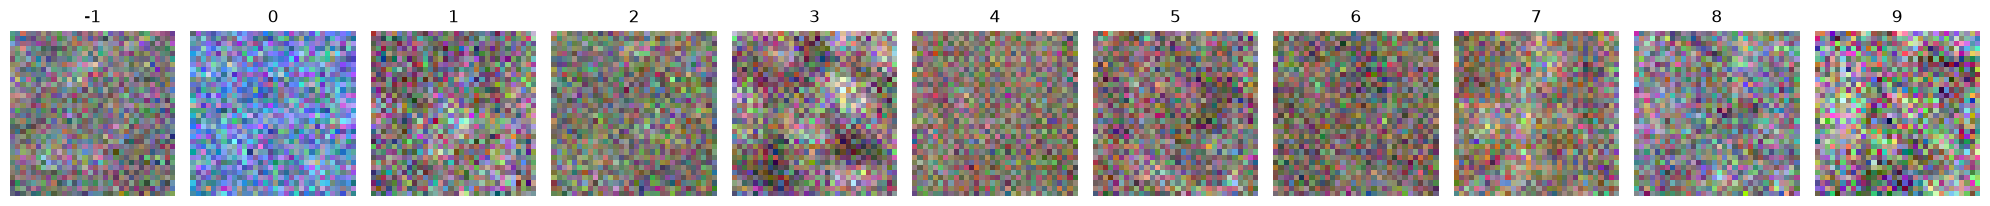

Epoch 221/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0036 - learning_rate: 0.0032
Epoch 222/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0036 - learning_rate: 0.0031
Epoch 223/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0036 - learning_rate: 0.0031
Epoch 224/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0036 - learning_rate: 0.0031
Epoch 225/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 65ms/step - noise_loss: 0.0036 - val_image_loss: 0.1992 - val_loss: 0.1897 - val_noise_loss: 0.1897 - learning_rate: 0.0031
Steps: 50/50


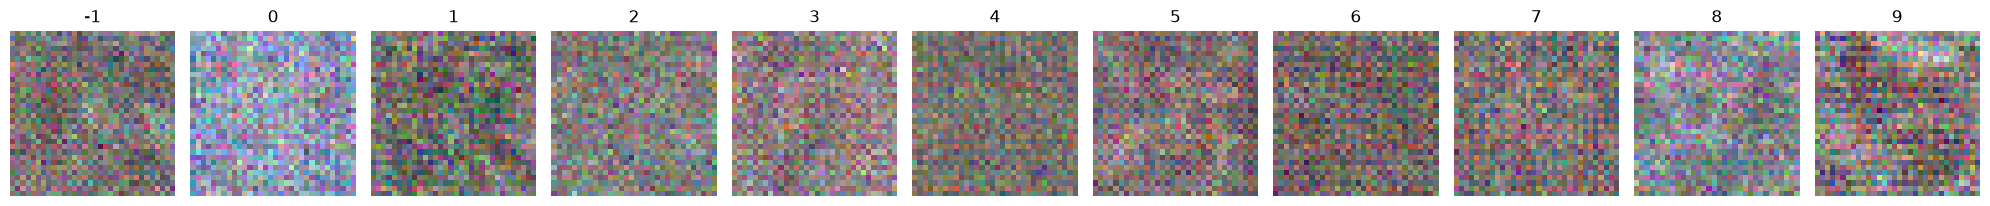

Epoch 226/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0035 - learning_rate: 0.0031
Epoch 227/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0036 - learning_rate: 0.0031
Epoch 228/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0036 - learning_rate: 0.0031
Epoch 229/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0036 - learning_rate: 0.0031
Epoch 230/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 65ms/step - noise_loss: 0.0035 - val_image_loss: 0.1999 - val_loss: 0.1875 - val_noise_loss: 0.1875 - learning_rate: 0.0030
Steps: 50/50


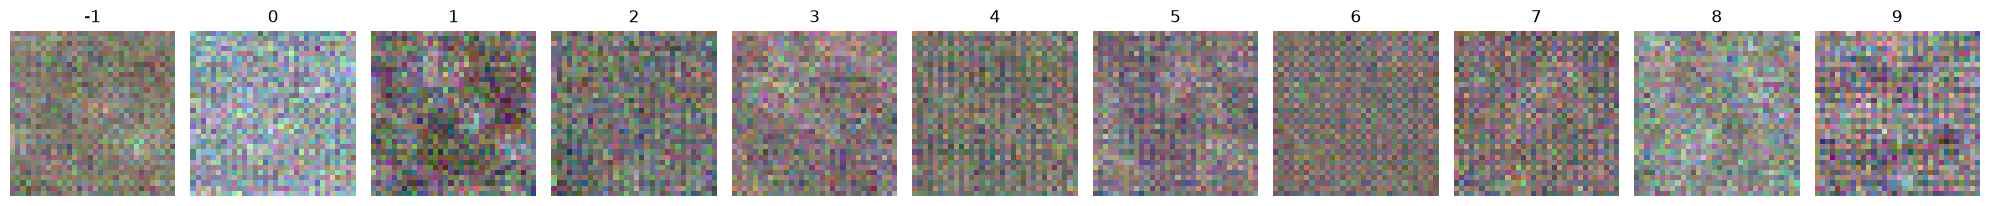

Epoch 231/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0036 - learning_rate: 0.0030
Epoch 232/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0035 - learning_rate: 0.0030
Epoch 233/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0035 - learning_rate: 0.0030
Epoch 234/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0035 - learning_rate: 0.0030
Epoch 235/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 66ms/step - noise_loss: 0.0036 - val_image_loss: 0.2038 - val_loss: 0.1858 - val_noise_loss: 0.1858 - learning_rate: 0.0030
Steps: 50/50


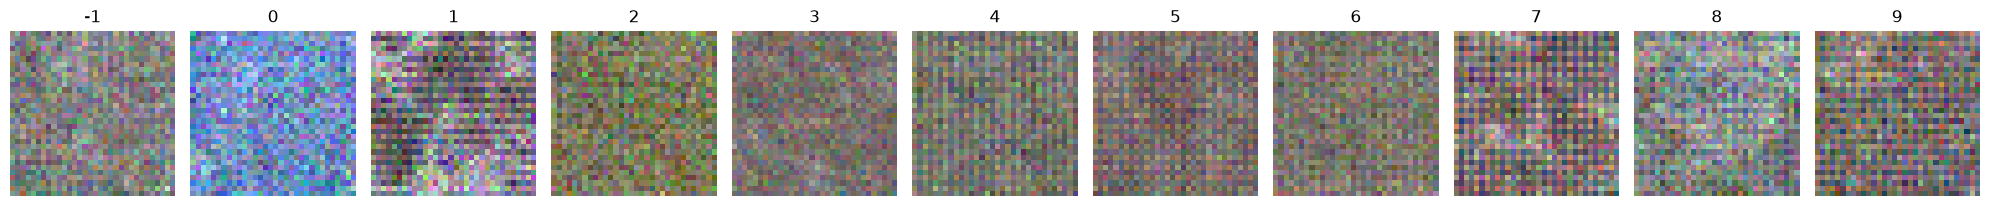

Epoch 236/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 0.0035 - learning_rate: 0.0030
Epoch 237/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0035 - learning_rate: 0.0029
Epoch 238/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0035 - learning_rate: 0.0029
Epoch 239/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 0.0035 - learning_rate: 0.0029
Epoch 240/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 66ms/step - noise_loss: 0.0035 - val_image_loss: 0.2053 - val_loss: 0.1882 - val_noise_loss: 0.1882 - learning_rate: 0.0029
Steps: 50/50


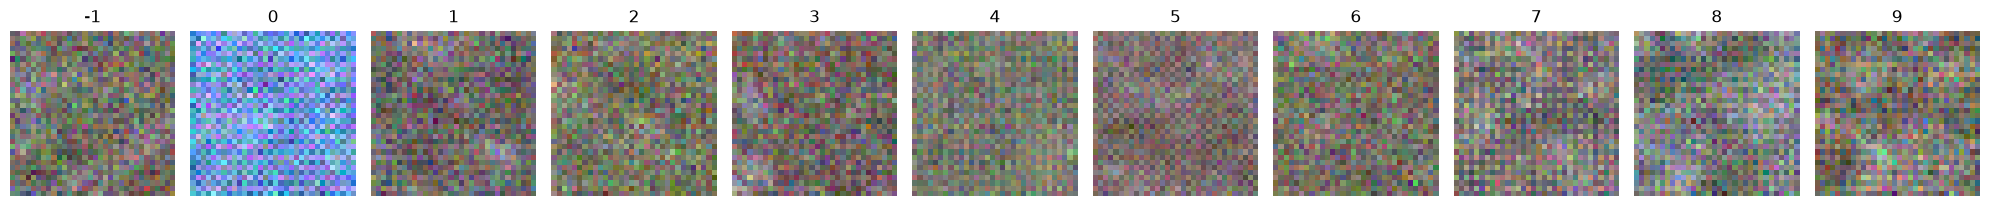

Epoch 241/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0035 - learning_rate: 0.0029
Epoch 242/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0035 - learning_rate: 0.0029
Epoch 243/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0035 - learning_rate: 0.0029
Epoch 244/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0035 - learning_rate: 0.0028
Epoch 245/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 25s 64ms/step - noise_loss: 0.0035 - val_image_loss: 0.2139 - val_loss: 0.1899 - val_noise_loss: 0.1899 - learning_rate: 0.0028
Steps: 50/50


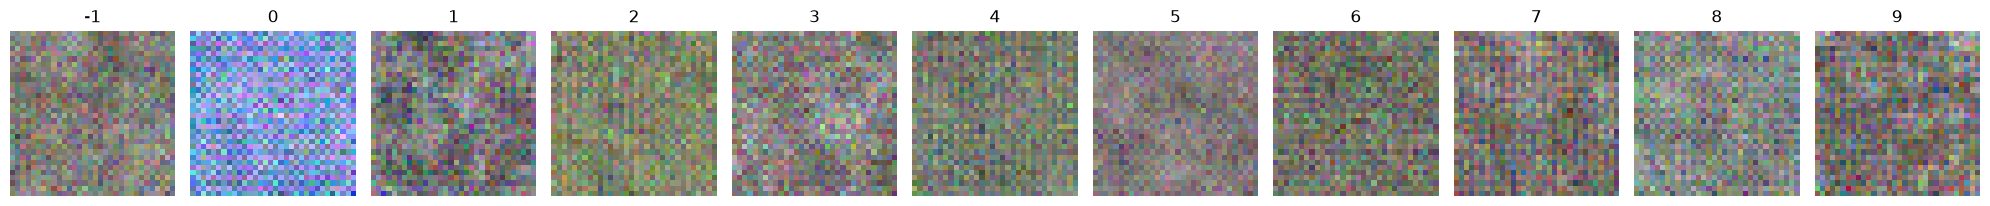

Epoch 246/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0035 - learning_rate: 0.0028
Epoch 247/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0035 - learning_rate: 0.0028
Epoch 248/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 0.0035 - learning_rate: 0.0028
Epoch 249/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0035 - learning_rate: 0.0028
Epoch 250/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 25s 65ms/step - noise_loss: 0.0035 - val_image_loss: 0.2241 - val_loss: 0.2021 - val_noise_loss: 0.2021 - learning_rate: 0.0028
Steps: 50/50


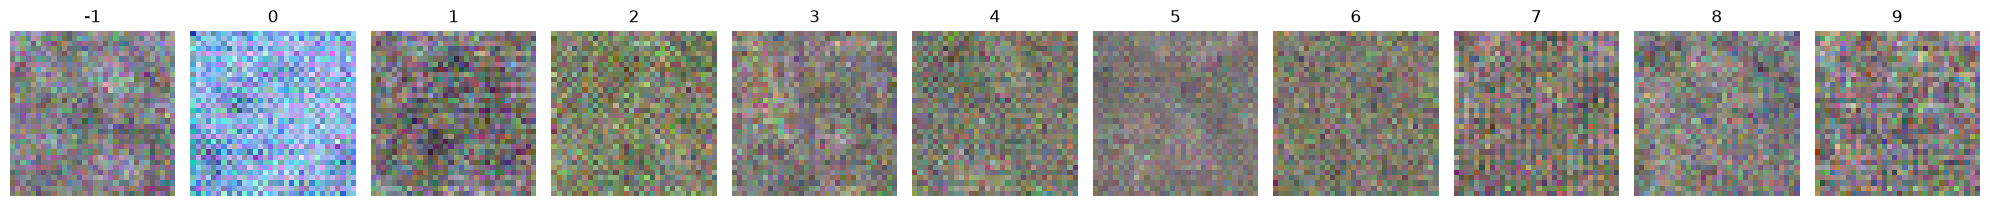

Progressive stage 6/10: changes={'timesteps': (695, 1000)}, resolution=32, sampling t in [695, 1000) range.
Epoch 251/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 33s 28ms/step - noise_loss: 0.0084 - learning_rate: 0.0028
Epoch 252/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 0.0068 - learning_rate: 0.0027
Epoch 253/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 0.0068 - learning_rate: 0.0027
Epoch 254/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0067 - learning_rate: 0.0027
Epoch 255/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 68ms/step - noise_loss: 0.0067 - val_image_loss: 0.1593 - val_loss: 0.1526 - val_noise_loss: 0.1526 - learning_rate: 0.0027
Steps: 50/50


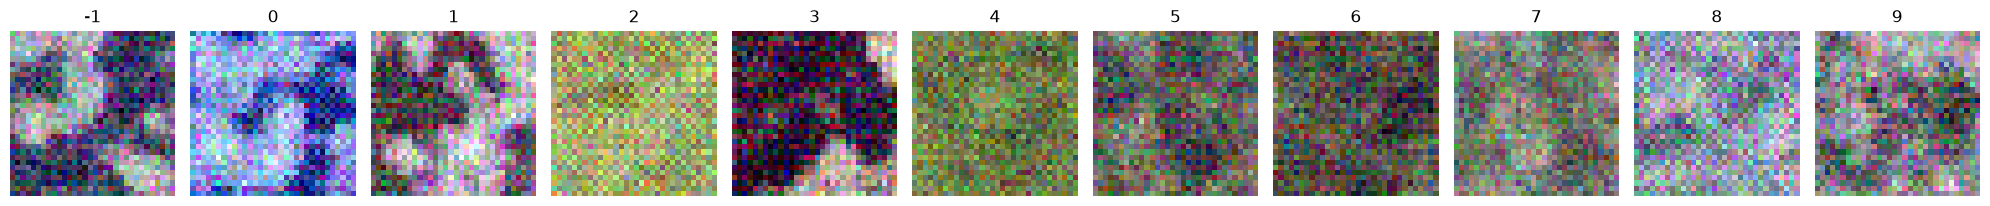

Epoch 256/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0067 - learning_rate: 0.0027
Epoch 257/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0067 - learning_rate: 0.0027
Epoch 258/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0067 - learning_rate: 0.0027
Epoch 259/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0067 - learning_rate: 0.0026
Epoch 260/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 69ms/step - noise_loss: 0.0067 - val_image_loss: 0.1605 - val_loss: 0.1666 - val_noise_loss: 0.1666 - learning_rate: 0.0026
Steps: 50/50


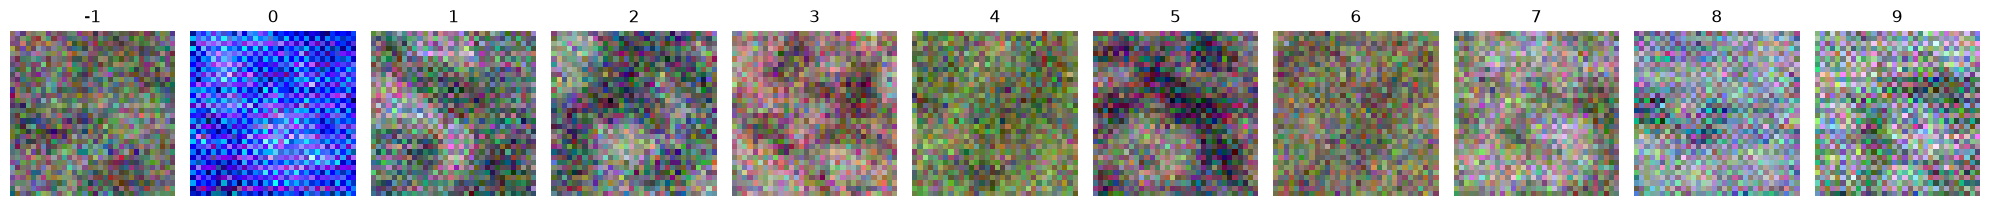

Epoch 261/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0067 - learning_rate: 0.0026
Epoch 262/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0067 - learning_rate: 0.0026
Epoch 263/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0066 - learning_rate: 0.0026
Epoch 264/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0066 - learning_rate: 0.0026
Epoch 265/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 28s 71ms/step - noise_loss: 0.0067 - val_image_loss: 0.1639 - val_loss: 0.1689 - val_noise_loss: 0.1689 - learning_rate: 0.0026
Steps: 50/50


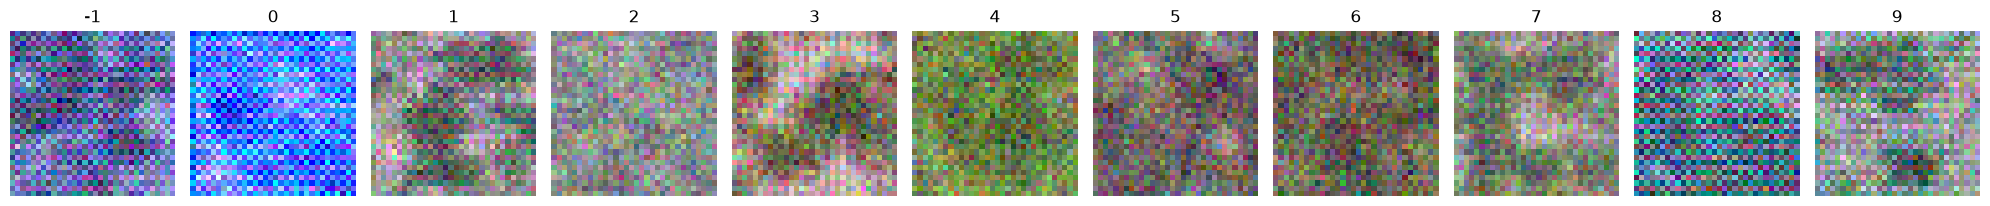

Epoch 266/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0066 - learning_rate: 0.0025
Epoch 267/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0067 - learning_rate: 0.0025
Epoch 268/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0066 - learning_rate: 0.0025
Epoch 269/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0066 - learning_rate: 0.0025
Epoch 270/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 68ms/step - noise_loss: 0.0066 - val_image_loss: 0.1653 - val_loss: 0.1633 - val_noise_loss: 0.1633 - learning_rate: 0.0025
Steps: 50/50


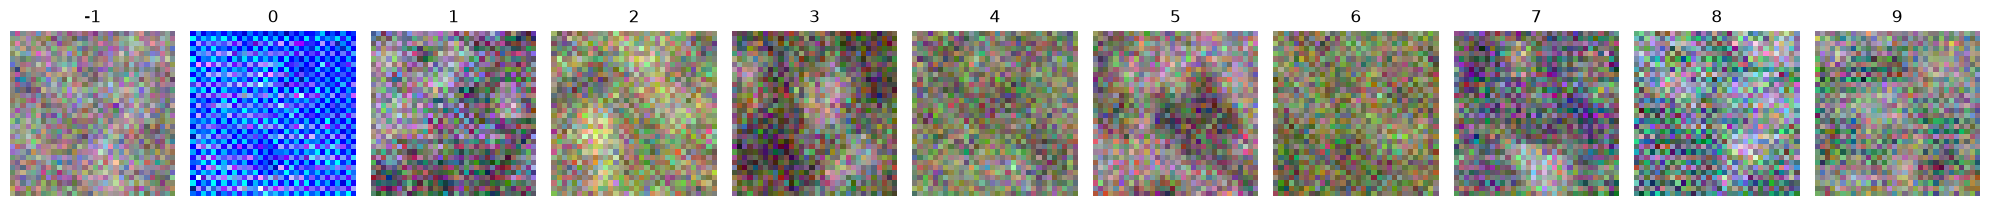

Epoch 271/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0066 - learning_rate: 0.0025
Epoch 272/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0065 - learning_rate: 0.0025
Epoch 273/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0066 - learning_rate: 0.0025
Epoch 274/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0065 - learning_rate: 0.0024
Epoch 275/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 69ms/step - noise_loss: 0.0065 - val_image_loss: 0.1704 - val_loss: 0.1801 - val_noise_loss: 0.1801 - learning_rate: 0.0024
Steps: 50/50


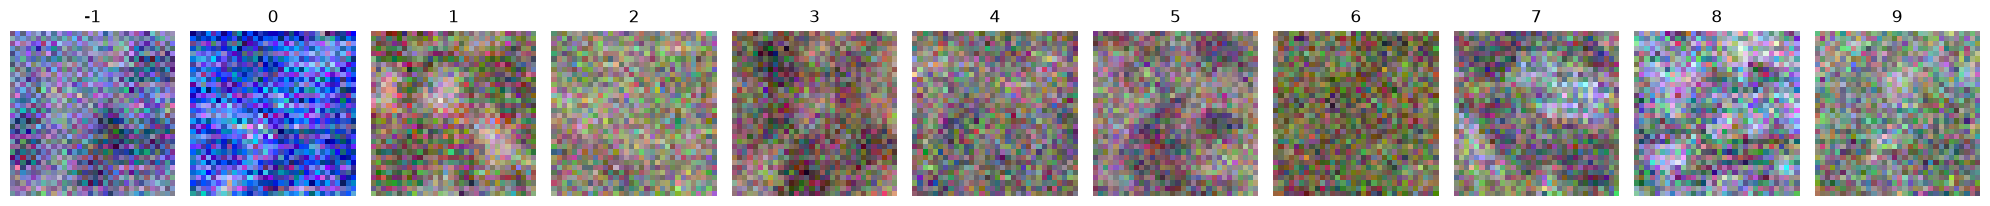

Epoch 276/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0065 - learning_rate: 0.0024
Epoch 277/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0065 - learning_rate: 0.0024
Epoch 278/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0065 - learning_rate: 0.0024
Epoch 279/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0065 - learning_rate: 0.0024
Epoch 280/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 70ms/step - noise_loss: 0.0064 - val_image_loss: 0.1725 - val_loss: 0.1821 - val_noise_loss: 0.1821 - learning_rate: 0.0024
Steps: 50/50


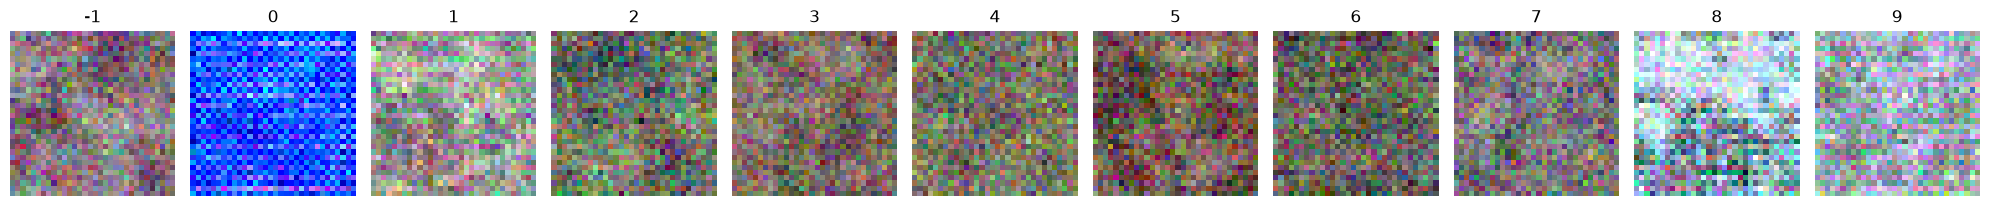

Epoch 281/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0064 - learning_rate: 0.0023
Epoch 282/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - noise_loss: 0.0064 - learning_rate: 0.0023
Epoch 283/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0064 - learning_rate: 0.0023
Epoch 284/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0064 - learning_rate: 0.0023
Epoch 285/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 69ms/step - noise_loss: 0.0064 - val_image_loss: 0.1814 - val_loss: 0.1932 - val_noise_loss: 0.1932 - learning_rate: 0.0023
Steps: 50/50


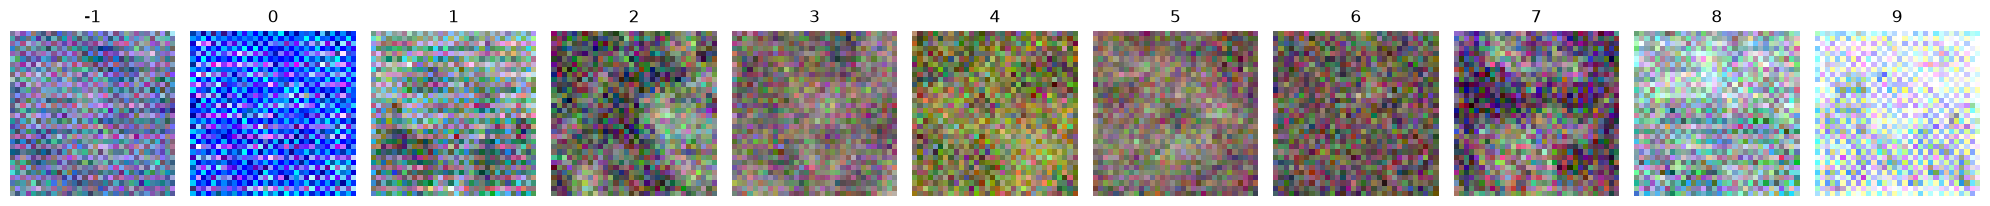

Epoch 286/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0064 - learning_rate: 0.0023
Epoch 287/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0064 - learning_rate: 0.0023
Epoch 288/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - noise_loss: 0.0063 - learning_rate: 0.0022
Epoch 289/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0063 - learning_rate: 0.0022
Epoch 290/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 68ms/step - noise_loss: 0.0063 - val_image_loss: 0.1815 - val_loss: 0.2038 - val_noise_loss: 0.2038 - learning_rate: 0.0022
Steps: 50/50


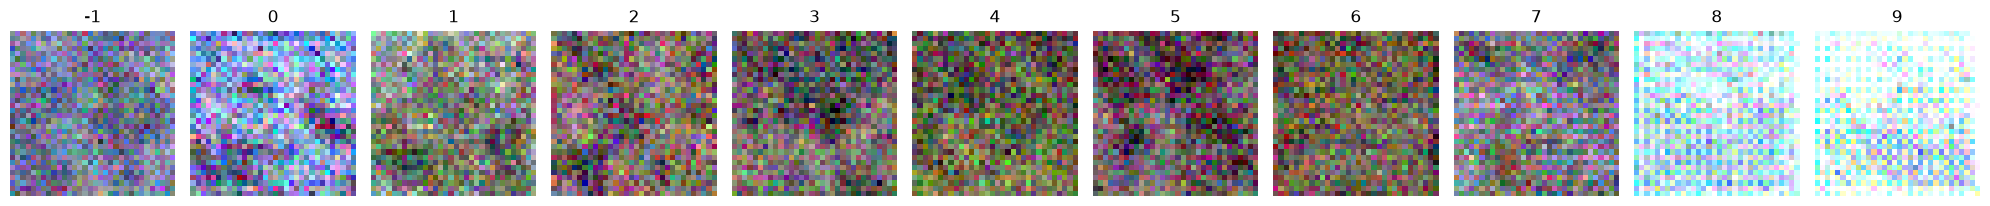

Epoch 291/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0062 - learning_rate: 0.0022
Epoch 292/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - noise_loss: 0.0063 - learning_rate: 0.0022
Epoch 293/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0062 - learning_rate: 0.0022
Epoch 294/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0062 - learning_rate: 0.0022
Epoch 295/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 68ms/step - noise_loss: 0.0062 - val_image_loss: 0.1847 - val_loss: 0.1995 - val_noise_loss: 0.1995 - learning_rate: 0.0021
Steps: 50/50


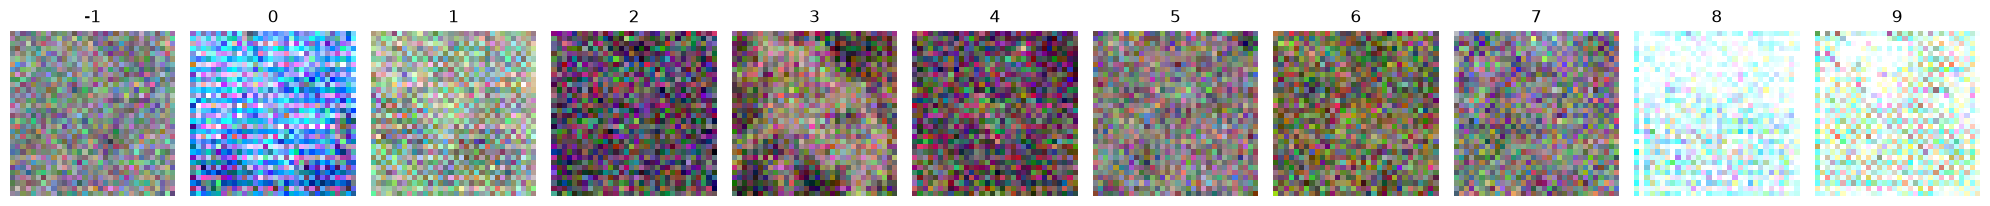

Epoch 296/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0062 - learning_rate: 0.0021
Epoch 297/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0062 - learning_rate: 0.0021
Epoch 298/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0062 - learning_rate: 0.0021
Epoch 299/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0062 - learning_rate: 0.0021
Epoch 300/300
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 68ms/step - noise_loss: 0.0061 - val_image_loss: 0.1815 - val_loss: 0.1884 - val_noise_loss: 0.1884 - learning_rate: 0.0021
Steps: 50/50


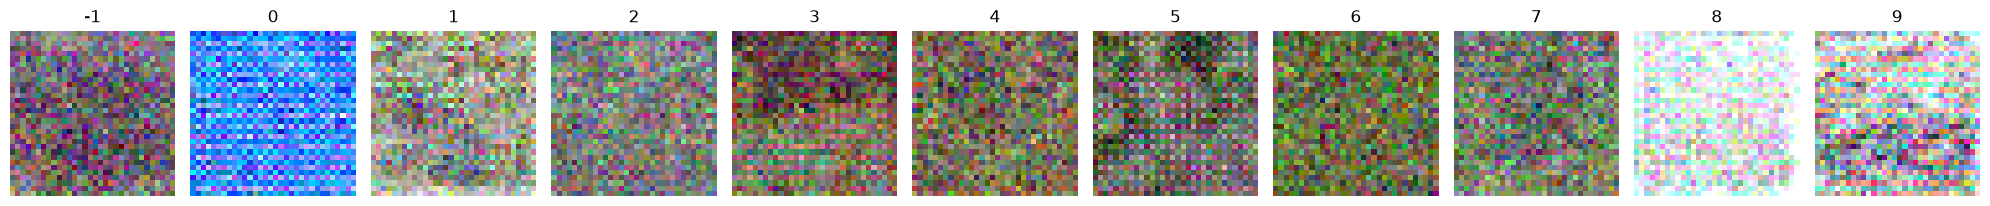

Progressive stage 7/10: changes={'timesteps': (529, 1000)}, resolution=32, sampling t in [529, 1000) range.
Epoch 301/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 33s 28ms/step - noise_loss: 0.0131 - learning_rate: 0.0021
Epoch 302/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0111 - learning_rate: 0.0021
Epoch 303/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0109 - learning_rate: 0.0020
Epoch 304/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0107 - learning_rate: 0.0020
Epoch 305/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 68ms/step - noise_loss: 0.0106 - val_image_loss: 0.1238 - val_loss: 0.1400 - val_noise_loss: 0.1400 - learning_rate: 0.0020
Steps: 50/50


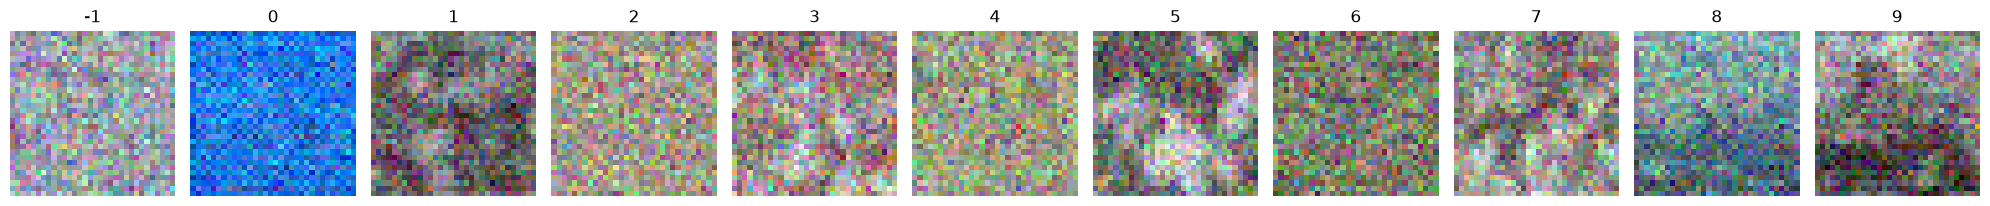

Epoch 306/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0106 - learning_rate: 0.0020
Epoch 307/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0105 - learning_rate: 0.0020
Epoch 308/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0104 - learning_rate: 0.0020
Epoch 309/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0105 - learning_rate: 0.0020
Epoch 310/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 69ms/step - noise_loss: 0.0104 - val_image_loss: 0.1111 - val_loss: 0.1252 - val_noise_loss: 0.1252 - learning_rate: 0.0019
Steps: 50/50


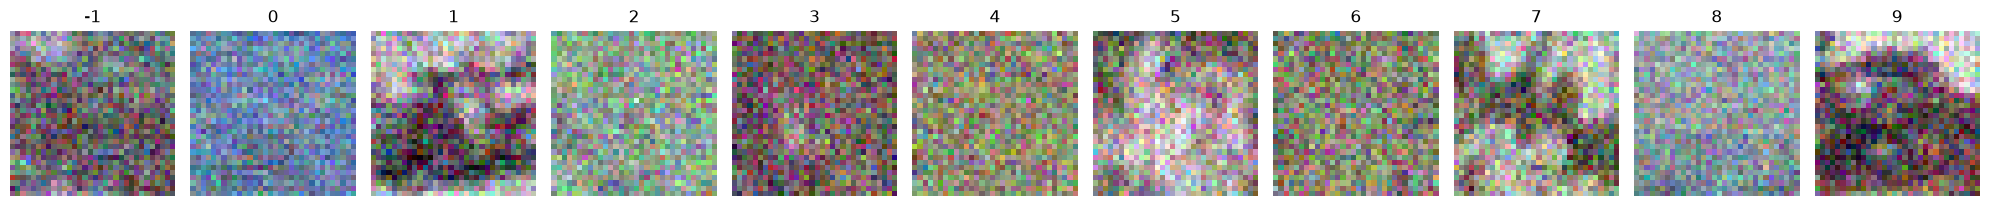

Epoch 311/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0104 - learning_rate: 0.0019
Epoch 312/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0104 - learning_rate: 0.0019
Epoch 313/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0104 - learning_rate: 0.0019
Epoch 314/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0103 - learning_rate: 0.0019
Epoch 315/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 69ms/step - noise_loss: 0.0104 - val_image_loss: 0.1049 - val_loss: 0.1136 - val_noise_loss: 0.1136 - learning_rate: 0.0019
Steps: 50/50


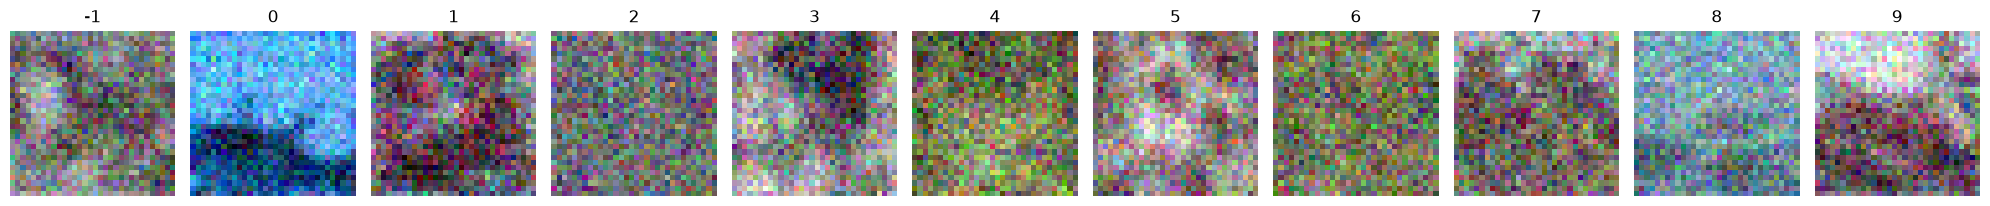

Epoch 316/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0104 - learning_rate: 0.0019
Epoch 317/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0103 - learning_rate: 0.0018
Epoch 318/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0103 - learning_rate: 0.0018
Epoch 319/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0103 - learning_rate: 0.0018
Epoch 320/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 66ms/step - noise_loss: 0.0103 - val_image_loss: 0.1047 - val_loss: 0.1147 - val_noise_loss: 0.1147 - learning_rate: 0.0018
Steps: 50/50


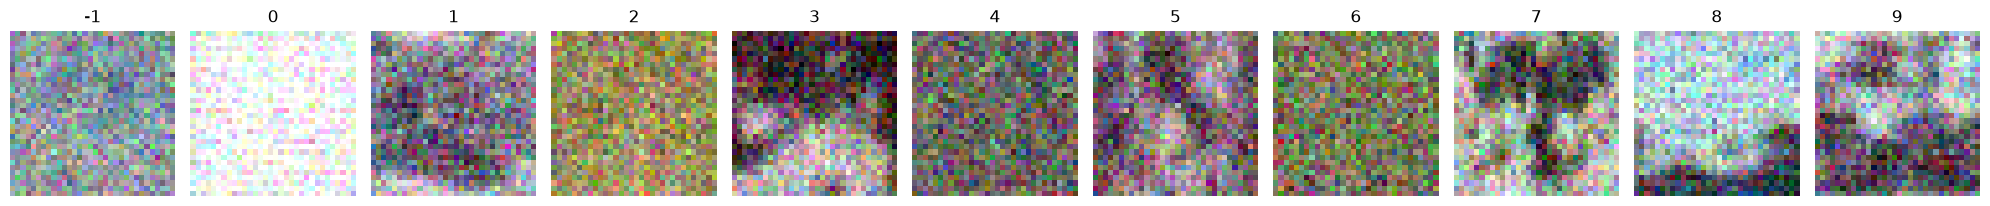

Epoch 321/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0102 - learning_rate: 0.0018
Epoch 322/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0102 - learning_rate: 0.0018
Epoch 323/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0102 - learning_rate: 0.0018
Epoch 324/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0102 - learning_rate: 0.0018
Epoch 325/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 66ms/step - noise_loss: 0.0101 - val_image_loss: 0.1041 - val_loss: 0.1140 - val_noise_loss: 0.1140 - learning_rate: 0.0017
Steps: 50/50


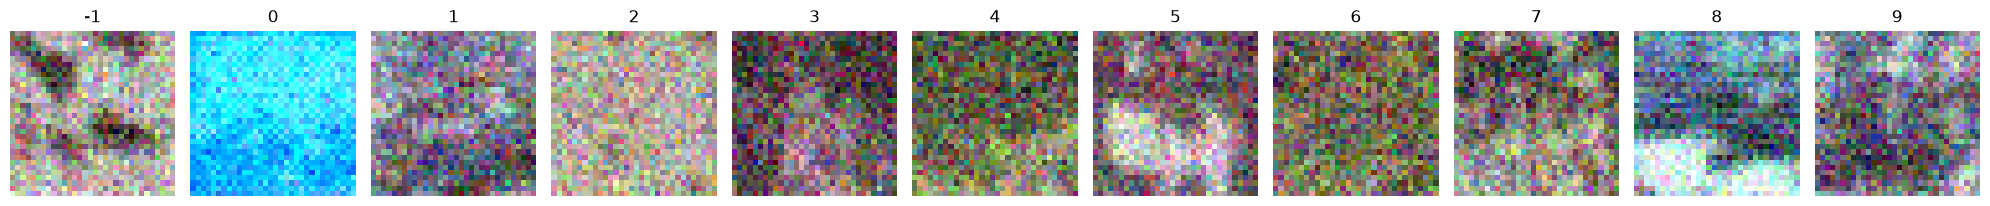

Epoch 326/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0102 - learning_rate: 0.0017
Epoch 327/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0102 - learning_rate: 0.0017
Epoch 328/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0102 - learning_rate: 0.0017
Epoch 329/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - noise_loss: 0.0102 - learning_rate: 0.0017
Epoch 330/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 66ms/step - noise_loss: 0.0101 - val_image_loss: 0.1038 - val_loss: 0.1111 - val_noise_loss: 0.1111 - learning_rate: 0.0017
Steps: 50/50


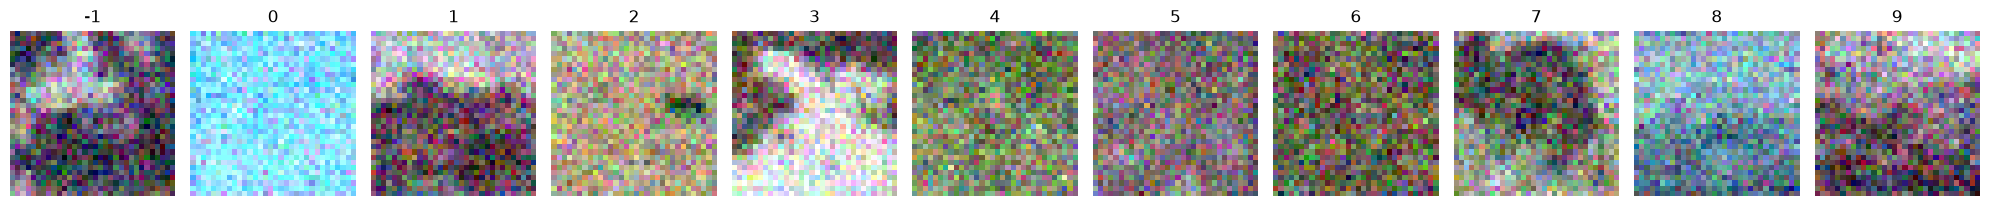

Epoch 331/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0101 - learning_rate: 0.0017
Epoch 332/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0101 - learning_rate: 0.0016
Epoch 333/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0101 - learning_rate: 0.0016
Epoch 334/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0101 - learning_rate: 0.0016
Epoch 335/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 67ms/step - noise_loss: 0.0101 - val_image_loss: 0.1005 - val_loss: 0.1097 - val_noise_loss: 0.1097 - learning_rate: 0.0016
Steps: 50/50


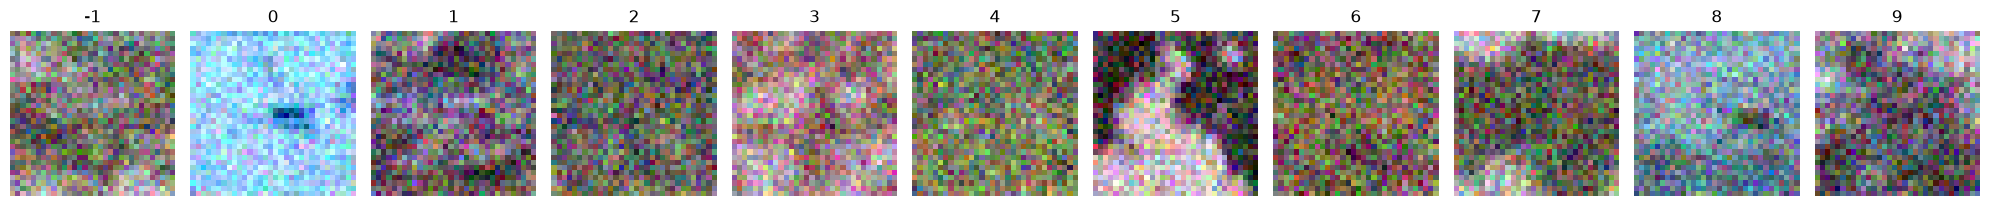

Epoch 336/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0100 - learning_rate: 0.0016
Epoch 337/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0100 - learning_rate: 0.0016
Epoch 338/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0101 - learning_rate: 0.0016
Epoch 339/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0101 - learning_rate: 0.0016
Epoch 340/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 69ms/step - noise_loss: 0.0100 - val_image_loss: 0.1000 - val_loss: 0.1077 - val_noise_loss: 0.1077 - learning_rate: 0.0015
Steps: 50/50


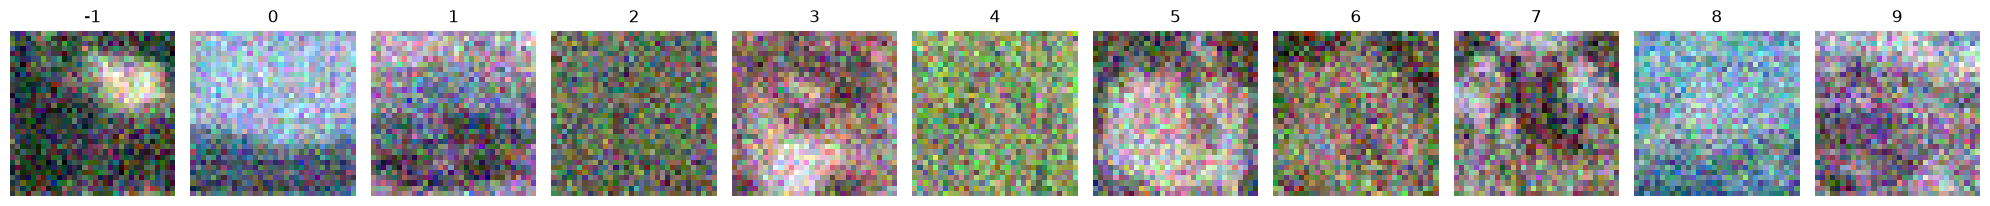

Epoch 341/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0101 - learning_rate: 0.0015
Epoch 342/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0101 - learning_rate: 0.0015
Epoch 343/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0100 - learning_rate: 0.0015
Epoch 344/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0100 - learning_rate: 0.0015
Epoch 345/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 67ms/step - noise_loss: 0.0100 - val_image_loss: 0.1006 - val_loss: 0.1041 - val_noise_loss: 0.1041 - learning_rate: 0.0015
Steps: 50/50


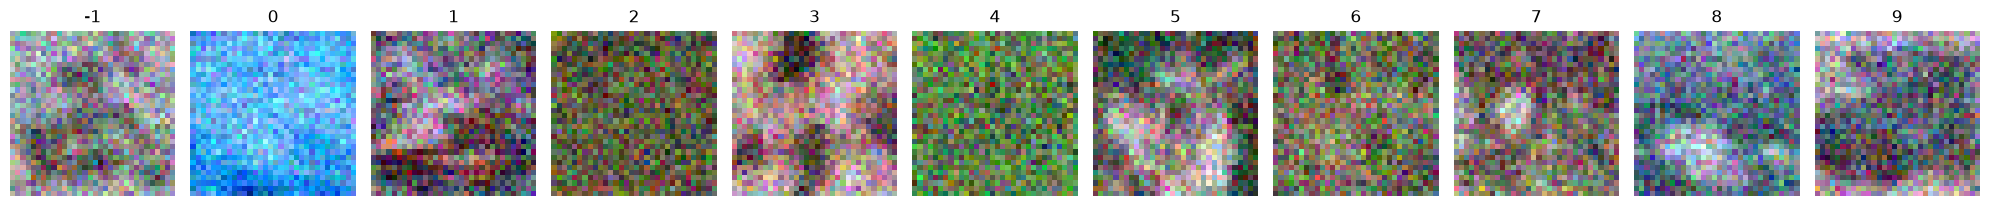

Epoch 346/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0100 - learning_rate: 0.0015
Epoch 347/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0100 - learning_rate: 0.0015
Epoch 348/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0100 - learning_rate: 0.0014
Epoch 349/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0100 - learning_rate: 0.0014
Epoch 350/350
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 69ms/step - noise_loss: 0.0100 - val_image_loss: 0.1001 - val_loss: 0.1052 - val_noise_loss: 0.1052 - learning_rate: 0.0014
Steps: 50/50


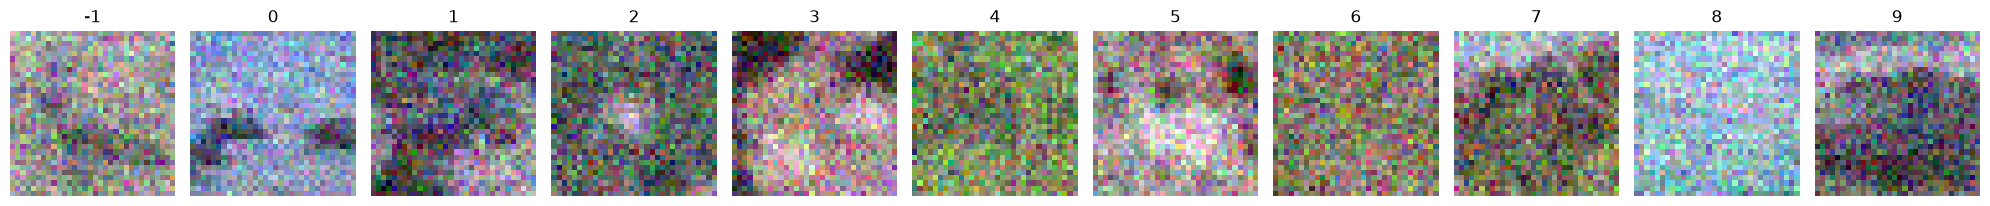

Progressive stage 8/10: changes={'timesteps': (331, 1000)}, resolution=32, sampling t in [331, 1000) range.
Epoch 351/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 32s 27ms/step - noise_loss: 0.0170 - learning_rate: 0.0014
Epoch 352/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0164 - learning_rate: 0.0014
Epoch 353/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0163 - learning_rate: 0.0014
Epoch 354/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0163 - learning_rate: 0.0014
Epoch 355/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 67ms/step - noise_loss: 0.0162 - val_image_loss: 0.0869 - val_loss: 0.0712 - val_noise_loss: 0.0712 - learning_rate: 0.0014
Steps: 50/50


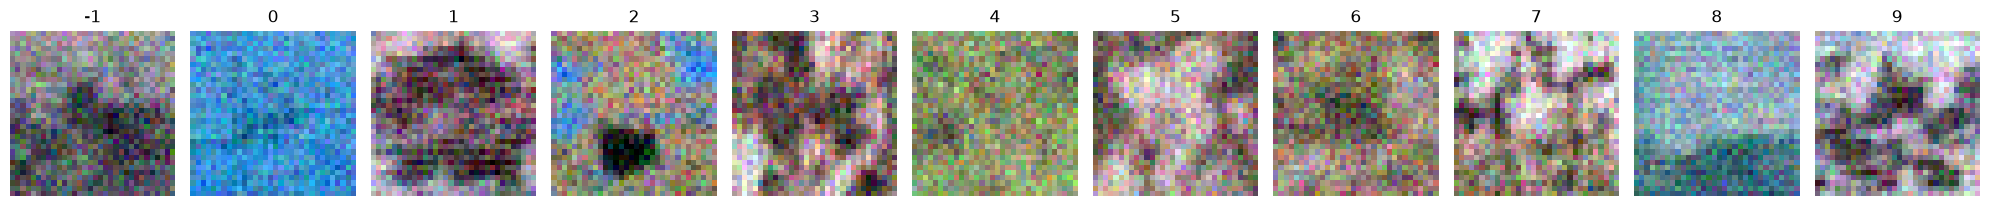

Epoch 356/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0162 - learning_rate: 0.0013
Epoch 357/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0161 - learning_rate: 0.0013
Epoch 358/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0162 - learning_rate: 0.0013
Epoch 359/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0162 - learning_rate: 0.0013
Epoch 360/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 67ms/step - noise_loss: 0.0163 - val_image_loss: 0.0833 - val_loss: 0.0700 - val_noise_loss: 0.0700 - learning_rate: 0.0013
Steps: 50/50


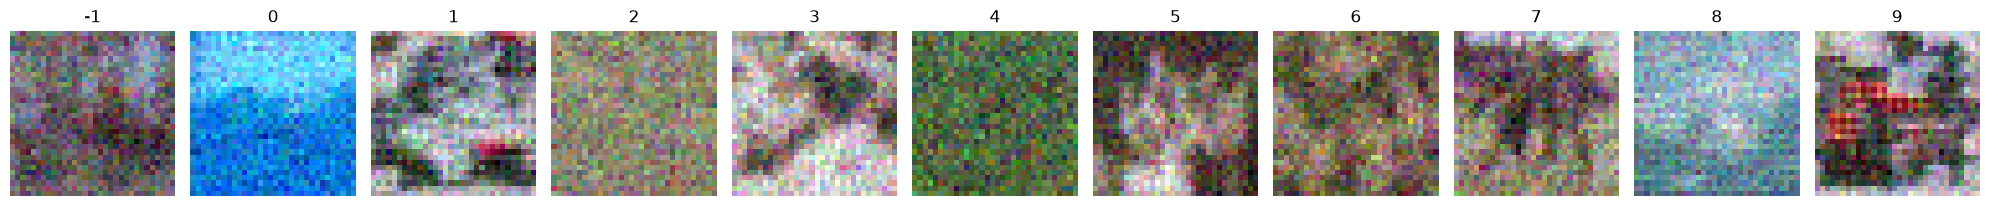

Epoch 361/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0161 - learning_rate: 0.0013
Epoch 362/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0161 - learning_rate: 0.0013
Epoch 363/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0161 - learning_rate: 0.0013
Epoch 364/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0162 - learning_rate: 0.0012
Epoch 365/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 67ms/step - noise_loss: 0.0162 - val_image_loss: 0.0836 - val_loss: 0.0671 - val_noise_loss: 0.0671 - learning_rate: 0.0012
Steps: 50/50


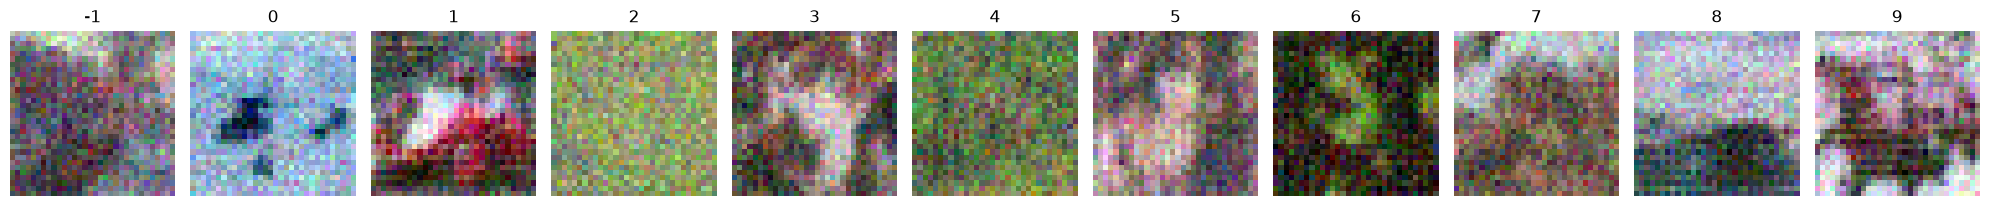

Epoch 366/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0160 - learning_rate: 0.0012
Epoch 367/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0161 - learning_rate: 0.0012
Epoch 368/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0161 - learning_rate: 0.0012
Epoch 369/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0161 - learning_rate: 0.0012
Epoch 370/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 66ms/step - noise_loss: 0.0160 - val_image_loss: 0.0842 - val_loss: 0.0685 - val_noise_loss: 0.0685 - learning_rate: 0.0012
Steps: 50/50


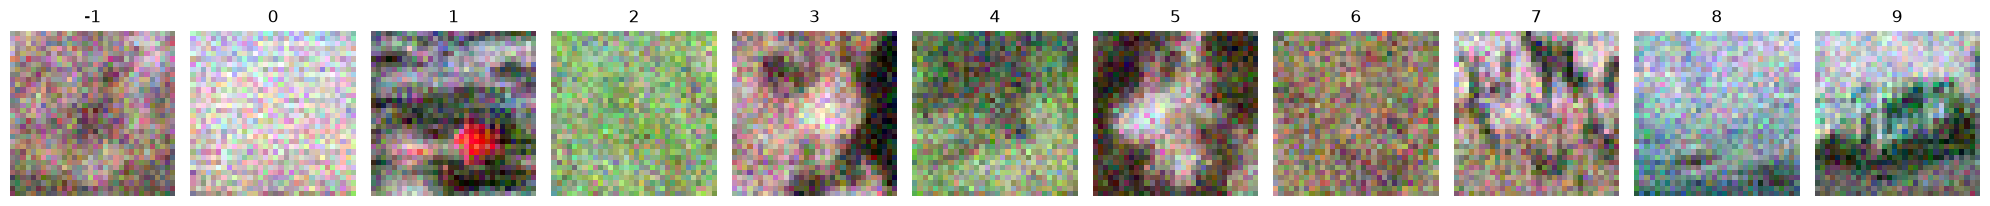

Epoch 371/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0159 - learning_rate: 0.0012
Epoch 372/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0161 - learning_rate: 0.0011
Epoch 373/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0160 - learning_rate: 0.0011
Epoch 374/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0160 - learning_rate: 0.0011
Epoch 375/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 67ms/step - noise_loss: 0.0160 - val_image_loss: 0.0833 - val_loss: 0.0671 - val_noise_loss: 0.0671 - learning_rate: 0.0011
Steps: 50/50


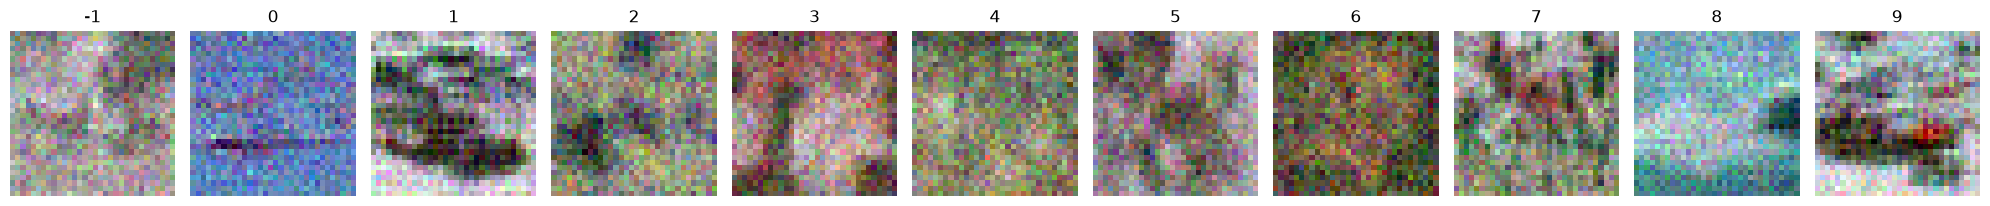

Epoch 376/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0160 - learning_rate: 0.0011
Epoch 377/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0160 - learning_rate: 0.0011
Epoch 378/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0160 - learning_rate: 0.0011
Epoch 379/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0160 - learning_rate: 0.0011
Epoch 380/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 65ms/step - noise_loss: 0.0160 - val_image_loss: 0.0826 - val_loss: 0.0695 - val_noise_loss: 0.0695 - learning_rate: 0.0011
Steps: 50/50


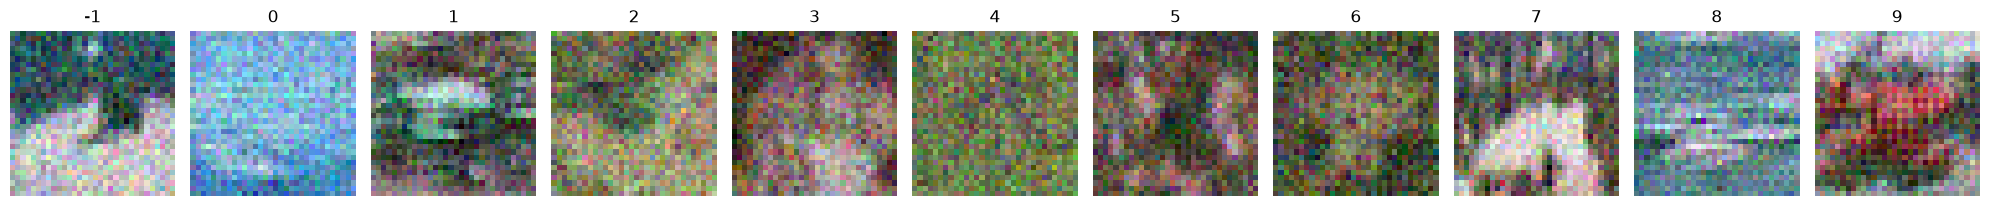

Epoch 381/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0159 - learning_rate: 0.0010
Epoch 382/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0160 - learning_rate: 0.0010
Epoch 383/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0160 - learning_rate: 0.0010
Epoch 384/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0159 - learning_rate: 0.0010
Epoch 385/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 65ms/step - noise_loss: 0.0159 - val_image_loss: 0.0835 - val_loss: 0.0706 - val_noise_loss: 0.0706 - learning_rate: 9.9859e-04
Steps: 50/50


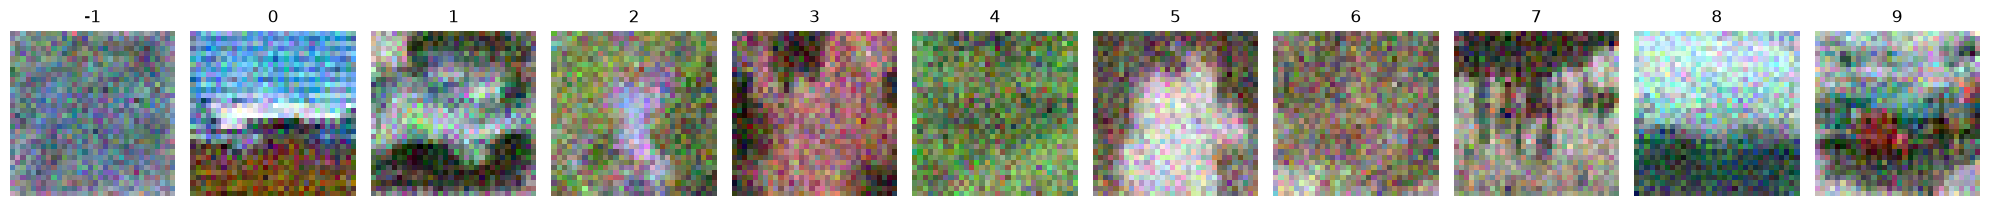

Epoch 386/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0159 - learning_rate: 9.8742e-04
Epoch 387/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0158 - learning_rate: 9.7630e-04
Epoch 388/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0159 - learning_rate: 9.6522e-04
Epoch 389/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0159 - learning_rate: 9.5419e-04
Epoch 390/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 67ms/step - noise_loss: 0.0157 - val_image_loss: 0.0835 - val_loss: 0.0694 - val_noise_loss: 0.0694 - learning_rate: 9.4321e-04
Steps: 50/50


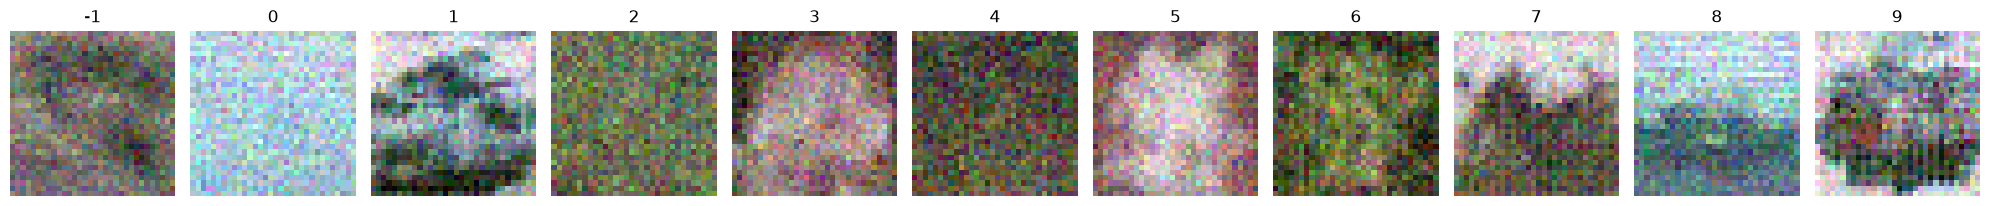

Epoch 391/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0158 - learning_rate: 9.3227e-04
Epoch 392/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0157 - learning_rate: 9.2139e-04
Epoch 393/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0159 - learning_rate: 9.1055e-04
Epoch 394/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0157 - learning_rate: 8.9977e-04
Epoch 395/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 66ms/step - noise_loss: 0.0157 - val_image_loss: 0.0844 - val_loss: 0.0697 - val_noise_loss: 0.0697 - learning_rate: 8.8903e-04
Steps: 50/50


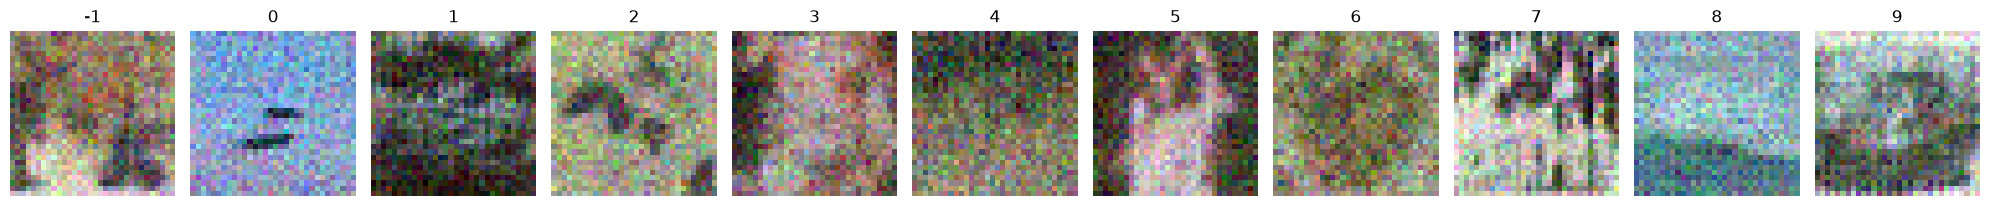

Epoch 396/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 0.0158 - learning_rate: 8.7834e-04
Epoch 397/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0158 - learning_rate: 8.6771e-04
Epoch 398/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0157 - learning_rate: 8.5712e-04
Epoch 399/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0158 - learning_rate: 8.4658e-04
Epoch 400/400
390/390 ━━━━━━━━━━━━━━━━━━━━ 25s 65ms/step - noise_loss: 0.0158 - val_image_loss: 0.0844 - val_loss: 0.0684 - val_noise_loss: 0.0684 - learning_rate: 8.3610e-04
Steps: 50/50


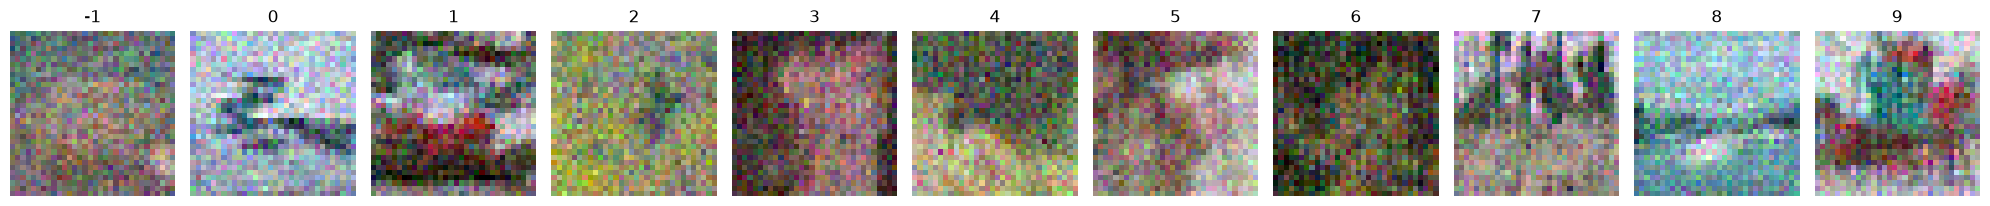

Progressive stage 9/10: changes={'timesteps': (144, 1000)}, resolution=32, sampling t in [144, 1000) range.
Epoch 401/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 33s 29ms/step - noise_loss: 0.0236 - learning_rate: 8.2567e-04
Epoch 402/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0231 - learning_rate: 8.1529e-04
Epoch 403/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0232 - learning_rate: 8.0496e-04
Epoch 404/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0231 - learning_rate: 7.9469e-04
Epoch 405/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 66ms/step - noise_loss: 0.0230 - val_image_loss: 0.0765 - val_loss: 0.0445 - val_noise_loss: 0.0445 - learning_rate: 7.8447e-04
Steps: 50/50


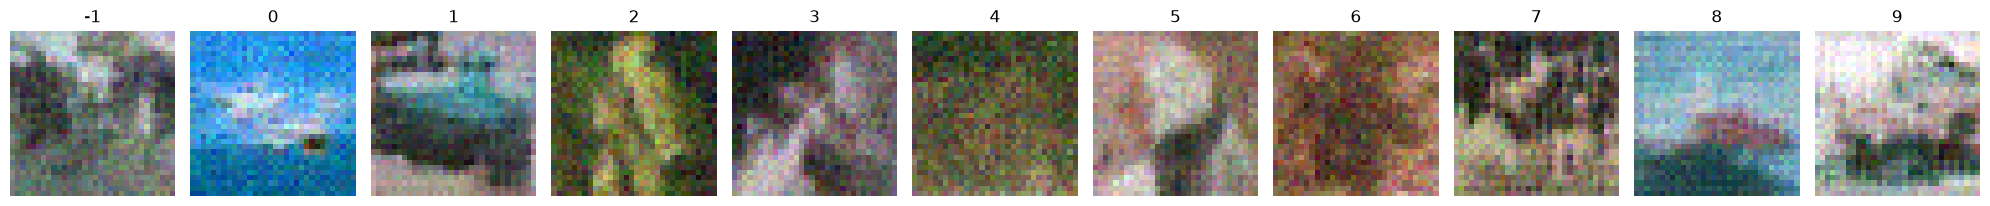

Epoch 406/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0231 - learning_rate: 7.7430e-04
Epoch 407/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0230 - learning_rate: 7.6419e-04
Epoch 408/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0228 - learning_rate: 7.5413e-04
Epoch 409/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0229 - learning_rate: 7.4412e-04
Epoch 410/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 70ms/step - noise_loss: 0.0230 - val_image_loss: 0.0785 - val_loss: 0.0423 - val_noise_loss: 0.0423 - learning_rate: 7.3417e-04
Steps: 50/50


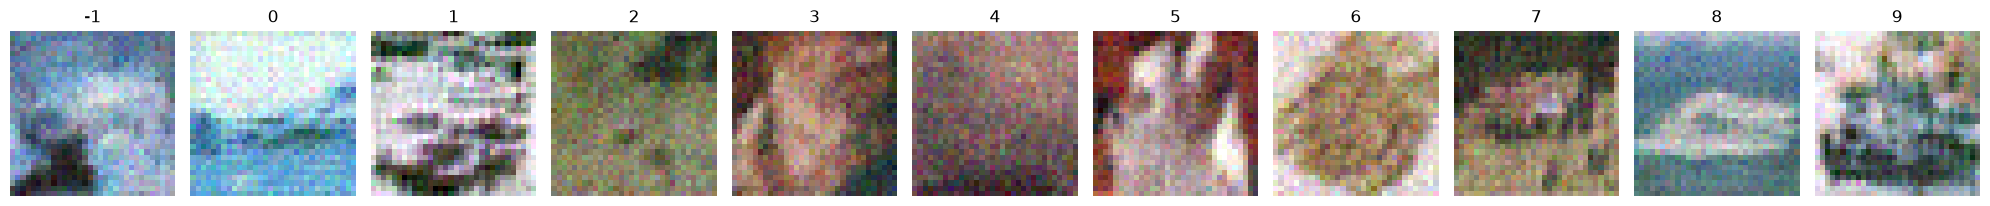

Epoch 411/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0228 - learning_rate: 7.2427e-04
Epoch 412/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0229 - learning_rate: 7.1443e-04
Epoch 413/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0228 - learning_rate: 7.0465e-04
Epoch 414/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0229 - learning_rate: 6.9492e-04
Epoch 415/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 67ms/step - noise_loss: 0.0229 - val_image_loss: 0.0774 - val_loss: 0.0422 - val_noise_loss: 0.0422 - learning_rate: 6.8525e-04
Steps: 50/50


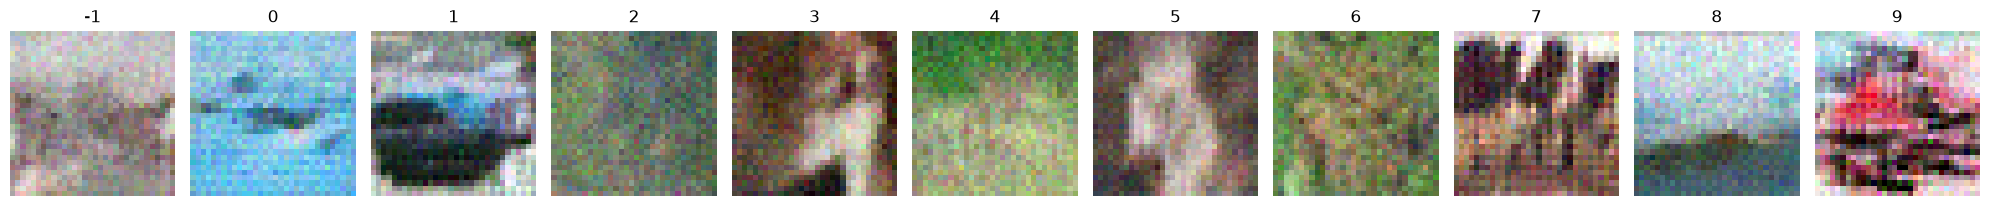

Epoch 416/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0228 - learning_rate: 6.7563e-04
Epoch 417/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0228 - learning_rate: 6.6608e-04
Epoch 418/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0227 - learning_rate: 6.5657e-04
Epoch 419/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0227 - learning_rate: 6.4713e-04
Epoch 420/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 67ms/step - noise_loss: 0.0229 - val_image_loss: 0.0768 - val_loss: 0.0410 - val_noise_loss: 0.0410 - learning_rate: 6.3775e-04
Steps: 50/50


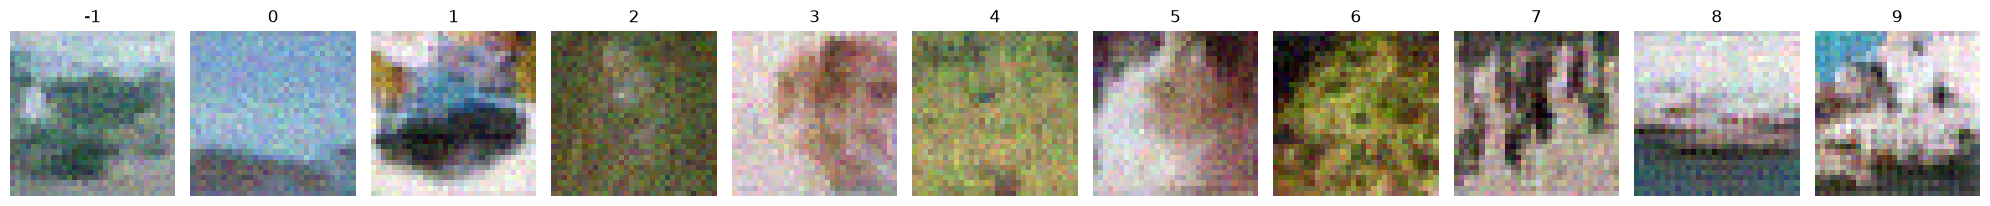

Epoch 421/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0227 - learning_rate: 6.2842e-04
Epoch 422/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - noise_loss: 0.0228 - learning_rate: 6.1915e-04
Epoch 423/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - noise_loss: 0.0229 - learning_rate: 6.0994e-04
Epoch 424/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0228 - learning_rate: 6.0079e-04
Epoch 425/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 25s 65ms/step - noise_loss: 0.0227 - val_image_loss: 0.0790 - val_loss: 0.0411 - val_noise_loss: 0.0411 - learning_rate: 5.9170e-04
Steps: 50/50


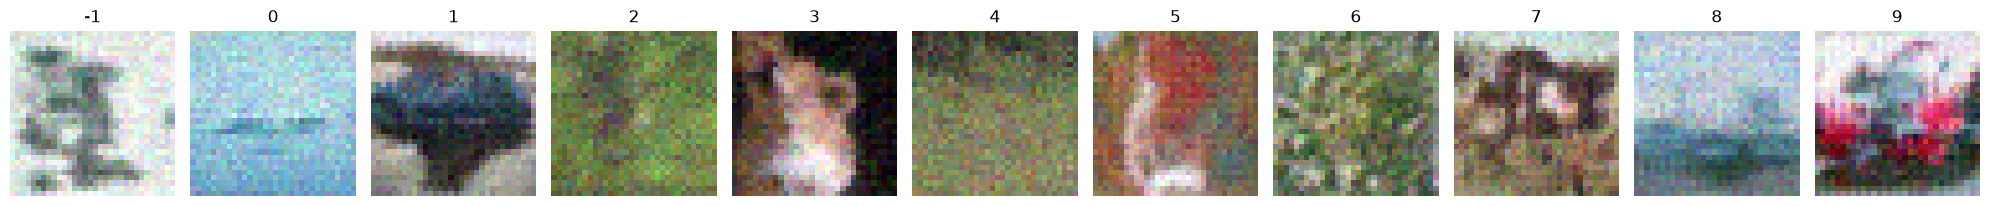

Epoch 426/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0228 - learning_rate: 5.8267e-04
Epoch 427/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0229 - learning_rate: 5.7369e-04
Epoch 428/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0227 - learning_rate: 5.6478e-04
Epoch 429/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0227 - learning_rate: 5.5593e-04
Epoch 430/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 25s 65ms/step - noise_loss: 0.0228 - val_image_loss: 0.0784 - val_loss: 0.0402 - val_noise_loss: 0.0402 - learning_rate: 5.4714e-04
Steps: 50/50


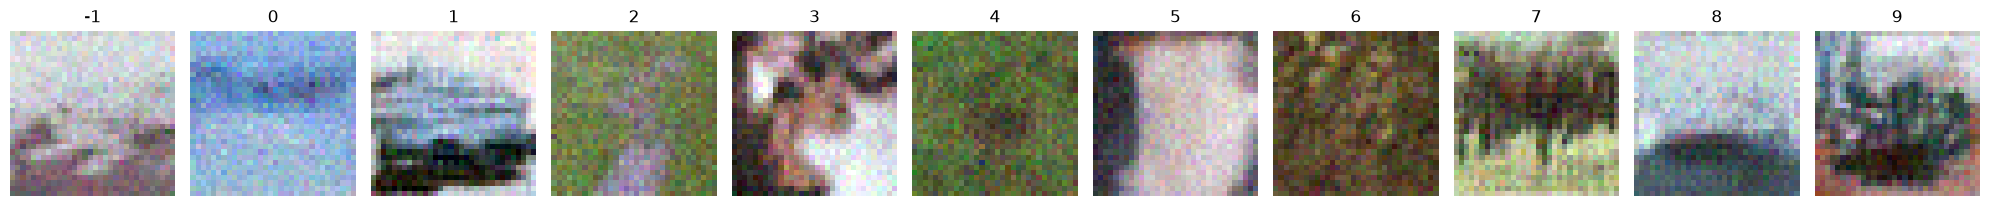

Epoch 431/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0226 - learning_rate: 5.3841e-04
Epoch 432/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0228 - learning_rate: 5.2975e-04
Epoch 433/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0227 - learning_rate: 5.2114e-04
Epoch 434/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0227 - learning_rate: 5.1260e-04
Epoch 435/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 25s 65ms/step - noise_loss: 0.0226 - val_image_loss: 0.0777 - val_loss: 0.0406 - val_noise_loss: 0.0406 - learning_rate: 5.0412e-04
Steps: 50/50


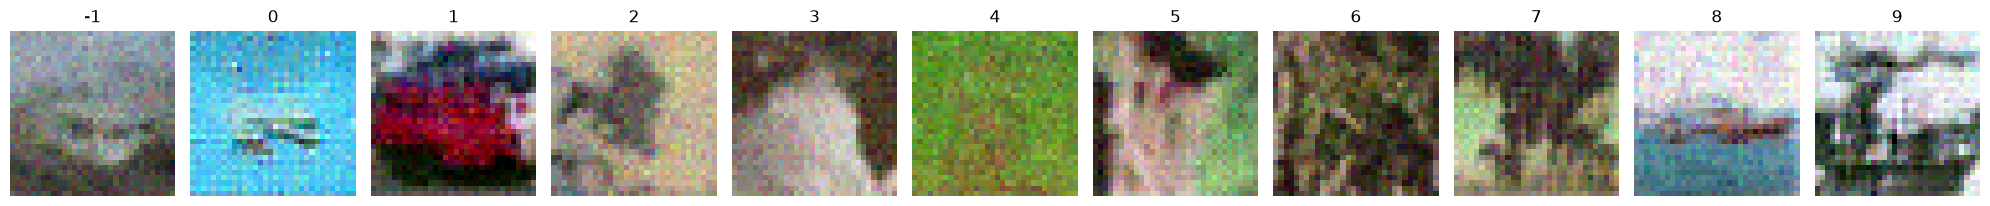

Epoch 436/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0228 - learning_rate: 4.9570e-04
Epoch 437/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0226 - learning_rate: 4.8734e-04
Epoch 438/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0226 - learning_rate: 4.7905e-04
Epoch 439/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0228 - learning_rate: 4.7082e-04
Epoch 440/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 65ms/step - noise_loss: 0.0227 - val_image_loss: 0.0776 - val_loss: 0.0408 - val_noise_loss: 0.0408 - learning_rate: 4.6266e-04
Steps: 50/50


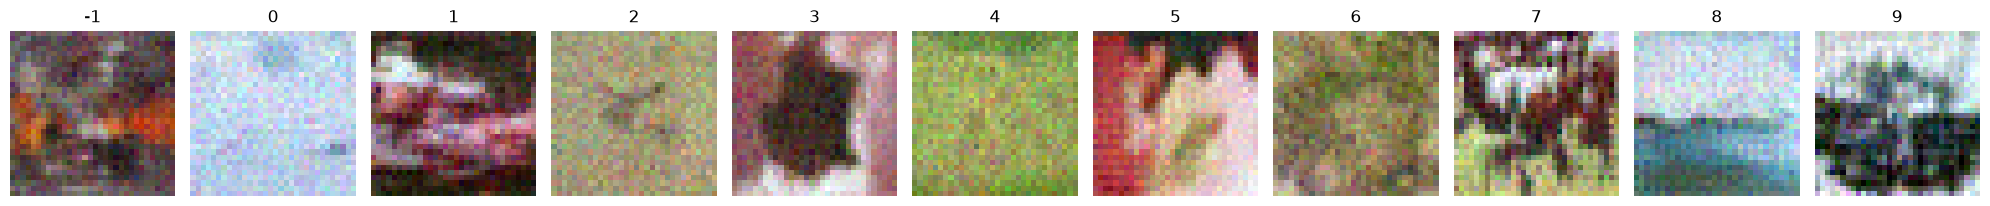

Epoch 441/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0226 - learning_rate: 4.5456e-04
Epoch 442/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0226 - learning_rate: 4.4652e-04
Epoch 443/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0226 - learning_rate: 4.3855e-04
Epoch 444/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0225 - learning_rate: 4.3064e-04
Epoch 445/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 70ms/step - noise_loss: 0.0225 - val_image_loss: 0.0778 - val_loss: 0.0407 - val_noise_loss: 0.0407 - learning_rate: 4.2280e-04
Steps: 50/50


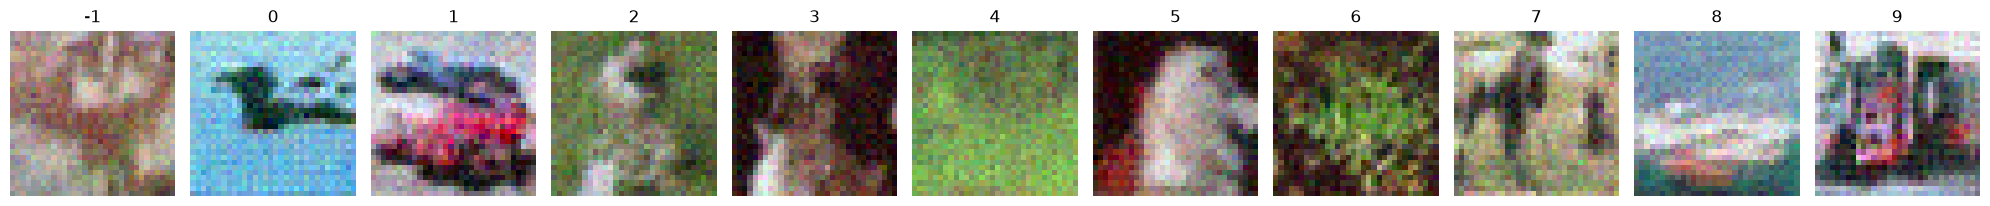

Epoch 446/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0226 - learning_rate: 4.1502e-04
Epoch 447/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0227 - learning_rate: 4.0731e-04
Epoch 448/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0226 - learning_rate: 3.9966e-04
Epoch 449/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0225 - learning_rate: 3.9208e-04
Epoch 450/450
390/390 ━━━━━━━━━━━━━━━━━━━━ 28s 71ms/step - noise_loss: 0.0225 - val_image_loss: 0.0782 - val_loss: 0.0405 - val_noise_loss: 0.0405 - learning_rate: 3.8456e-04
Steps: 50/50


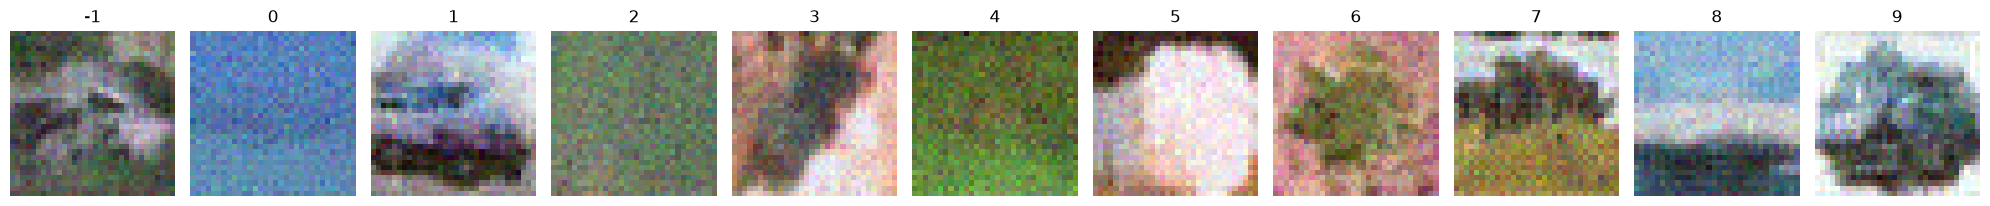

Progressive stage 10/10: changes={'timesteps': (0, 1000)}, resolution=32, sampling t in [0, 1000) range.
Epoch 451/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 33s 28ms/step - noise_loss: 0.0305 - learning_rate: 3.7712e-04
Epoch 452/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0302 - learning_rate: 3.6974e-04
Epoch 453/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0302 - learning_rate: 3.6242e-04
Epoch 454/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0300 - learning_rate: 3.5517e-04
Epoch 455/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 28s 71ms/step - noise_loss: 0.0302 - val_image_loss: 0.0783 - val_loss: 0.0321 - val_noise_loss: 0.0321 - learning_rate: 3.4800e-04
Steps: 50/50


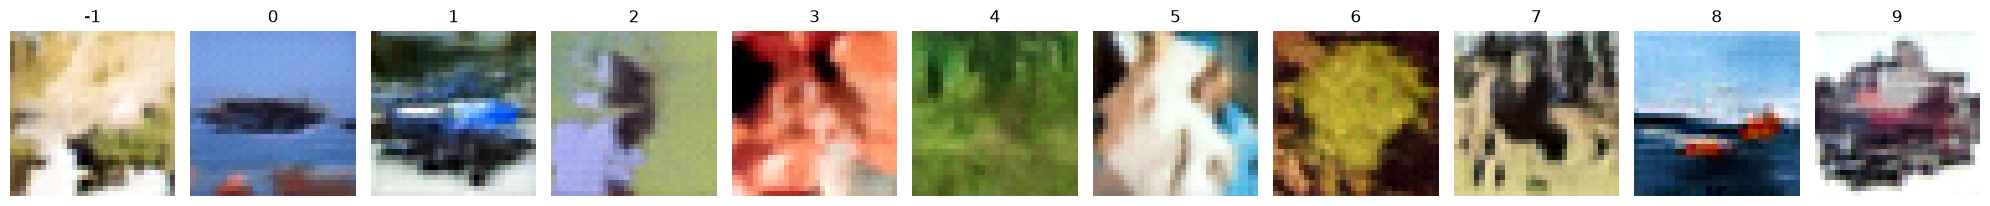

Epoch 456/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0301 - learning_rate: 3.4088e-04
Epoch 457/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0304 - learning_rate: 3.3384e-04
Epoch 458/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0301 - learning_rate: 3.2686e-04
Epoch 459/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0302 - learning_rate: 3.1996e-04
Epoch 460/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - noise_loss: 0.0301 - val_image_loss: 0.0764 - val_loss: 0.0322 - val_noise_loss: 0.0322 - learning_rate: 3.1312e-04
Steps: 50/50


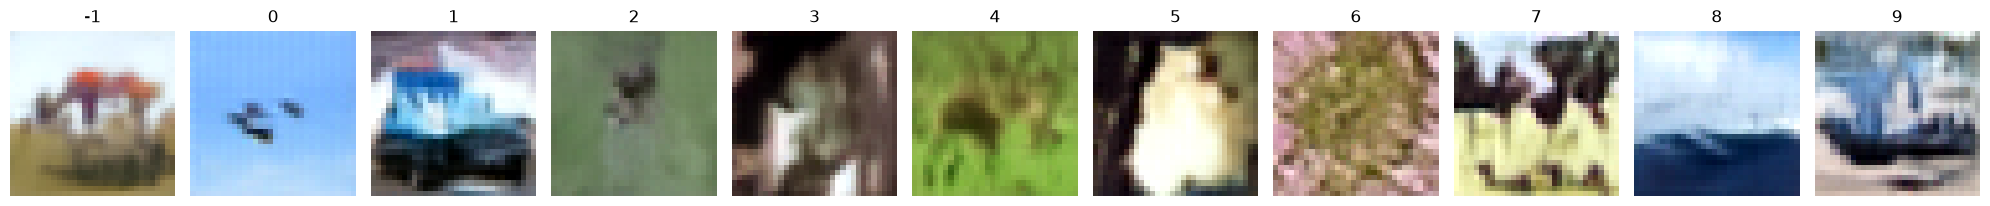

Epoch 461/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 0.0303 - learning_rate: 3.0635e-04
Epoch 462/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 0.0301 - learning_rate: 2.9965e-04
Epoch 463/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0301 - learning_rate: 2.9302e-04
Epoch 464/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0300 - learning_rate: 2.8645e-04
Epoch 465/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - noise_loss: 0.0302 - val_image_loss: 0.0759 - val_loss: 0.0320 - val_noise_loss: 0.0320 - learning_rate: 2.7996e-04
Steps: 50/50


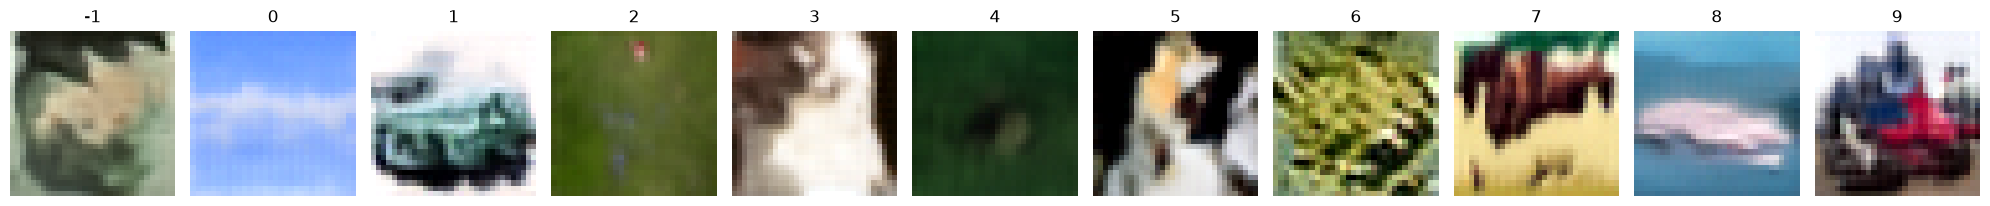

Epoch 466/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0299 - learning_rate: 2.7354e-04
Epoch 467/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0300 - learning_rate: 2.6719e-04
Epoch 468/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0302 - learning_rate: 2.6090e-04
Epoch 469/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0300 - learning_rate: 2.5469e-04
Epoch 470/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - noise_loss: 0.0299 - val_image_loss: 0.0767 - val_loss: 0.0318 - val_noise_loss: 0.0318 - learning_rate: 2.4855e-04
Steps: 50/50


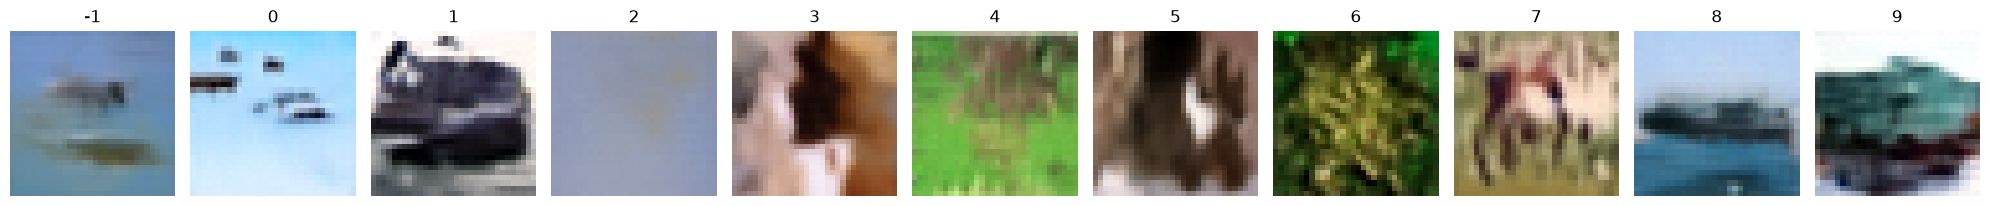

Epoch 471/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - noise_loss: 0.0299 - learning_rate: 2.4248e-04
Epoch 472/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 0.0298 - learning_rate: 2.3648e-04
Epoch 473/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0299 - learning_rate: 2.3056e-04
Epoch 474/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0300 - learning_rate: 2.2470e-04
Epoch 475/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - noise_loss: 0.0301 - val_image_loss: 0.0763 - val_loss: 0.0323 - val_noise_loss: 0.0323 - learning_rate: 2.1892e-04
Steps: 50/50


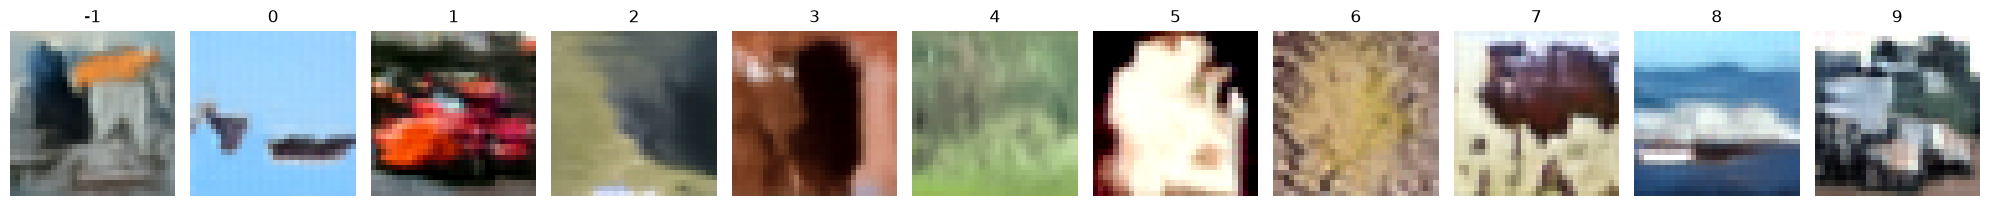

Epoch 476/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 0.0298 - learning_rate: 2.1320e-04
Epoch 477/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - noise_loss: 0.0300 - learning_rate: 2.0756e-04
Epoch 478/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - noise_loss: 0.0299 - learning_rate: 2.0200e-04
Epoch 479/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 0.0299 - learning_rate: 1.9650e-04
Epoch 480/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 13s 33ms/step - noise_loss: 0.0299 - val_image_loss: 0.0764 - val_loss: 0.0320 - val_noise_loss: 0.0320 - learning_rate: 1.9108e-04
Steps: 50/50


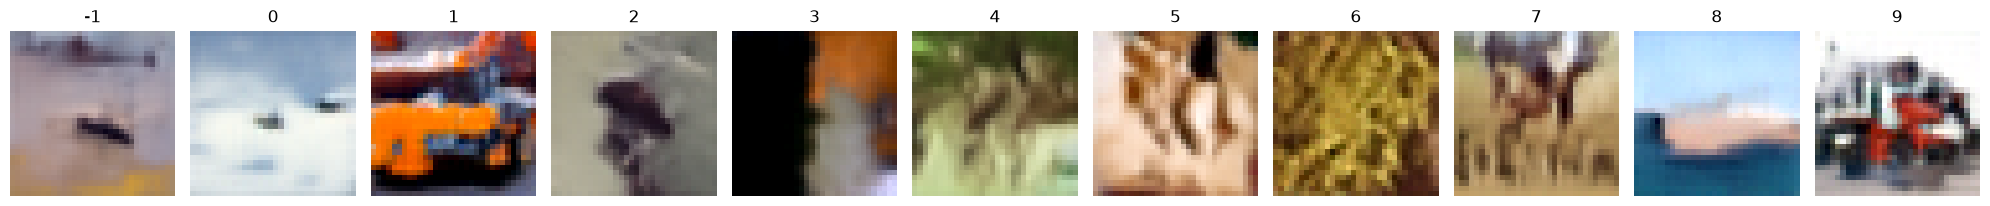

Epoch 481/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 0.0300 - learning_rate: 1.8573e-04
Epoch 482/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0298 - learning_rate: 1.8045e-04
Epoch 483/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0299 - learning_rate: 1.7525e-04
Epoch 484/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0299 - learning_rate: 1.7012e-04
Epoch 485/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - noise_loss: 0.0299 - val_image_loss: 0.0780 - val_loss: 0.0317 - val_noise_loss: 0.0317 - learning_rate: 1.6506e-04
Steps: 50/50


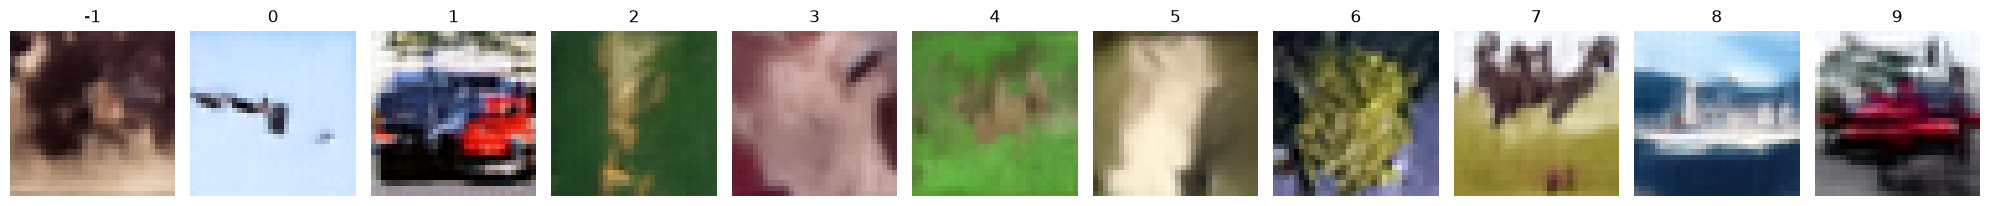

Epoch 486/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0299 - learning_rate: 1.6008e-04
Epoch 487/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0298 - learning_rate: 1.5517e-04
Epoch 488/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0298 - learning_rate: 1.5033e-04
Epoch 489/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0298 - learning_rate: 1.4557e-04
Epoch 490/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - noise_loss: 0.0298 - val_image_loss: 0.0766 - val_loss: 0.0316 - val_noise_loss: 0.0316 - learning_rate: 1.4088e-04
Steps: 50/50


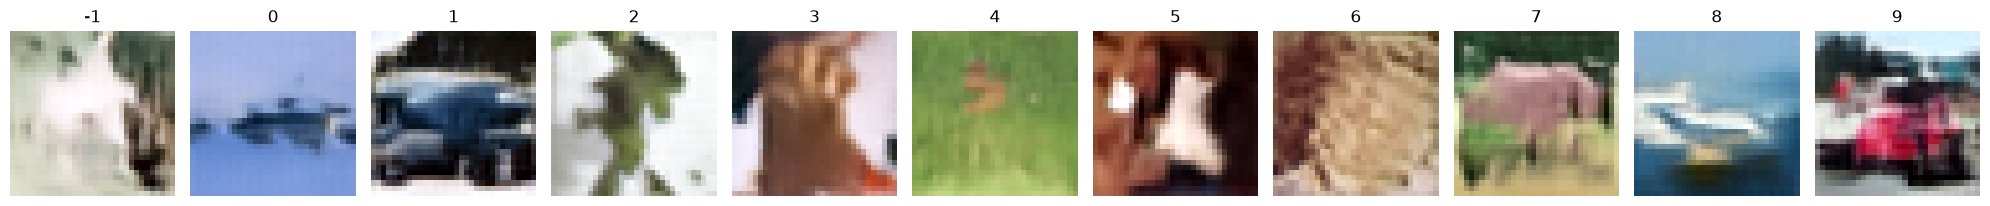

Epoch 491/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0297 - learning_rate: 1.3627e-04
Epoch 492/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0300 - learning_rate: 1.3173e-04
Epoch 493/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0299 - learning_rate: 1.2727e-04
Epoch 494/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0297 - learning_rate: 1.2288e-04
Epoch 495/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - noise_loss: 0.0299 - val_image_loss: 0.0753 - val_loss: 0.0322 - val_noise_loss: 0.0322 - learning_rate: 1.1857e-04
Steps: 50/50


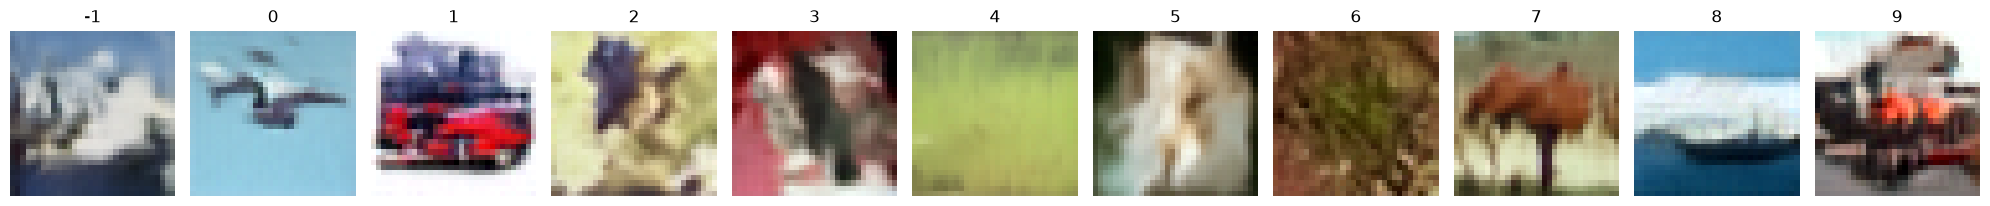

Epoch 496/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0297 - learning_rate: 1.1433e-04
Epoch 497/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0298 - learning_rate: 1.1016e-04
Epoch 498/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0299 - learning_rate: 1.0608e-04
Epoch 499/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0298 - learning_rate: 1.0206e-04
Epoch 500/500
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - noise_loss: 0.0298 - val_image_loss: 0.0757 - val_loss: 0.0324 - val_noise_loss: 0.0324 - learning_rate: 9.8128e-05
Steps: 50/50


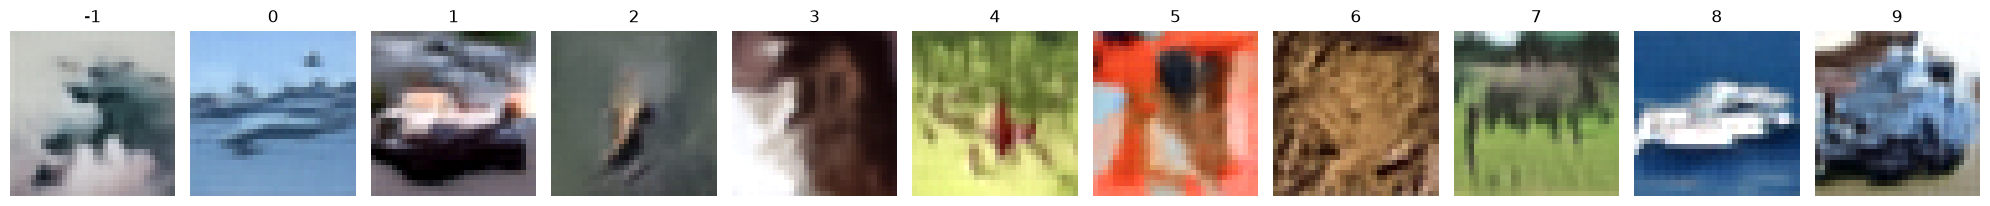

Progressive stage final/full-task: changes={'timesteps': (0, 1000), 'resolution': 32}, resolution=32, sampling t in [0, 1000) range.
Epoch 501/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0298 - learning_rate: 9.4268e-05
Epoch 502/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0298 - learning_rate: 9.0483e-05
Epoch 503/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0299 - learning_rate: 8.6775e-05
Epoch 504/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0297 - learning_rate: 8.3143e-05
Epoch 505/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - noise_loss: 0.0296 - val_image_loss: 0.0761 - val_loss: 0.0320 - val_noise_loss: 0.0320 - learning_rate: 7.9587e-05
Steps: 50/50


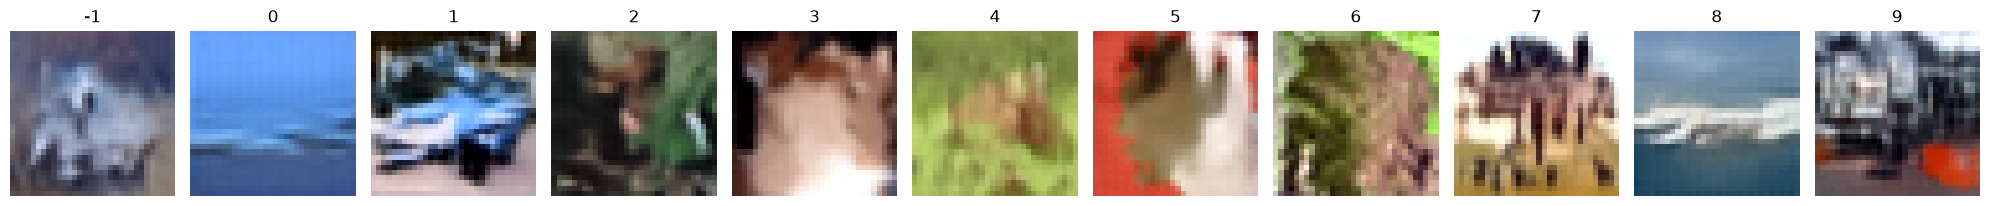

Epoch 506/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0298 - learning_rate: 7.6107e-05
Epoch 507/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0298 - learning_rate: 7.2705e-05
Epoch 508/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0300 - learning_rate: 6.9378e-05
Epoch 509/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0296 - learning_rate: 6.6129e-05
Epoch 510/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - noise_loss: 0.0300 - val_image_loss: 0.0759 - val_loss: 0.0321 - val_noise_loss: 0.0321 - learning_rate: 6.2956e-05
Steps: 50/50


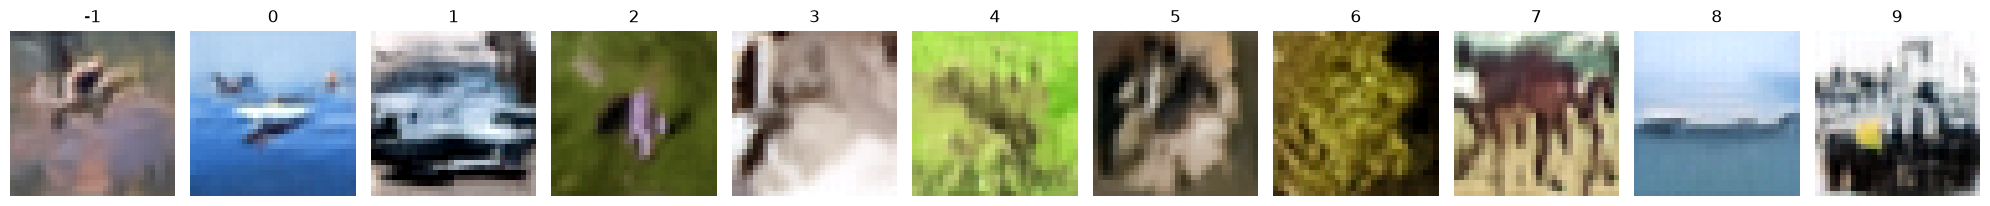

Epoch 511/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0299 - learning_rate: 5.9861e-05
Epoch 512/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0298 - learning_rate: 5.6842e-05
Epoch 513/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0296 - learning_rate: 5.3901e-05
Epoch 514/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0295 - learning_rate: 5.1037e-05
Epoch 515/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - noise_loss: 0.0298 - val_image_loss: 0.0778 - val_loss: 0.0318 - val_noise_loss: 0.0318 - learning_rate: 4.8250e-05
Steps: 50/50


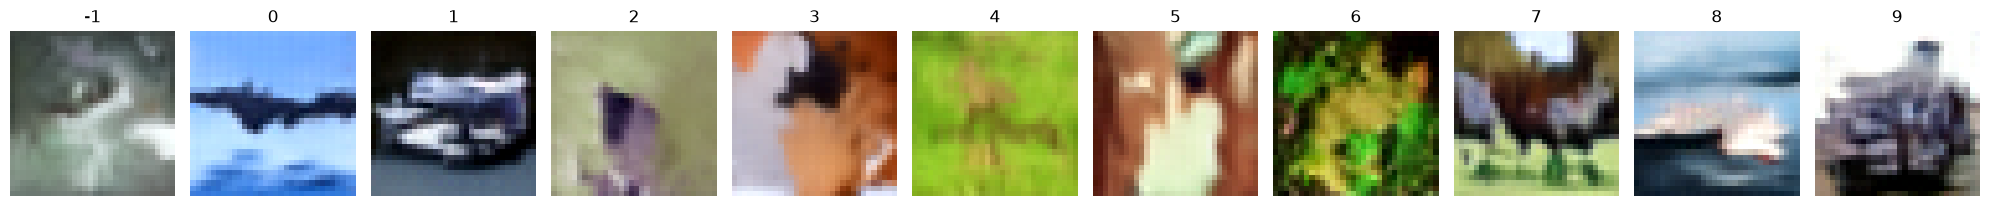

Epoch 516/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0299 - learning_rate: 4.5541e-05
Epoch 517/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0295 - learning_rate: 4.2909e-05
Epoch 518/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0300 - learning_rate: 4.0355e-05
Epoch 519/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0296 - learning_rate: 3.7879e-05
Epoch 520/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - noise_loss: 0.0299 - val_image_loss: 0.0785 - val_loss: 0.0318 - val_noise_loss: 0.0318 - learning_rate: 3.5480e-05
Steps: 50/50


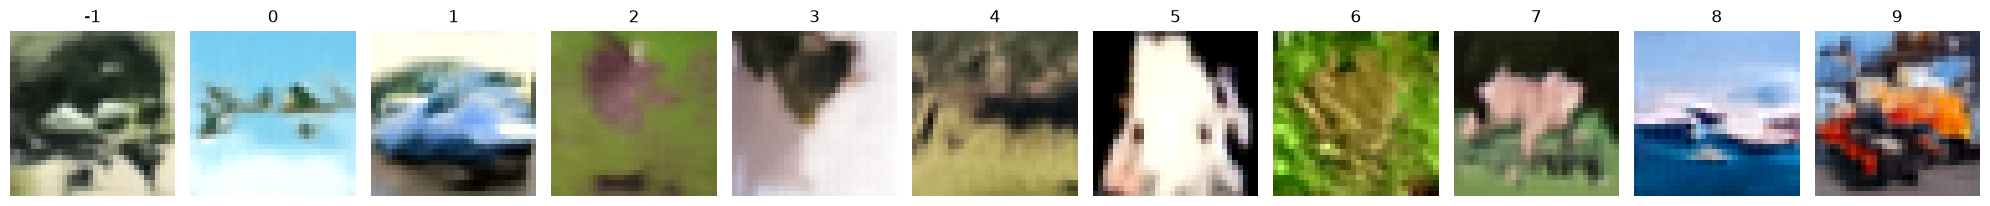

Epoch 521/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0298 - learning_rate: 3.3160e-05
Epoch 522/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0299 - learning_rate: 3.0917e-05
Epoch 523/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0297 - learning_rate: 2.8752e-05
Epoch 524/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0298 - learning_rate: 2.6666e-05
Epoch 525/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - noise_loss: 0.0299 - val_image_loss: 0.0788 - val_loss: 0.0312 - val_noise_loss: 0.0312 - learning_rate: 2.4658e-05
Steps: 50/50


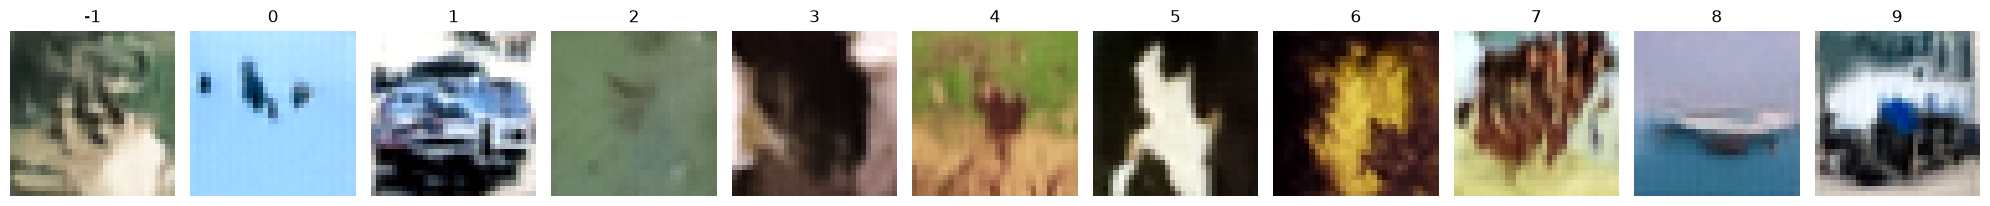

Epoch 526/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0297 - learning_rate: 2.2728e-05
Epoch 527/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0296 - learning_rate: 2.0876e-05
Epoch 528/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0299 - learning_rate: 1.9102e-05
Epoch 529/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0298 - learning_rate: 1.7407e-05
Epoch 530/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - noise_loss: 0.0298 - val_image_loss: 0.0787 - val_loss: 0.0320 - val_noise_loss: 0.0320 - learning_rate: 1.5791e-05
Steps: 50/50


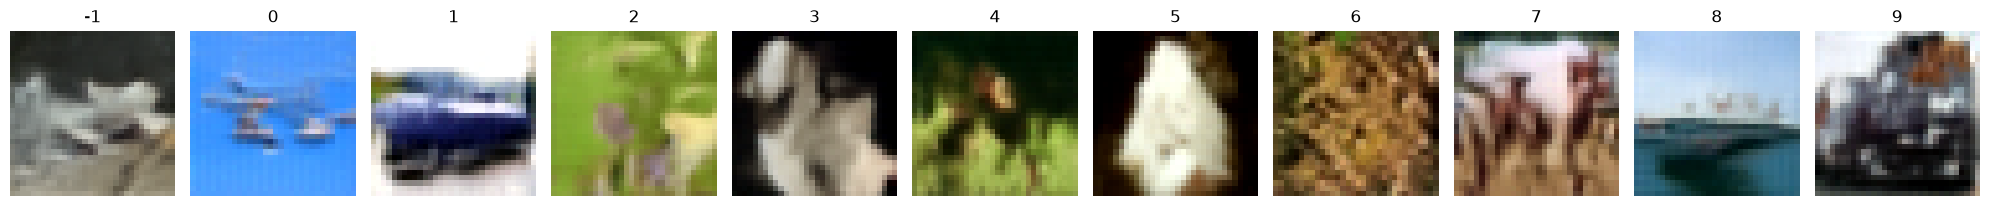

Epoch 531/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0297 - learning_rate: 1.4252e-05
Epoch 532/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0297 - learning_rate: 1.2793e-05
Epoch 533/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0298 - learning_rate: 1.1412e-05
Epoch 534/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0298 - learning_rate: 1.0110e-05
Epoch 535/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - noise_loss: 0.0297 - val_image_loss: 0.0773 - val_loss: 0.0322 - val_noise_loss: 0.0322 - learning_rate: 8.8863e-06
Steps: 50/50


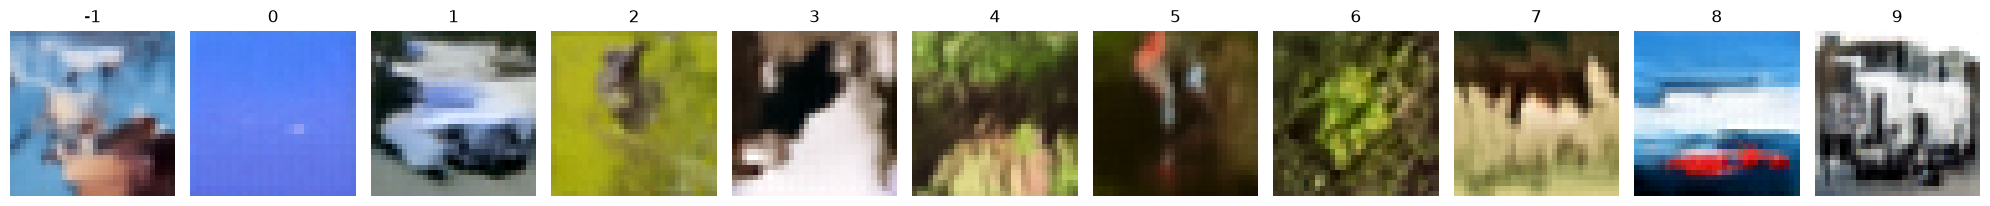

Epoch 536/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0298 - learning_rate: 7.7416e-06
Epoch 537/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0298 - learning_rate: 6.6757e-06
Epoch 538/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0298 - learning_rate: 5.6885e-06
Epoch 539/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0297 - learning_rate: 4.7803e-06
Epoch 540/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - noise_loss: 0.0298 - val_image_loss: 0.0787 - val_loss: 0.0317 - val_noise_loss: 0.0317 - learning_rate: 3.9509e-06
Steps: 50/50


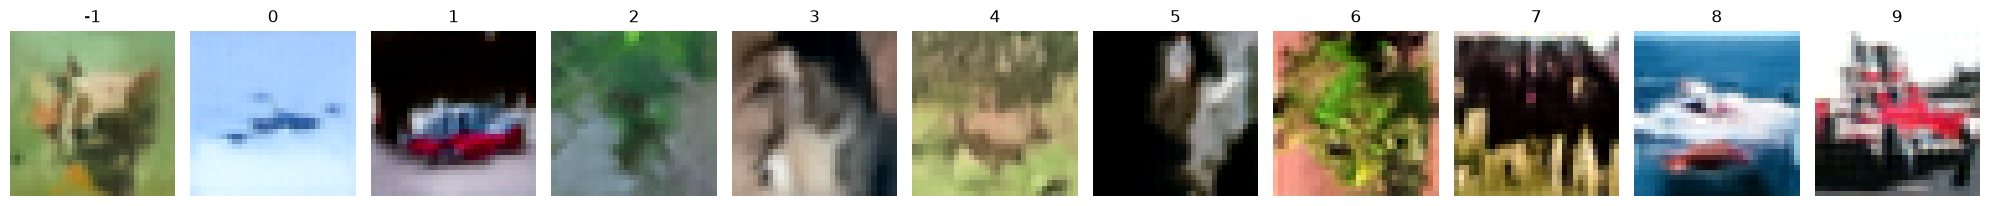

Epoch 541/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0298 - learning_rate: 3.2003e-06
Epoch 542/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0297 - learning_rate: 2.5287e-06
Epoch 543/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0296 - learning_rate: 1.9362e-06
Epoch 544/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0298 - learning_rate: 1.4226e-06
Epoch 545/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - noise_loss: 0.0297 - val_image_loss: 0.0769 - val_loss: 0.0322 - val_noise_loss: 0.0322 - learning_rate: 9.8793e-07
Steps: 50/50


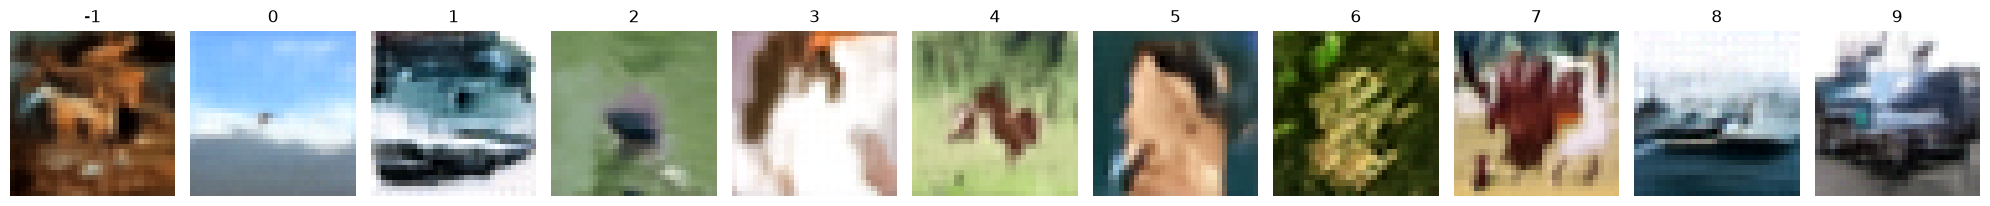

Epoch 546/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0298 - learning_rate: 6.3229e-07
Epoch 547/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0298 - learning_rate: 3.5564e-07
Epoch 548/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0297 - learning_rate: 1.5811e-07
Epoch 549/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0298 - learning_rate: 3.9564e-08
Epoch 550/550
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - noise_loss: 0.0297 - val_image_loss: 0.0781 - val_loss: 0.0319 - val_noise_loss: 0.0319 - learning_rate: 0.0000e+00
Steps: 50/50


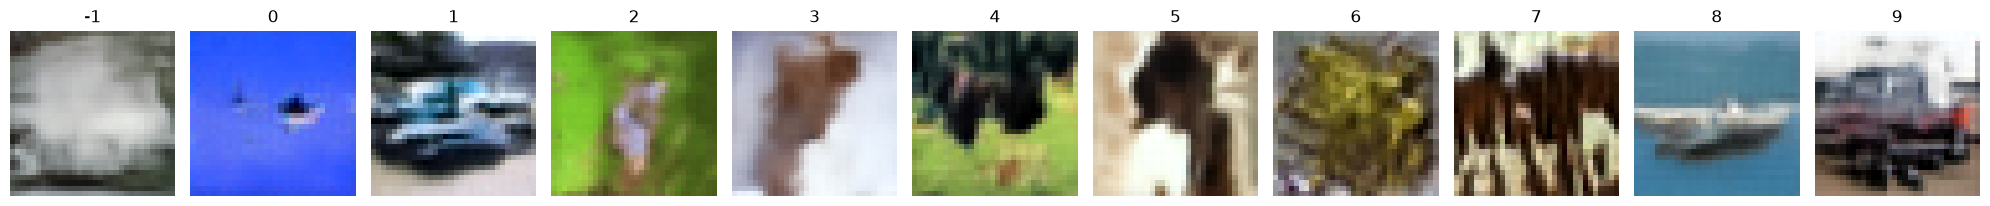

In [8]:
history = model.fit_progressively(
    stage_tasks="timesteps_only", 
    stages_num=stages_num, 
    x=trainset, 
    stage_epochs=epochs, 
    validation_data=valset, 
    callbacks=callbacks_list, 
    validation_freq=val_freq
).history

## Save weights


In [9]:
model.save_weights("./files/models/CIFAR10 DiT/model.weights.h5")

## Evaluate EMA and raw networks


In [10]:
model.evaluate(valset, network_name="ema")

79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - image_loss: 0.0771 - loss: 0.0322 - noise_loss: 0.0322


[<tf.Tensor: shape=(), dtype=float32, numpy=0.032244689762592316>,
 <tf.Tensor: shape=(), dtype=float32, numpy=0.032244689762592316>,
 <tf.Tensor: shape=(), dtype=float32, numpy=0.07709334790706635>]

In [11]:
model.evaluate(valset, network_name="raw")

79/79 ━━━━━━━━━━━━━━━━━━━━ 16s 93ms/step - image_loss: 0.0786 - loss: 0.0315 - noise_loss: 0.0315


[<tf.Tensor: shape=(), dtype=float32, numpy=0.03151337429881096>,
 <tf.Tensor: shape=(), dtype=float32, numpy=0.03151337429881096>,
 <tf.Tensor: shape=(), dtype=float32, numpy=0.07864744961261749>]

## Class-conditional samples


Steps: 1000/1000


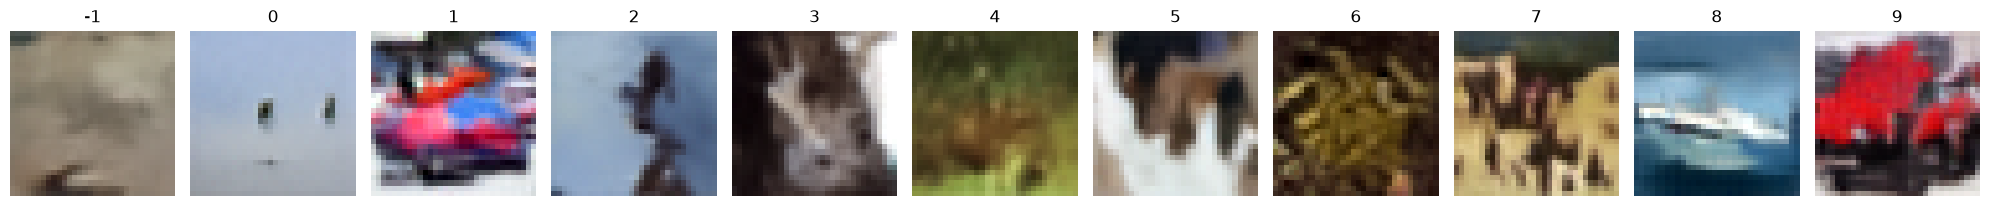

In [12]:
from common.utils import plot_images


imgs = model.sample(
    add_null_label=True, 
    scale=3., 
    eta=1., 
    steps=1_000, 
    verbose=True
)
plot_images(imgs, has_null_label=True)

Steps: 1000/1000


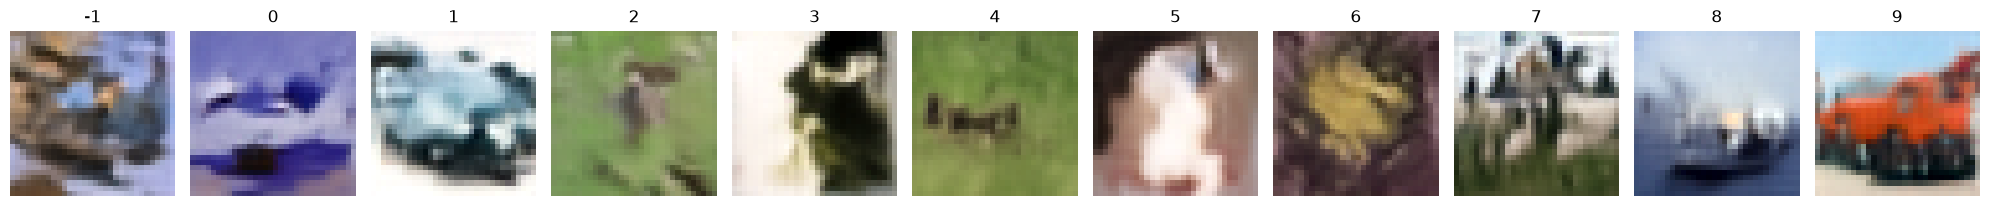

In [13]:
imgs = model.sample(
    add_null_label=True, 
    scale=3., 
    steps=1_000, 
    verbose=True
)
plot_images(imgs, has_null_label=True)

Steps: 50/50


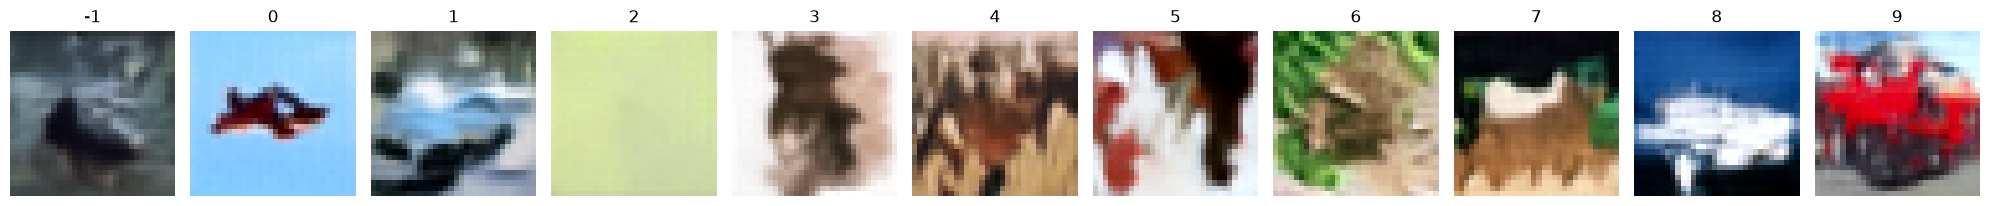

In [14]:
imgs = model.sample(
    add_null_label=True, 
    scale=3., 
    verbose=True
)
plot_images(imgs, has_null_label=True)

Steps: 50/50


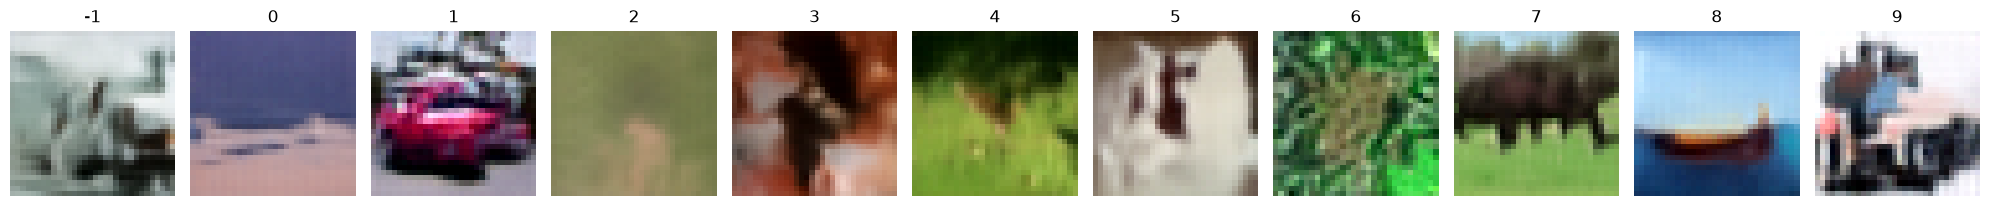

In [15]:
imgs = model.sample(
    add_null_label=True, 
    scale=4., 
    verbose=True
)
plot_images(imgs, has_null_label=True)

## Training history


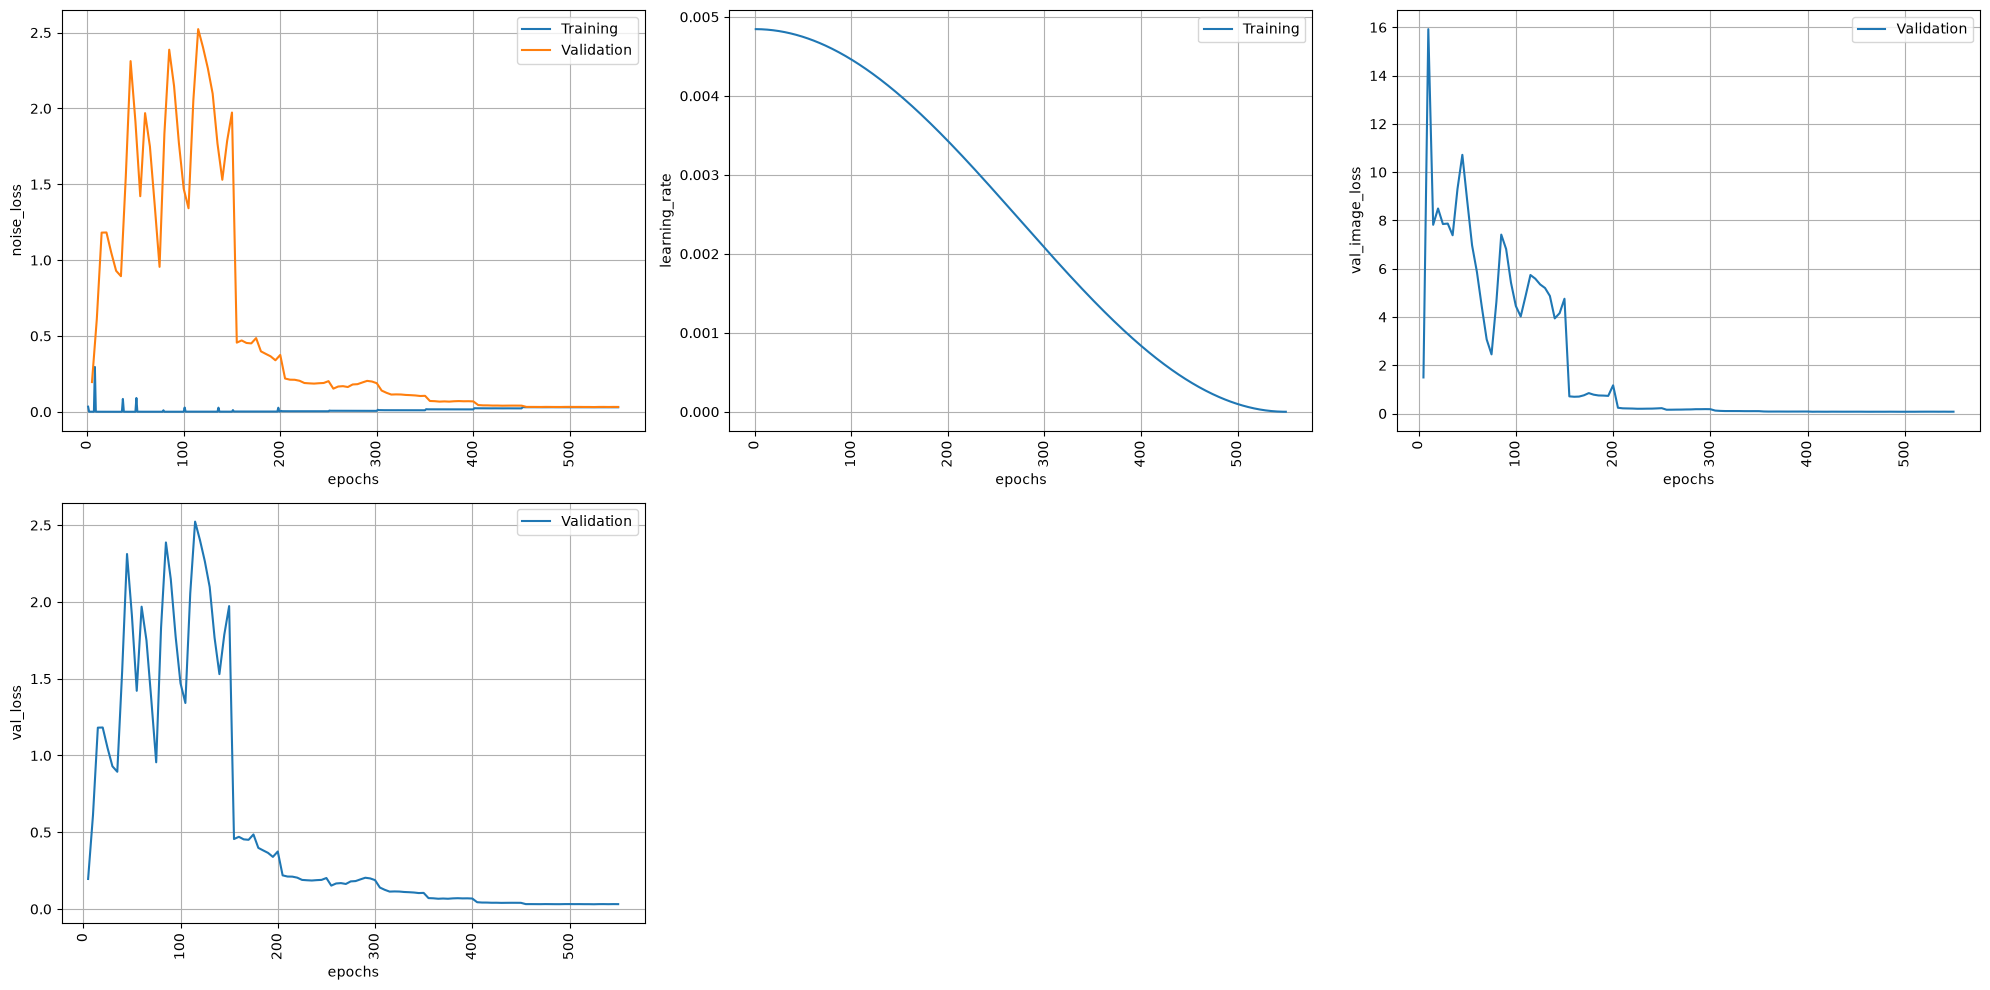

In [16]:
from common.utils import plot_history


plot_history(history, show_all_x_ticks=False)

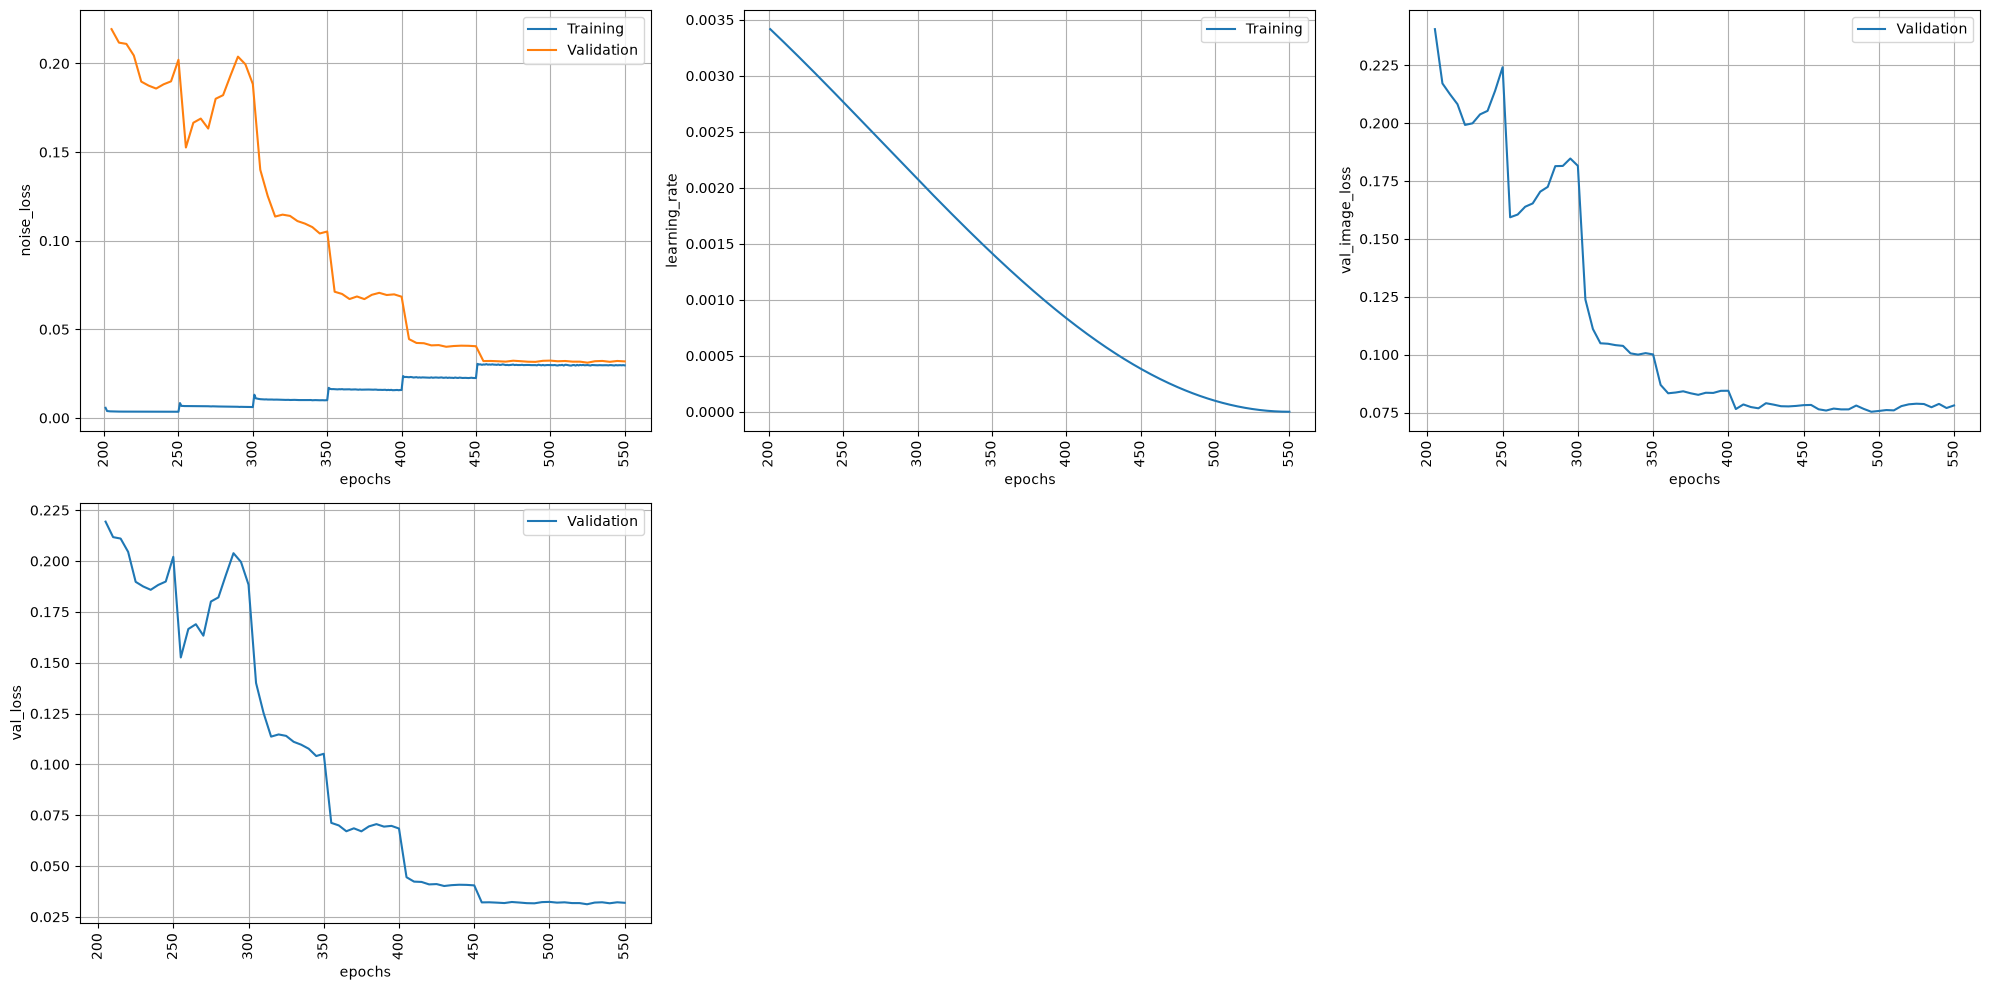

In [18]:
plot_history(history, show_all_x_ticks=False, range_=(200, None))